## Introducción

Importar paquetes.

In [1]:
import time
from datetime import datetime
import pandas as pd
import re

import torch
import torch.nn as nn
import torch.nn.functional as actF

import torch_geometric.nn as pyg_nn
import torch_geometric.utils as pyg_utils

import networkx as nx
import numpy as np
import torch.optim as optim

import torch_geometric.transforms as T

from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

/home/pedro/miniconda3/envs/envml/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Cargar datos. Considero solamente datos de la subcuenca con punto de cierre en la estación de Florída.

In [ ]:
data_folder = "../data/Datos Variantes/datos_tscf_con_florida/"

df_data_all = pd.read_parquet(data_folder+"SLC_all_data_2011_2022.parquet")
df_data_all = df_data_all.drop(columns=["[Florida (Puente Ruta 5)] Nivel de agua (h) [m]"]) # Drop nivel (= Caudal)
df_data_all

,[Florida (Puente Ruta 5)] Caudal (Q) [m3/s],[INIA Las Brujas] Evapotranspiracion Penman (ET) [mm],[INIA Las Brujas] Heliofania (Hel) [hs],[INIA Las Brujas] Humedad relativa media (HR) [%],[INIA Las Brujas] Radiacion solar (RS) [cal/cm2/dia],[INIA Las Brujas] Temperatura del aire media (TA) [ºC(24hs)],[INIA Las Brujas] Temperatura del aire maxima (TA) [ºC],[INIA Las Brujas] Temperatura del aire minima (TA) [ºC],[INIA Las Brujas] Velocidad del viento (VV) [2m/km/24h],[Cerro Colorado] Precipitacion (P) [mm],[Florida] Precipitacion (P) [mm],[La Cruz] Precipitacion (P) [mm],[Reboledo] Precipitacion (P) [mm],[San Gabriel] Precipitacion (P) [mm],[Sarandi Grande] Precipitacion (P) [mm]
date,,,,,,,,,,,,,,,
2011-01-01,0.347,5.9,9.9,70.0,576.7,22.6,28.2,17.5,205.0,0.0,0.0,0.0,0.0,0.0,0.0
2011-01-02,0.333,5.9,9.3,72.0,555.6,23.2,29.4,18.4,223.4,0.0,1.0,1.5,0.0,0.0,0.0
2011-01-03,0.353,6.6,9.8,61.0,572.6,23.8,29.6,19.9,216.0,0.0,0.0,0.0,0.0,0.0,0.0
2011-01-04,0.383,3.9,2.2,72.0,308.1,23.0,28.2,18.9,165.9,0.0,0.0,0.0,0.0,0.0,0.0
2011-01-05,0.383,4.1,5.2,77.0,412.1,23.4,30.3,19.6,80.5,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2022-03-24,0.084,2.5,5.9,74.0,329.9,18.5,23.2,11.8,85.1,2.0,3.0,3.0,2.0,4.0,10.0
2022-03-25,0.062,1.5,2.8,92.0,239.1,13.9,18.6,11.2,112.2,3.0,4.2,5.0,3.0,6.0,7.0
2022-03-26,0.057,1.7,2.2,89.0,220.3,17.4,21.7,12.7,113.8,0.0,1.2,1.0,0.0,2.0,0.0


## Plot graph

In [181]:
import networkx as nx
import matplotlib.pyplot as plt
from torch_geometric.utils import to_networkx

def plot_pyg_graph(data, col_to_idx):

    # Reverse mapping
    idx_to_col = {i: c for c, i in col_to_idx.items()}

    # Convert to networkx
    G = to_networkx(
        data,
        to_undirected=True
    )

    # Labels
    labels = {
        i: idx_to_col[i]
        for i in G.nodes()
    }

    # Layout
    pos = nx.spring_layout(G, seed=42)

    plt.figure(figsize=(10, 10))

    nx.draw(
        G,
        pos,
        with_labels=False,
        node_size=700
    )

    nx.draw_networkx_labels(
        G,
        pos,
        labels=labels,
        font_size=8
    )

    plt.title("Star Graph (All Nodes Connected to Center)")
    plt.show()

## Graph definition

### Test 1: Edge features

En este caso:
- Nodo = Estación de monitoreo
- Atributos del nodo = Variables medidas
- Vertices = Conexiones entre estaciones
- El grafo es dirigido

<img src="notebook_imgs/grafo1.jpg" width="50%">

In [3]:
target_station = "Florida (Puente Ruta 5)"
target_variable = "Caudal (Q) [m3/s]"

all_cols = list(df_data_all.columns)
all_stations = [
    re.search(r"\[(.*?)\]", e).group(1)
    for e in all_cols
]
station_order = list(dict.fromkeys(all_stations)) # Remove duplicates from list while preserving order of elements

stations_coords = pd.read_csv(data_folder+"other_data/SL_stations.csv")

stations_coords = stations_coords[stations_coords["station"].isin(station_order)] # Keep only stations inside Florida's basin
stations_coords = stations_coords.set_index('station') # Define new index

# --- (1) Se definen las distancias ---

coords_list = [
        (stations_coords.loc[s, 'longitud'],
        stations_coords.loc[s, 'latitud'])
    for s in station_order
]

target_station_coords = [stations_coords.loc[target_station, 'longitud'],
                            stations_coords.loc[target_station, 'latitud']]

In [4]:
stations_coords

,longitud,latitud
station,,
Florida (Puente Ruta 5),-56.20013,-34.06973
INIA Las Brujas,-56.34011,-34.65811
Cerro Colorado,-55.54943,-33.84908
Florida,-56.19013,-34.07639
La Cruz,-56.23712,-33.91546
Reboledo,-55.65021,-33.98643
San Gabriel,-55.88018,-34.02641
Sarandi Grande,-56.32750,-33.70884


In [5]:
# --- (2) Se define la conectividad del grafo ---

edge_index = torch.tensor([
    [1, 2, 3, 4, 5, 6, 7],
    [0, 0, 0, 0, 0, 0, 0]
], dtype=torch.long)
edge_index

tensor([[1, 2, 3, 4, 5, 6, 7],
        [0, 0, 0, 0, 0, 0, 0]])

In [6]:
# --- (3) Se calculan las distancias de los nodos ---

row, col = edge_index

coords = torch.tensor(coords_list, dtype=torch.float)

distances = torch.linalg.norm(
    coords[row] - coords[col],
    dim=1
)


# ---- Prevent extremely small distances ----

min_dist = distances.quantile(0.1)  # 10th percentile
distances = torch.clamp(distances, min=min_dist)

# ---- Gaussian weighting ----

sigma = distances.mean()

weights = torch.exp(
    - (distances ** 2) / (2 * sigma ** 2)
)

# Normalize to [0,1]
weights = (weights - weights.min()) / (
    weights.max() - weights.min()
)

dist_weight = weights.view(-1, 1)
dist_weight

tensor([[0.1225],
        [0.0000],
        [1.0000],
        [0.9397],
        [0.2058],
        [0.6673],
        [0.5470]])

In [7]:
from collections import defaultdict

def extract_station(col):
    return re.match(r"\[(.*?)\]", col).group(1)

station_columns = defaultdict(list)

for col in df_data_all.columns:
    st = extract_station(col)
    station_columns[st].append(col)

In [8]:
def extract_variable(col):
    return re.sub(r"\[.*?\]\s*", "", col)

variable_order = [c.split("] ", 1)[1] for c in df_data_all.columns]
variable_order = list(dict.fromkeys(variable_order))

In [9]:
from sklearn.model_selection import train_test_split

train_ratio = 0.8
test_ratio = 0.2

# First split: train vs (val + test)
df_train, df_test = train_test_split(
    df_data_all,
    train_size=train_ratio,
    shuffle=False
)

# Second split: val vs test
# dataset_val, dataset_test = train_test_split(
#     df_data_all,
#     train_size=val_ratio / (1 - train_ratio),
#     shuffle=False
# )
#print(f"N° val samples: {len(dataset_val.index)}")

print(f"N° train samples: {len(df_train.index)}")
print(f"N° test samples: {len(df_test.index)}")


N° train samples: 3284
N° test samples: 821


In [10]:
f"[{target_station}] {target_variable}"

'[Florida (Puente Ruta 5)] Caudal (Q) [m3/s]'

In [11]:
from sklearn.preprocessing import MinMaxScaler
import pandas as pd

scalerX = MinMaxScaler()
scalerY = MinMaxScaler()

target_col = f"[{target_station}] {target_variable}"


df_train_scaled = df_train.copy()

X_train = df_train_scaled.drop(columns=[target_col])
y_train = df_train_scaled[[target_col]] 

# Fit scalers
X_train_scaled = scalerX.fit_transform(X_train)
y_train_scaled = scalerY.fit_transform(y_train)

# Assign back
df_train_scaled[X_train.columns] = X_train_scaled
df_train_scaled[target_col] = y_train_scaled


df_test_scaled = df_test.copy()

X_test = df_test_scaled.drop(columns=[target_col])
y_test = df_test_scaled[[target_col]]

# Transform only
X_test_scaled = scalerX.transform(X_test)
y_test_scaled = scalerY.transform(y_test)

# Assign back
df_test_scaled[X_test.columns] = X_test_scaled
df_test_scaled[target_col] = y_test_scaled

In [12]:
import torch
import numpy as np

num_nodes = len(station_order)
num_features = len(variable_order)
num_time_train = len(df_train_scaled)
num_time_test = len(df_test_scaled)

X_all_train = torch.zeros(
    (num_nodes, num_time_train, num_features),
    dtype=torch.float32
)

X_all_test = torch.zeros(
    (num_nodes, num_time_test, num_features),
    dtype=torch.float32
)

for i, station in enumerate(station_order):

    for j, variable in enumerate(variable_order):

        col_name = f"[{station}] {variable}"

        if col_name in df_train_scaled.columns:

            X_all_train[i, :, j] = torch.tensor(
                df_train_scaled[col_name].values,
                dtype=torch.float32
            )

            X_all_test[i, :, j] = torch.tensor(
                df_test_scaled[col_name].values,
                dtype=torch.float32
            )

        else:
            # missing variable at station
            X_all_train[i, :, j] = 0.0
            X_all_test[i, :, j] = 0.0

In [13]:
import torch
from torch_geometric.data import Data

# Return list of windowed graph data
# In this case: 
# - input_window = "window"
# - output_window = 1

def build_windowed_graphs(
    x_all,                     # [num_nodes, T, num_features]
    edge_index,                # [2, num_edges]
    edge_weight=None,          # [num_nodes, num_features]
    window=12,
    target_feature_idx=0,      # feature to predict
    target_node_idx=None       # None → predict for all nodes
):

    num_nodes, T, num_features = x_all.shape

    data_list = []

    for t in range(T - window):

        # Input window
        x_window = x_all[:, t:t+window, :].clone()  # shape: [num_nodes, window, num_features]

        # Don't use target as input (set it to zero)
        x_window[:, :, target_feature_idx] = 0

        # Target timestep
        y_full = x_all[:, t+window, target_feature_idx]  # shape: [num_nodes]
        
        # If: 
        #   target_node_idx = None --> Predict all variables
        #   target_node_idx = idx --> Predict 'idx' variable
        if target_node_idx is not None:
            y = y_full[target_node_idx]  # shape: scalar
        else:
            y = y_full  # shape: [num_nodes]

        data = Data(
            x=x_window,
            edge_index=edge_index,
            edge_weight=edge_weight,
            y=y
        )

        data_list.append(data)

    return data_list

In [14]:
target_feature_idx = variable_order.index(target_variable) # Variable --> Feature
target_node_idx = station_order.index(target_station) # Station --> Node

edge_weight = dist_weight/dist_weight.sum() # Distance normalization --> edge weights
window_size = 36

dataset_train = build_windowed_graphs(
    X_all_train,
    edge_index,
    edge_weight,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx
)

dataset_test = build_windowed_graphs(
    X_all_test,
    edge_index,
    edge_weight,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx
)

print(f"Length train: {len(dataset_train)}")
print(f"Graph train: {dataset_train[0]}")
print(f"Length test: {len(dataset_test)}")
print(f"Graph test: {dataset_test[0]}")

Length train: 3248
Graph train: Data(x=[8, 36, 10], edge_index=[2, 7], y=4.089299181941897e-05, edge_weight=[7, 1])
Length test: 785
Graph test: Data(x=[8, 36, 10], edge_index=[2, 7], y=0.0004632504715118557, edge_weight=[7, 1])


---------------------------------------------------------------------

### GNN Model Definition

In [15]:
import torch
import torch.nn as nn
from torch_geometric.nn import GraphConv
from torch.nn import GRU

class BasicGNN(nn.Module):

    def __init__(self, num_features, gnn_hidden, rnn_hidden, out_channels):
        super().__init__()

        self.gnn_hidden = gnn_hidden
        self.num_features = num_features

        self.gconv1 = GraphConv(num_features, gnn_hidden)
        #self.gconv2 = GraphConv(gnn_hidden, gnn_hidden)

        self.rnn = nn.GRU(
            input_size=gnn_hidden,
            hidden_size=rnn_hidden,
            batch_first=True,
        )

        self.fc = nn.Linear(
            rnn_hidden,
            out_channels
        )

    def forward(self, x, edge_index, edge_weight=None):

        # x:
        # [num_nodes, time_window, features]
        N, T, F = x.shape

        gnn_outputs = []

        # Apply conv layer to each data point independently
        for t in range(T):

            x_t = x[:, t, :]  # [num_nodes, features]

            h_t = self.gconv1(
                x_t,
                edge_index=edge_index,
                edge_weight=edge_weight
            )  # [num_nodes, gnn_hidden]
            h_t = actF.relu(h_t)

            gnn_outputs.append(h_t)

        #print(f"Len out before: {len(gnn_outputs)}")
        #print(f"out before: {gnn_outputs[0].shape}")
        
        # Stack time: [num_nodes, time_window, gnn_hidden]
        h = torch.stack(gnn_outputs, dim=1)
        
        #print(f"h stack: {h.shape}")

        # RNN
        h, _ = self.rnn(h)

        # Take last timestep
        h_last = h[:, -1, :]

        # Prediction
        out = self.fc(h_last)

        #print(f"OUT {out.shape}")

        return out.squeeze()

In [16]:
from torch_geometric.loader import DataLoader
batch_dize = 64

train_loader = DataLoader(dataset_train, batch_size=batch_dize, shuffle=False)
test_loader = DataLoader(dataset_test, batch_size=batch_dize, shuffle=False)

In [17]:
from sklearn.metrics import r2_score as nse_metric

num_features = dataset_train[0]["x"].shape[2]

model = BasicGNN(
    num_features=num_features,
    gnn_hidden=16, 
    rnn_hidden=16,
    out_channels=1
)

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)
criterion = nn.MSELoss()

def train(model, criterion, optimizer, train_loader, use_weigths):
    model.train()
    total_train_loss = 0

    for data in train_loader:

        optimizer.zero_grad()  # Clear gradients.

        # print(f"X: {data.x.shape}")
        # print(f"edge_index: {data.edge_index.shape}")
        # print(f"edge_weight: {data.edge_weight.shape}")
        # print(f"y: {data.y.shape}")

        #print(data.edge_weight)

        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
        else:
            out = model(data.x, data.edge_index)  # Perform a single forward pass.

        # out: [num_nodes x batch_size, num_features] ---> We want 'Caudal' for Node 'Florida' (slice array by num_nodes)
        target_prediction = out[target_node_idx::num_nodes]

        # print(f"target shape out: {target_prediction.shape}")
        # print(f"target out: {target_prediction}")

        train_loss = criterion(target_prediction, data.y)  # Compute the loss solely based on the training nodes.

        train_loss.backward()  # Derive gradients.
        optimizer.step()  # Update parameters based on gradients.

        total_train_loss += train_loss.item()

    return total_train_loss / len(train_loader)

def test(model, criterion, test_loader, use_weigths):
    model.eval()

    total_loss = 0.0

    all_preds_inv = []
    all_targets_inv = []

    with torch.no_grad():
        for data in test_loader:

            if use_weigths:
                out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
            else:
                out = model(data.x, data.edge_index)  # Perform a single forward pass.

            #print(out.shape)
            #print(out)

            # out: [num_nodes x batch_size, num_features] ---> We want 'Caudal' for Node 'Florida' (slice array by num_nodes)
            target_prediction = out[target_node_idx::num_nodes]

            target_prediction_inv = scalerY.inverse_transform(target_prediction.reshape(-1, 1))
            target_true_inv = scalerY.inverse_transform(data.y.reshape(-1, 1))

            # Loss (e.g., MSELoss)
            loss = criterion(target_prediction, data.y)

            total_loss += loss.item()

            # Before appending inverse pred for NSE evaluation, make negative predictions zero
            target_prediction_inv[target_prediction_inv<0] = 0
            #print(f"Despues: {(target_prediction_inv<0).sum()}")

            all_preds_inv.append(torch.from_numpy(target_prediction_inv))
            all_targets_inv.append(torch.from_numpy(target_true_inv))

    all_preds_inv = torch.cat(all_preds_inv)

    all_targets_inv = torch.cat(all_targets_inv)

    nse = nse_metric(all_targets_inv, all_preds_inv)

    avg_loss = total_loss / len(test_loader)

    return avg_loss, nse

In [197]:
num_epochs = 200

train_loss_list = []
test_loss_list = []
test_nse_list = []

use_weigths = False

for epoch in range(num_epochs):
    loss = train(model, criterion, optimizer, train_loader, use_weigths)
    test_loss, test_nse = test(model, criterion, test_loader, use_weigths)

    train_loss_list.append(loss)
    test_loss_list.append(test_loss)
    test_nse_list.append(test_nse)

    print(
        f"Epoch [{1+epoch:03d}/{num_epochs}] | "
        f"Train Loss: {loss:.6f} | "
        f"Test Loss: {test_loss:.6f} | "
        f"Test NSE: {test_nse:.2f}"
    )

if use_weigths:
    torch.save(model, 'models/BasicGNN_Arq1_weigths.pth')
else:
    torch.save(model, 'models/BasicGNN_Arq1_noweigths.pth')

Epoch [001/200] | Train Loss: 0.002319 | Test Loss: 0.000571 | Test NSE: -0.03
Epoch [002/200] | Train Loss: 0.001143 | Test Loss: 0.000504 | Test NSE: 0.08
Epoch [003/200] | Train Loss: 0.000910 | Test Loss: 0.000597 | Test NSE: -0.09
Epoch [004/200] | Train Loss: 0.000845 | Test Loss: 0.000597 | Test NSE: -0.09
Epoch [005/200] | Train Loss: 0.000802 | Test Loss: 0.000559 | Test NSE: -0.02
Epoch [006/200] | Train Loss: 0.000765 | Test Loss: 0.000533 | Test NSE: 0.04
Epoch [007/200] | Train Loss: 0.000730 | Test Loss: 0.000521 | Test NSE: 0.07
Epoch [008/200] | Train Loss: 0.000696 | Test Loss: 0.000513 | Test NSE: 0.09
Epoch [009/200] | Train Loss: 0.000664 | Test Loss: 0.000506 | Test NSE: 0.10
Epoch [010/200] | Train Loss: 0.000635 | Test Loss: 0.000502 | Test NSE: 0.11
Epoch [011/200] | Train Loss: 0.000609 | Test Loss: 0.000499 | Test NSE: 0.11
Epoch [012/200] | Train Loss: 0.000586 | Test Loss: 0.000497 | Test NSE: 0.11
Epoch [013/200] | Train Loss: 0.000567 | Test Loss: 0.000497

In [22]:
import torch
import torch.serialization

torch.serialization.add_safe_globals([BasicGNN])

model = torch.load(
    "models/Arq1_noweight/BasicGNN_Arq1_noweigths.pth",
    map_location="cpu",
    weights_only=False
)


# Set evaluation mode
model.eval()

print("Model loaded successfully.")

Model loaded successfully.


In [26]:
from captum.attr import IntegratedGradients

model.eval()

data = dataset_test[0]

x = data.x.clone().requires_grad_(True)
edge_index = data.edge_index

target_node = target_node_idx


def model_forward(x):
    out = model(x, edge_index)

    # Make sure output is at least 1D
    if out.dim() == 2:
        out = out[target_node, 0]

    elif out.dim() == 1:
        out = out[target_node]

    elif out.dim() == 0:
        out = out

    # IMPORTANT: return as 1D tensor
    return out.unsqueeze(0)


ig = IntegratedGradients(model_forward)

baseline = torch.zeros_like(x)

attributions = ig.attribute(
    x,
    baselines=baseline
)

In [27]:
import numpy as np

attr = attributions.detach().cpu().numpy()

node_importance = np.sum(
    np.abs(attr),
    axis=(1, 2)
)

node_importance /= node_importance.max()

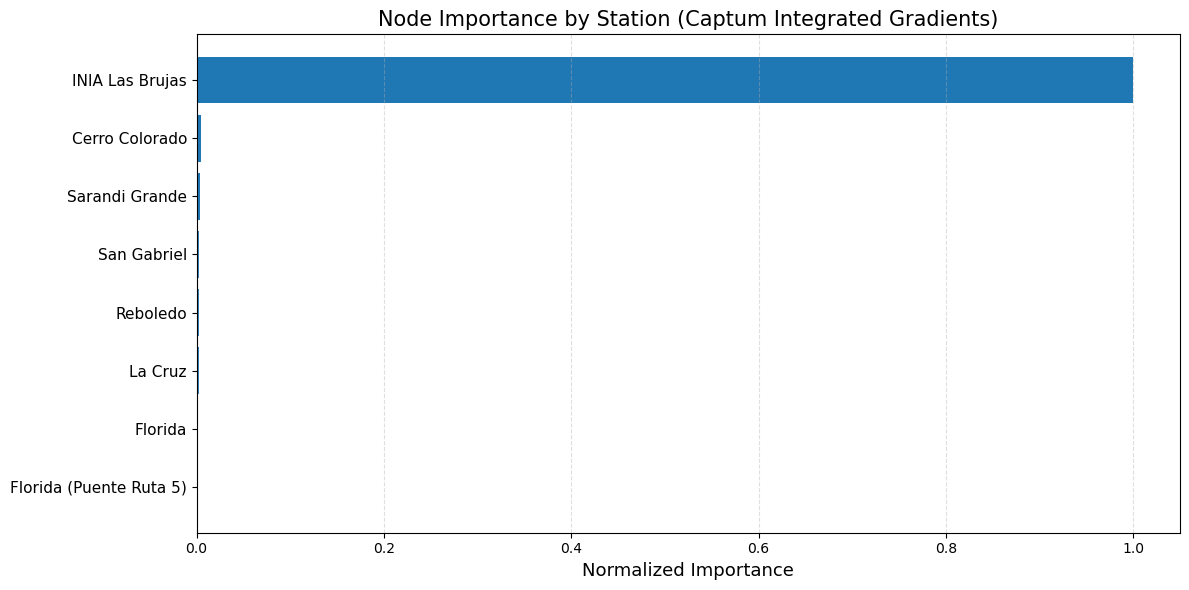

In [30]:
import matplotlib.pyplot as plt
import numpy as np

# Convert to numpy if needed
node_importance = np.array(node_importance)

# Sort nodes by importance
sorted_idx = np.argsort(node_importance)

sorted_importance = node_importance[sorted_idx]
sorted_stations = np.array(station_order)[sorted_idx]

# Plot
plt.figure(figsize=(12, 6))

bars = plt.barh(
    range(len(sorted_importance)),
    sorted_importance,
    alpha=0.9
)

# Highlight top 3 stations
top_k = 3
for i in range(1, top_k + 1):
    bars[-i].set_alpha(1.0)

plt.yticks(
    range(len(sorted_stations)),
    sorted_stations,
    fontsize=11
)

plt.xlabel(
    "Normalized Importance",
    fontsize=13
)

plt.title(
    "Node Importance by Station (Captum Integrated Gradients)",
    fontsize=15
)

plt.grid(
    axis="x",
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()
plt.show()

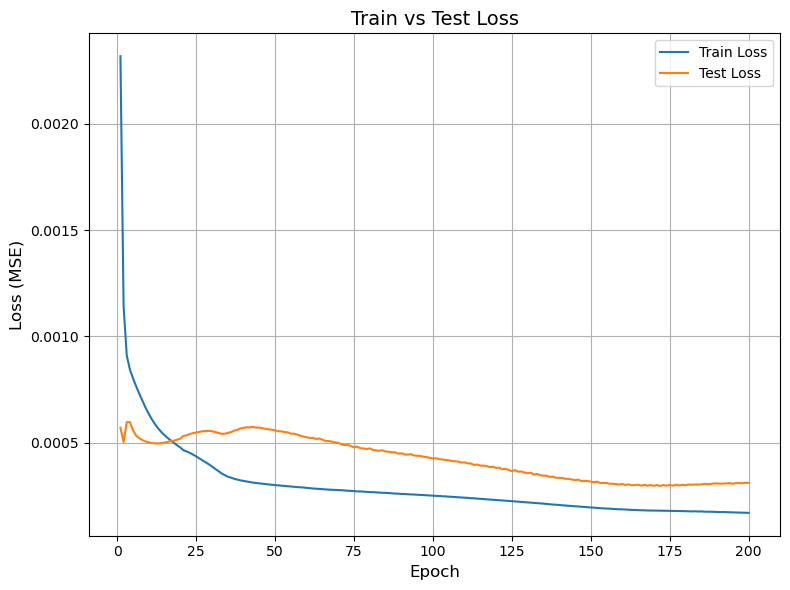

In [198]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8,6))

plt.plot(epochs, train_loss_list, label="Train Loss")
plt.plot(epochs, test_loss_list, label="Test Loss")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss (MSE)", fontsize=12)
plt.title("Train vs Test Loss", fontsize=14)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
plt.show()

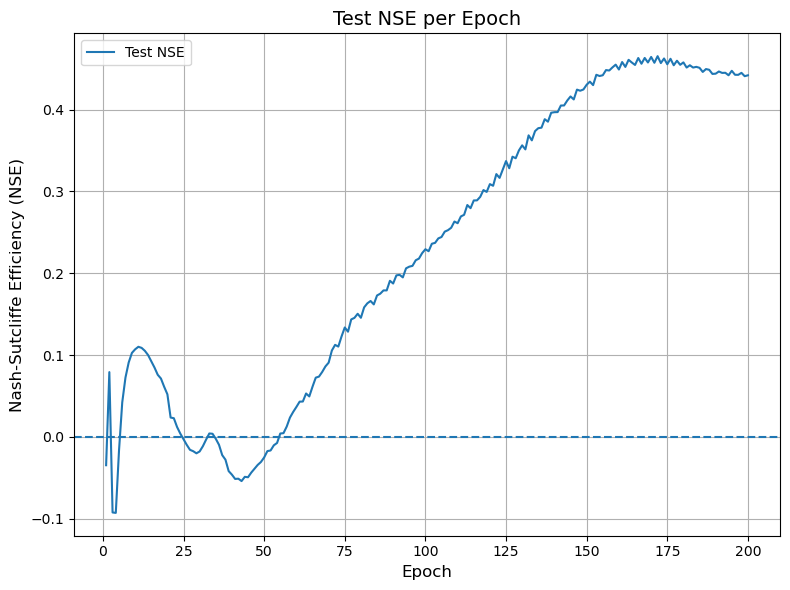

In [199]:
plt.figure(figsize=(8,6))

plt.plot(epochs, test_nse_list, label="Test NSE")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Nash-Sutcliffe Efficiency (NSE)", fontsize=12)
plt.title("Test NSE per Epoch", fontsize=14)

plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.axhline(0, linestyle="--")  # useful NSE reference

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
plt.show()

In [200]:
model.eval()

y_pred_train = []
y_pred_test = []

with torch.no_grad():

    for data in dataset_train:
        out = model(data.x, data.edge_index)

        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_train.append(target_true_inv)

    for data in dataset_test:
        out = model(data.x, data.edge_index)

        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_test.append(target_true_inv)

y_pred_train = np.array(y_pred_train)
y_pred_test = np.array(y_pred_test)

# Combine predictions
y_pred = np.concatenate([
    y_pred_train,
    y_pred_test
])

In [202]:
nse_metric(y_true_test, y_pred_test)

0.44192718369282247

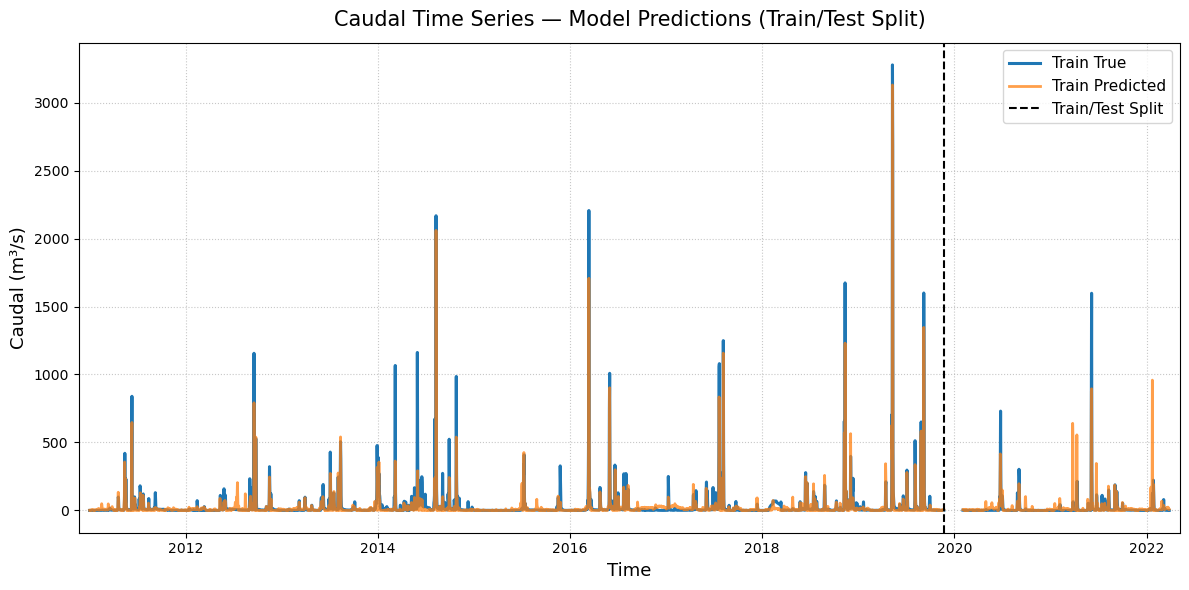

In [201]:
import numpy as np

# True values (NO SHUFFLE — keep temporal order)
y_true_all = df_data_all.loc[:, target_col].values

split_index = int(len(y_true_all) * train_ratio)

y_true_train = y_true_all[:split_index]
y_true_test = y_true_all[split_index:]

# Remove window offset (VERY IMPORTANT)
y_true_train = y_true_train[window_size:]
y_true_test = y_true_test[window_size:]

samples_train = y_true_train.size
samples_test = y_true_test.size

y_pred_train = y_pred[:samples_train].squeeze()
y_pred_test = y_pred[samples_train:].squeeze()

time = df_data_all.index

# --- Style settings
plt.figure(figsize=(12, 6))

# Colorblind-friendly colors
color_true = "#1f77b4"   # blue
color_pred = "#ff7f0e"   # orange

lw_true = 2.2
lw_pred = 2.0

# --- Training data (solid lines)

plt.plot(
    time[:samples_train],
    y_true_train,
    label="Train True",
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[:samples_train],
    y_pred_train,
    label="Train Predicted",
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75   # transparency helps overlap visibility
)

# --- Testing data (dashed lines)

plt.plot(
    time[-samples_test:],
    y_true_test,
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[-samples_test:],
    y_pred_test,
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75
)

# --- Divider line

plt.axvline(
    x=time[samples_train],
    linestyle="--",
    linewidth=1.5,
    color="black",
    label="Train/Test Split"
)

# --- Labels and formatting

plt.xlabel("Time", fontsize=13)
plt.ylabel("Caudal (m³/s)", fontsize=13)

plt.title(
    "Caudal Time Series — Model Predictions (Train/Test Split)",
    fontsize=15,
    pad=12
)

plt.legend(fontsize=11)

plt.grid(
    True,
    linestyle=":",
    linewidth=0.8,
    alpha=0.7
)

plt.margins(x=0.01)

plt.tight_layout()
plt.show()

-------

## Graph definition

### Test 1 v2: Edge features with stations distance (with weights)

En este caso:
- Nodo = Estación de monitoreo
- Atributos del nodo = Variables medidas
- Vertices = Conexiones entre estaciones
- Atributos del vertice = Distancia entre las estaciones conectadas
- El grafo es dirigido

<img src="notebook_imgs/grafo1.jpg" width="50%">

In [43]:
target_station = "Florida (Puente Ruta 5)"
target_variable = "Caudal (Q) [m3/s]"

all_cols = list(df_data_all.columns)
all_stations = [
    re.search(r"\[(.*?)\]", e).group(1)
    for e in all_cols
]
station_order = list(dict.fromkeys(all_stations)) # Remove duplicates from list while preserving order of elements

stations_coords = pd.read_csv(data_folder+"other_data/SL_stations.csv")

stations_coords = stations_coords[stations_coords["station"].isin(station_order)] # Keep only stations inside Florida's basin
stations_coords = stations_coords.set_index('station') # Define new index

# --- (1) Se definen las distancias ---

coords_list = [
        (stations_coords.loc[s, 'longitud'],
        stations_coords.loc[s, 'latitud'])
    for s in station_order
]

target_station_coords = [stations_coords.loc[target_station, 'longitud'],
                            stations_coords.loc[target_station, 'latitud']]

In [44]:
stations_coords

,longitud,latitud
station,,
Florida (Puente Ruta 5),-56.20013,-34.06973
INIA Las Brujas,-56.34011,-34.65811
Cerro Colorado,-55.54943,-33.84908
Florida,-56.19013,-34.07639
La Cruz,-56.23712,-33.91546
Reboledo,-55.65021,-33.98643
San Gabriel,-55.88018,-34.02641
Sarandi Grande,-56.32750,-33.70884


In [45]:
# --- (2) Se define la conectividad del grafo ---

edge_index = torch.tensor([
    [1, 2, 3, 4, 5, 6, 7],
    [0, 0, 0, 0, 0, 0, 0]
], dtype=torch.long)
edge_index

tensor([[1, 2, 3, 4, 5, 6, 7],
        [0, 0, 0, 0, 0, 0, 0]])

In [46]:
# --- (3) Se calculan las distancias de los nodos ---

row, col = edge_index

coords = torch.tensor(coords_list, dtype=torch.float)

distances = torch.linalg.norm(
    coords[row] - coords[col],
    dim=1
)


# ---- Prevent extremely small distances ----

min_dist = distances.quantile(0.1)  # 10th percentile
distances = torch.clamp(distances, min=min_dist)

# ---- Gaussian weighting ----

sigma = distances.mean()

weights = torch.exp(
    - (distances ** 2) / (2 * sigma ** 2)
)

# Normalize to [0,1]
weights = (weights - weights.min()) / (
    weights.max() - weights.min()
)

dist_weight = weights.view(-1, 1)
dist_weight

tensor([[0.1225],
        [0.0000],
        [1.0000],
        [0.9397],
        [0.2058],
        [0.6673],
        [0.5470]])

In [47]:
from collections import defaultdict

def extract_station(col):
    return re.match(r"\[(.*?)\]", col).group(1)

station_columns = defaultdict(list)

for col in df_data_all.columns:
    st = extract_station(col)
    station_columns[st].append(col)

In [48]:
def extract_variable(col):
    return re.sub(r"\[.*?\]\s*", "", col)

variable_order = [c.split("] ", 1)[1] for c in df_data_all.columns]
variable_order = list(dict.fromkeys(variable_order))

In [49]:
from sklearn.model_selection import train_test_split

train_ratio = 0.8
test_ratio = 0.2

# First split: train vs (val + test)
df_train, df_test = train_test_split(
    df_data_all,
    train_size=train_ratio,
    shuffle=False
)

# Second split: val vs test
# dataset_val, dataset_test = train_test_split(
#     df_data_all,
#     train_size=val_ratio / (1 - train_ratio),
#     shuffle=False
# )
#print(f"N° val samples: {len(dataset_val.index)}")

print(f"N° train samples: {len(df_train.index)}")
print(f"N° test samples: {len(df_test.index)}")


N° train samples: 3284
N° test samples: 821


In [50]:
f"[{target_station}] {target_variable}"

'[Florida (Puente Ruta 5)] Caudal (Q) [m3/s]'

In [51]:
from sklearn.preprocessing import MinMaxScaler
import pandas as pd

scalerX = MinMaxScaler()
scalerY = MinMaxScaler()

target_col = f"[{target_station}] {target_variable}"


df_train_scaled = df_train.copy()

X_train = df_train_scaled.drop(columns=[target_col])
y_train = df_train_scaled[[target_col]] 

# Fit scalers
X_train_scaled = scalerX.fit_transform(X_train)
y_train_scaled = scalerY.fit_transform(y_train)

# Assign back
df_train_scaled[X_train.columns] = X_train_scaled
df_train_scaled[target_col] = y_train_scaled


df_test_scaled = df_test.copy()

X_test = df_test_scaled.drop(columns=[target_col])
y_test = df_test_scaled[[target_col]]

# Transform only
X_test_scaled = scalerX.transform(X_test)
y_test_scaled = scalerY.transform(y_test)

# Assign back
df_test_scaled[X_test.columns] = X_test_scaled
df_test_scaled[target_col] = y_test_scaled

In [52]:
import torch
import numpy as np

num_nodes = len(station_order)
num_features = len(variable_order)
num_time_train = len(df_train_scaled)
num_time_test = len(df_test_scaled)

X_all_train = torch.zeros(
    (num_nodes, num_time_train, num_features),
    dtype=torch.float32
)

X_all_test = torch.zeros(
    (num_nodes, num_time_test, num_features),
    dtype=torch.float32
)

for i, station in enumerate(station_order):

    for j, variable in enumerate(variable_order):

        col_name = f"[{station}] {variable}"

        if col_name in df_train_scaled.columns:

            X_all_train[i, :, j] = torch.tensor(
                df_train_scaled[col_name].values,
                dtype=torch.float32
            )

            X_all_test[i, :, j] = torch.tensor(
                df_test_scaled[col_name].values,
                dtype=torch.float32
            )

        else:
            # missing variable at station
            X_all_train[i, :, j] = 0.0
            X_all_test[i, :, j] = 0.0

In [53]:
import torch
from torch_geometric.data import Data

# Return list of windowed graph data
# In this case: 
# - input_window = "window"
# - output_window = 1

def build_windowed_graphs(
    x_all,                     # [num_nodes, T, num_features]
    edge_index,                # [2, num_edges]
    edge_weight=None,          # [num_nodes, num_features]
    window=12,
    target_feature_idx=0,      # feature to predict
    target_node_idx=None       # None → predict for all nodes
):

    num_nodes, T, num_features = x_all.shape

    data_list = []

    for t in range(T - window):

        # Input window
        x_window = x_all[:, t:t+window, :].clone()  # shape: [num_nodes, window, num_features]

        # Don't use target as input (set it to zero)
        x_window[:, :, target_feature_idx] = 0

        # Target timestep
        y_full = x_all[:, t+window, target_feature_idx]  # shape: [num_nodes]
        
        # If: 
        #   target_node_idx = None --> Predict all variables
        #   target_node_idx = idx --> Predict 'idx' variable
        if target_node_idx is not None:
            y = y_full[target_node_idx]  # shape: scalar
        else:
            y = y_full  # shape: [num_nodes]

        data = Data(
            x=x_window,
            edge_index=edge_index,
            edge_weight=edge_weight,
            y=y
        )

        data_list.append(data)

    return data_list

In [54]:
target_feature_idx = variable_order.index(target_variable) # Variable --> Feature
target_node_idx = station_order.index(target_station) # Station --> Node

edge_weight = dist_weight/dist_weight.sum() # Distance normalization --> edge weights
window_size = 36

dataset_train = build_windowed_graphs(
    X_all_train,
    edge_index,
    edge_weight,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx
)

dataset_test = build_windowed_graphs(
    X_all_test,
    edge_index,
    edge_weight,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx
)

print(f"Length train: {len(dataset_train)}")
print(f"Graph train: {dataset_train[0]}")
print(f"Length test: {len(dataset_test)}")
print(f"Graph test: {dataset_test[0]}")

Length train: 3248
Graph train: Data(x=[8, 36, 10], edge_index=[2, 7], y=4.089299181941897e-05, edge_weight=[7, 1])
Length test: 785
Graph test: Data(x=[8, 36, 10], edge_index=[2, 7], y=0.0004632504715118557, edge_weight=[7, 1])


### GNN Model Definition

In [55]:
import torch
import torch.nn as nn
from torch_geometric.nn import GraphConv
from torch.nn import GRU

class BasicGNN(nn.Module):

    def __init__(self, num_features, gnn_hidden, rnn_hidden, out_channels):
        super().__init__()

        self.gnn_hidden = gnn_hidden
        self.num_features = num_features

        self.gconv1 = GraphConv(num_features, gnn_hidden)
        #self.gconv2 = GraphConv(gnn_hidden, gnn_hidden)

        self.rnn = nn.GRU(
            input_size=gnn_hidden,
            hidden_size=rnn_hidden,
            batch_first=True,
        )

        self.fc = nn.Linear(
            rnn_hidden,
            out_channels
        )

    def forward(self, x, edge_index, edge_weight=None):

        # x:
        # [num_nodes, time_window, features]
        N, T, F = x.shape

        gnn_outputs = []

        # Apply conv layer to each data point independently
        for t in range(T):

            x_t = x[:, t, :]  # [num_nodes, features]

            h_t = self.gconv1(
                x_t,
                edge_index=edge_index,
                edge_weight=edge_weight
            )  # [num_nodes, gnn_hidden]
            h_t = actF.relu(h_t)

            gnn_outputs.append(h_t)

        #print(f"Len out before: {len(gnn_outputs)}")
        #print(f"out before: {gnn_outputs[0].shape}")
        
        # Stack time: [num_nodes, time_window, gnn_hidden]
        h = torch.stack(gnn_outputs, dim=1)
        
        #print(f"h stack: {h.shape}")

        # RNN
        h, _ = self.rnn(h)

        # Take last timestep
        h_last = h[:, -1, :]

        # Prediction
        out = self.fc(h_last)

        #print(f"OUT {out.shape}")

        return out.squeeze()

In [56]:
from torch_geometric.loader import DataLoader
batch_dize = 64

train_loader = DataLoader(dataset_train, batch_size=batch_dize, shuffle=False)
test_loader = DataLoader(dataset_test, batch_size=batch_dize, shuffle=False)

In [57]:
from sklearn.metrics import r2_score as nse_metric

num_features = dataset_train[0]["x"].shape[2]

model = BasicGNN(
    num_features=num_features,
    gnn_hidden=16, 
    rnn_hidden=16,
    out_channels=1
)

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)
criterion = nn.MSELoss()

def train(model, criterion, optimizer, train_loader, use_weigths):
    model.train()
    total_train_loss = 0

    for data in train_loader:

        optimizer.zero_grad()  # Clear gradients.

        # print(f"X: {data.x.shape}")
        # print(f"edge_index: {data.edge_index.shape}")
        # print(f"edge_weight: {data.edge_weight.shape}")
        # print(f"y: {data.y.shape}")

        #print(data.edge_weight)

        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
        else:
            out = model(data.x, data.edge_index)  # Perform a single forward pass.

        # out: [num_nodes x batch_size, num_features] ---> We want 'Caudal' for Node 'Florida' (slice array by num_nodes)
        target_prediction = out[target_node_idx::num_nodes]

        # print(f"target shape out: {target_prediction.shape}")
        # print(f"target out: {target_prediction}")

        train_loss = criterion(target_prediction, data.y)  # Compute the loss solely based on the training nodes.

        train_loss.backward()  # Derive gradients.
        optimizer.step()  # Update parameters based on gradients.

        total_train_loss += train_loss.item()

    return total_train_loss / len(train_loader)

def test(model, criterion, test_loader, use_weigths):
    model.eval()

    total_loss = 0.0

    all_preds_inv = []
    all_targets_inv = []

    with torch.no_grad():
        for data in test_loader:

            if use_weigths:
                out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
            else:
                out = model(data.x, data.edge_index)  # Perform a single forward pass.

            #print(out.shape)
            #print(out)

            # out: [num_nodes x batch_size, num_features] ---> We want 'Caudal' for Node 'Florida' (slice array by num_nodes)
            target_prediction = out[target_node_idx::num_nodes]

            target_prediction_inv = scalerY.inverse_transform(target_prediction.reshape(-1, 1))
            target_true_inv = scalerY.inverse_transform(data.y.reshape(-1, 1))

            # Loss (e.g., MSELoss)
            loss = criterion(target_prediction, data.y)

            total_loss += loss.item()

            # Before appending inverse pred for NSE evaluation, make negative predictions zero
            target_prediction_inv[target_prediction_inv<0] = 0
            #print(f"Despues: {(target_prediction_inv<0).sum()}")

            all_preds_inv.append(torch.from_numpy(target_prediction_inv))
            all_targets_inv.append(torch.from_numpy(target_true_inv))

    all_preds_inv = torch.cat(all_preds_inv)

    all_targets_inv = torch.cat(all_targets_inv)

    nse = nse_metric(all_targets_inv, all_preds_inv)

    avg_loss = total_loss / len(test_loader)

    return avg_loss, nse

In [223]:
num_epochs = 200

train_loss_list = []
test_loss_list = []
test_nse_list = []

use_weigths = True

for epoch in range(num_epochs):
    loss = train(model, criterion, optimizer, train_loader, use_weigths)
    test_loss, test_nse = test(model, criterion, test_loader, use_weigths)

    train_loss_list.append(loss)
    test_loss_list.append(test_loss)
    test_nse_list.append(test_nse)

    print(
        f"Epoch [{1+epoch:03d}/{num_epochs}] | "
        f"Train Loss: {loss:.6f} | "
        f"Test Loss: {test_loss:.6f} | "
        f"Test NSE: {test_nse:.2f}"
    )

if use_weigths:
    torch.save(model, 'models/BasicGNN_Arq1_weigths.pth')
else:
    torch.save(model, 'models/BasicGNN_Arq1_noweigths.pth')

Epoch [001/200] | Train Loss: 0.001581 | Test Loss: 0.000628 | Test NSE: -0.14
Epoch [002/200] | Train Loss: 0.001505 | Test Loss: 0.000615 | Test NSE: -0.11
Epoch [003/200] | Train Loss: 0.001446 | Test Loss: 0.000591 | Test NSE: -0.07
Epoch [004/200] | Train Loss: 0.001383 | Test Loss: 0.000561 | Test NSE: -0.02
Epoch [005/200] | Train Loss: 0.001312 | Test Loss: 0.000532 | Test NSE: 0.04
Epoch [006/200] | Train Loss: 0.001234 | Test Loss: 0.000516 | Test NSE: 0.06
Epoch [007/200] | Train Loss: 0.001157 | Test Loss: 0.000527 | Test NSE: 0.05
Epoch [008/200] | Train Loss: 0.001086 | Test Loss: 0.000572 | Test NSE: -0.03
Epoch [009/200] | Train Loss: 0.001029 | Test Loss: 0.000630 | Test NSE: -0.14
Epoch [010/200] | Train Loss: 0.000989 | Test Loss: 0.000671 | Test NSE: -0.21
Epoch [011/200] | Train Loss: 0.000966 | Test Loss: 0.000694 | Test NSE: -0.25
Epoch [012/200] | Train Loss: 0.000955 | Test Loss: 0.000706 | Test NSE: -0.28
Epoch [013/200] | Train Loss: 0.000949 | Test Loss: 0.0

In [58]:
import torch
import torch.serialization

torch.serialization.add_safe_globals([BasicGNN])

model = torch.load(
    "models/Arq1_weight/BasicGNN_Arq1_weigths.pth",
    map_location="cpu",
    weights_only=False
)


# Set evaluation mode
model.eval()

print("Model loaded successfully.")

Model loaded successfully.


In [59]:
from captum.attr import IntegratedGradients

model.eval()

data = dataset_test[0]

x = data.x.clone().requires_grad_(True)
edge_index = data.edge_index

target_node = target_node_idx


def model_forward(x):
    out = model(x, edge_index)

    # Make sure output is at least 1D
    if out.dim() == 2:
        out = out[target_node, 0]

    elif out.dim() == 1:
        out = out[target_node]

    elif out.dim() == 0:
        out = out

    # IMPORTANT: return as 1D tensor
    return out.unsqueeze(0)


ig = IntegratedGradients(model_forward)

baseline = torch.zeros_like(x)

attributions = ig.attribute(
    x,
    baselines=baseline
)

In [60]:
import numpy as np

attr = attributions.detach().cpu().numpy()

node_importance = np.sum(
    np.abs(attr),
    axis=(1, 2)
)

node_importance /= node_importance.max()

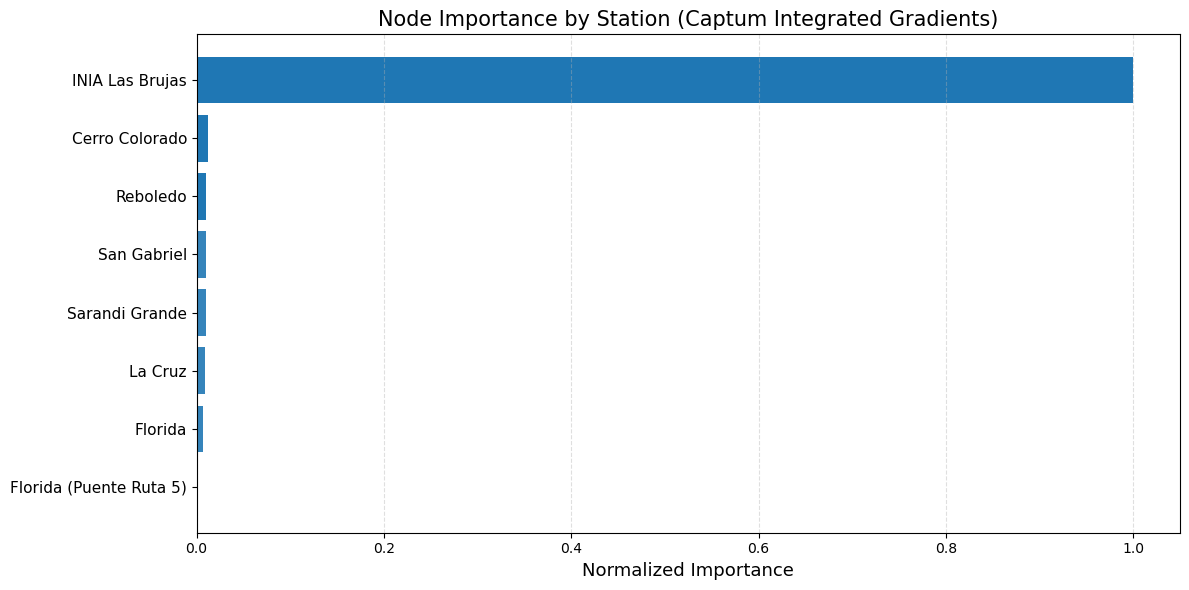

In [61]:
import matplotlib.pyplot as plt
import numpy as np

# Convert to numpy if needed
node_importance = np.array(node_importance)

# Sort nodes by importance
sorted_idx = np.argsort(node_importance)

sorted_importance = node_importance[sorted_idx]
sorted_stations = np.array(station_order)[sorted_idx]

# Plot
plt.figure(figsize=(12, 6))

bars = plt.barh(
    range(len(sorted_importance)),
    sorted_importance,
    alpha=0.9
)

# Highlight top 3 stations
top_k = 3
for i in range(1, top_k + 1):
    bars[-i].set_alpha(1.0)

plt.yticks(
    range(len(sorted_stations)),
    sorted_stations,
    fontsize=11
)

plt.xlabel(
    "Normalized Importance",
    fontsize=13
)

plt.title(
    "Node Importance by Station (Captum Integrated Gradients)",
    fontsize=15
)

plt.grid(
    axis="x",
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()
plt.show()

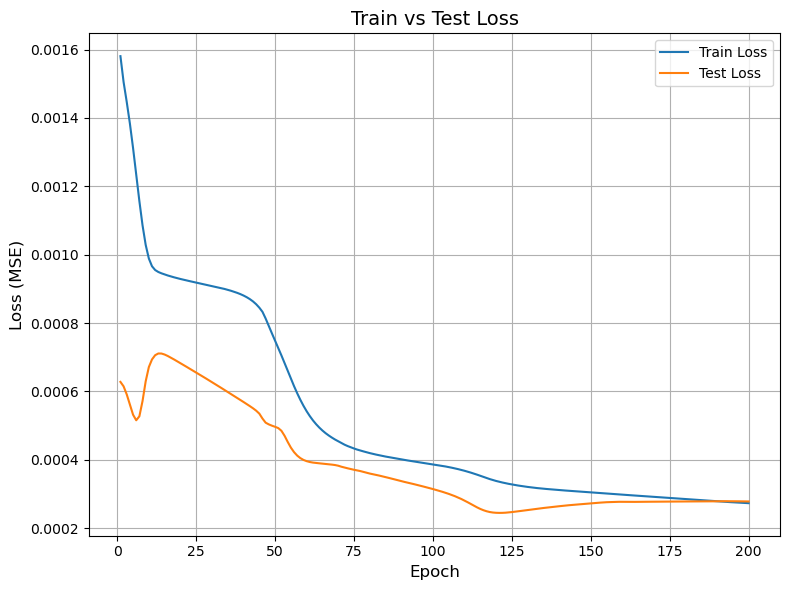

In [224]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8,6))

plt.plot(epochs, train_loss_list, label="Train Loss")
plt.plot(epochs, test_loss_list, label="Test Loss")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss (MSE)", fontsize=12)
plt.title("Train vs Test Loss", fontsize=14)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
plt.show()

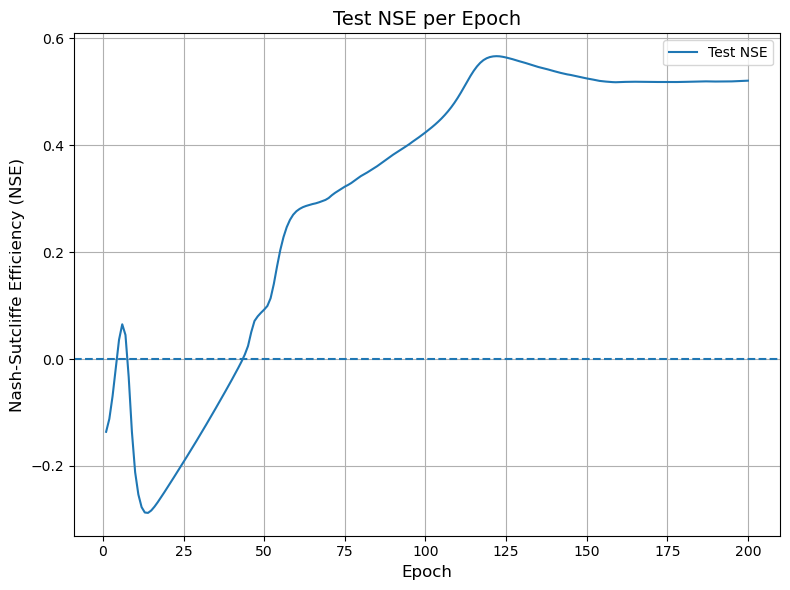

In [225]:
plt.figure(figsize=(8,6))

plt.plot(epochs, test_nse_list, label="Test NSE")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Nash-Sutcliffe Efficiency (NSE)", fontsize=12)
plt.title("Test NSE per Epoch", fontsize=14)

plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.axhline(0, linestyle="--")  # useful NSE reference

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
plt.show()

In [231]:
model.eval()

y_pred_train = []
y_pred_test = []

with torch.no_grad():

    for data in dataset_train:

        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
        else:
            out = model(data.x, data.edge_index)  # Perform a single forward pass.

        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_train.append(target_true_inv)

    for data in dataset_test:
        
        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
        else:
            out = model(data.x, data.edge_index)  # Perform a single forward pass.

        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_test.append(target_true_inv)

y_pred_train = np.array(y_pred_train)
y_pred_test = np.array(y_pred_test)

# Combine predictions
y_pred = np.concatenate([
    y_pred_train,
    y_pred_test
])

In [233]:
nse_metric(y_true_test, y_pred_test)

0.5205365408150622

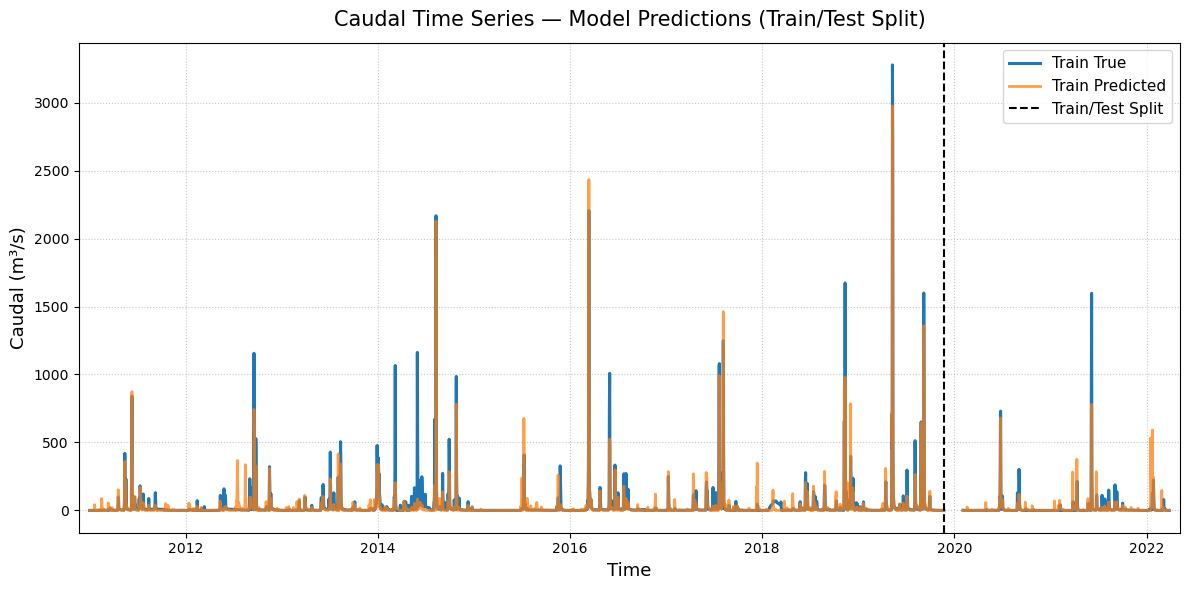

In [232]:
import numpy as np

# True values (NO SHUFFLE — keep temporal order)
y_true_all = df_data_all.loc[:, target_col].values

split_index = int(len(y_true_all) * train_ratio)

y_true_train = y_true_all[:split_index]
y_true_test = y_true_all[split_index:]

# Remove window offset (VERY IMPORTANT)
y_true_train = y_true_train[window_size:]
y_true_test = y_true_test[window_size:]

samples_train = y_true_train.size
samples_test = y_true_test.size

y_pred_train = y_pred[:samples_train].squeeze()
y_pred_test = y_pred[samples_train:].squeeze()

time = df_data_all.index

# --- Style settings
plt.figure(figsize=(12, 6))

# Colorblind-friendly colors
color_true = "#1f77b4"   # blue
color_pred = "#ff7f0e"   # orange

lw_true = 2.2
lw_pred = 2.0

# --- Training data (solid lines)

plt.plot(
    time[:samples_train],
    y_true_train,
    label="Train True",
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[:samples_train],
    y_pred_train,
    label="Train Predicted",
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75   # transparency helps overlap visibility
)

# --- Testing data (dashed lines)

plt.plot(
    time[-samples_test:],
    y_true_test,
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[-samples_test:],
    y_pred_test,
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75
)

# --- Divider line

plt.axvline(
    x=time[samples_train],
    linestyle="--",
    linewidth=1.5,
    color="black",
    label="Train/Test Split"
)

# --- Labels and formatting

plt.xlabel("Time", fontsize=13)
plt.ylabel("Caudal (m³/s)", fontsize=13)

plt.title(
    "Caudal Time Series — Model Predictions (Train/Test Split)",
    fontsize=15,
    pad=12
)

plt.legend(fontsize=11)

plt.grid(
    True,
    linestyle=":",
    linewidth=0.8,
    alpha=0.7
)

plt.margins(x=0.01)

plt.tight_layout()
plt.show()

## Graph definition

### Test 2: Edge features and self loop

En este caso:
- Nodo = Estación de monitoreo
- Atributos del nodo = Variables medidas
- Vertices = Conexiones entre estaciones
- Self loop = Caudal es input
- El grafo es dirigido

<img src="notebook_imgs/grafo1.jpg" width="50%">

In [73]:
target_station = "Florida (Puente Ruta 5)"
target_variable = "Caudal (Q) [m3/s]"

all_cols = list(df_data_all.columns)
all_stations = [
    re.search(r"\[(.*?)\]", e).group(1)
    for e in all_cols
]
station_order = list(dict.fromkeys(all_stations)) # Remove duplicates from list while preserving order of elements

stations_coords = pd.read_csv(data_folder+"other_data/SL_stations.csv")

stations_coords = stations_coords[stations_coords["station"].isin(station_order)] # Keep only stations inside Florida's basin
stations_coords = stations_coords.set_index('station') # Define new index

# --- (1) Se definen las distancias ---

coords_list = [
        (stations_coords.loc[s, 'longitud'],
        stations_coords.loc[s, 'latitud'])
    for s in station_order
]

target_station_coords = [stations_coords.loc[target_station, 'longitud'],
                            stations_coords.loc[target_station, 'latitud']]

In [74]:
# --- (2) Se define la conectividad del grafo ---

# Se incorpora un self loop
edge_index = torch.tensor([
    [0, 1, 2, 3, 4, 5, 6, 7],
    [0, 0, 0, 0, 0, 0, 0, 0]
], dtype=torch.long)
edge_index

tensor([[0, 1, 2, 3, 4, 5, 6, 7],
        [0, 0, 0, 0, 0, 0, 0, 0]])

In [75]:
# --- (3) Se calculan las distancias de los nodos ---

row, col = edge_index

coords = torch.tensor(coords_list, dtype=torch.float)

distances = torch.linalg.norm(
    coords[row] - coords[col],
    dim=1
)


# ---- Prevent extremely small distances ----

min_dist = distances.quantile(0.1)  # 10th percentile
distances = torch.clamp(distances, min=min_dist)

# ---- Gaussian weighting ----

sigma = distances.mean()

weights = torch.exp(
    - (distances ** 2) / (2 * sigma ** 2)
)

# Normalize to [0,1]
weights = (weights - weights.min()) / (
    weights.max() - weights.min()
)

dist_weight = weights.view(-1, 1)
dist_weight

tensor([[1.0000],
        [0.0880],
        [0.0000],
        [0.9996],
        [0.8825],
        [0.1538],
        [0.5850],
        [0.4630]])

In [76]:
from collections import defaultdict

def extract_station(col):
    return re.match(r"\[(.*?)\]", col).group(1)

station_columns = defaultdict(list)

for col in df_data_all.columns:
    st = extract_station(col)
    station_columns[st].append(col)

In [77]:
def extract_variable(col):
    return re.sub(r"\[.*?\]\s*", "", col)

variable_order = [c.split("] ", 1)[1] for c in df_data_all.columns]
variable_order = list(dict.fromkeys(variable_order))

In [78]:
from sklearn.model_selection import train_test_split

train_ratio = 0.8
test_ratio = 0.2

# First split: train vs (val + test)
df_train, df_test = train_test_split(
    df_data_all,
    train_size=train_ratio,
    shuffle=False
)

# Second split: val vs test
# dataset_val, dataset_test = train_test_split(
#     df_data_all,
#     train_size=val_ratio / (1 - train_ratio),
#     shuffle=False
# )
#print(f"N° val samples: {len(dataset_val.index)}")

print(f"N° train samples: {len(df_train.index)}")
print(f"N° test samples: {len(df_test.index)}")


N° train samples: 3284
N° test samples: 821


In [79]:
from sklearn.preprocessing import MinMaxScaler
import pandas as pd

scalerX = MinMaxScaler()
scalerY = MinMaxScaler()

target_col = f"[{target_station}] {target_variable}"


df_train_scaled = df_train.copy()

X_train = df_train_scaled.drop(columns=[target_col])
y_train = df_train_scaled[[target_col]] 

# Fit scalers
X_train_scaled = scalerX.fit_transform(X_train)
y_train_scaled = scalerY.fit_transform(y_train)

# Assign back
df_train_scaled[X_train.columns] = X_train_scaled
df_train_scaled[target_col] = y_train_scaled


df_test_scaled = df_test.copy()

X_test = df_test_scaled.drop(columns=[target_col])
y_test = df_test_scaled[[target_col]]

# Transform only
X_test_scaled = scalerX.transform(X_test)
y_test_scaled = scalerY.transform(y_test)

# Assign back
df_test_scaled[X_test.columns] = X_test_scaled
df_test_scaled[target_col] = y_test_scaled

In [80]:
import torch
import numpy as np

num_nodes = len(station_order)
num_features = len(variable_order)
num_time_train = len(df_train_scaled)
num_time_test = len(df_test_scaled)

X_all_train = torch.zeros(
    (num_nodes, num_time_train, num_features),
    dtype=torch.float32
)

X_all_test = torch.zeros(
    (num_nodes, num_time_test, num_features),
    dtype=torch.float32
)

for i, station in enumerate(station_order):

    for j, variable in enumerate(variable_order):

        col_name = f"[{station}] {variable}"

        if col_name in df_train_scaled.columns:

            X_all_train[i, :, j] = torch.tensor(
                df_train_scaled[col_name].values,
                dtype=torch.float32
            )

            X_all_test[i, :, j] = torch.tensor(
                df_test_scaled[col_name].values,
                dtype=torch.float32
            )

        else:
            # missing variable at station
            X_all_train[i, :, j] = 0.0
            X_all_test[i, :, j] = 0.0

In [81]:
import torch
from torch_geometric.data import Data

# Return list of windowed graph data
# In this case: 
# - input_window = "window"
# - output_window = 1

def build_windowed_graphs(
    x_all,                     # [num_nodes, T, num_features]
    edge_index,                # [2, num_edges]
    edge_weight=None,          # [num_nodes, num_features]
    window=12,
    target_feature_idx=0,      # feature to predict
    target_node_idx=None       # None → predict for all nodes
):

    num_nodes, T, num_features = x_all.shape

    data_list = []

    for t in range(T - window):

        # Input window
        x_window = x_all[:, t:t+window, :].clone()  # shape: [num_nodes, window, num_features]

        # Self loop --> Use target as input (don't make feature zeros!)
        #x_window[:, :, target_feature_idx] = 0

        # Target timestep
        y_full = x_all[:, t+window, target_feature_idx]  # shape: [num_nodes]
        
        # If: 
        #   target_node_idx = None --> Predict all variables
        #   target_node_idx = idx --> Predict 'idx' variable
        if target_node_idx is not None:
            y = y_full[target_node_idx]  # shape: scalar
        else:
            y = y_full  # shape: [num_nodes]

        data = Data(
            x=x_window,
            edge_index=edge_index,
            edge_weight=edge_weight,
            y=y
        )

        data_list.append(data)

    return data_list

In [82]:
target_feature_idx = variable_order.index(target_variable) # Variable --> Feature
target_node_idx = station_order.index(target_station) # Station --> Node

edge_weight = dist_weight/dist_weight.sum() # Distance normalization --> edge weights
window_size = 36

dataset_train = build_windowed_graphs(
    X_all_train,
    edge_index,
    edge_weight,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx
)

dataset_test = build_windowed_graphs(
    X_all_test,
    edge_index,
    edge_weight,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx
)

print(f"Length train: {len(dataset_train)}")
print(f"Graph train: {dataset_train[0]}")
print(f"Length test: {len(dataset_test)}")
print(f"Graph test: {dataset_test[0]}")

Length train: 3248
Graph train: Data(x=[8, 36, 10], edge_index=[2, 8], y=4.089299181941897e-05, edge_weight=[8, 1])
Length test: 785
Graph test: Data(x=[8, 36, 10], edge_index=[2, 8], y=0.0004632504715118557, edge_weight=[8, 1])


### GNN Model Definition

In [83]:
import torch
import torch.nn as nn
from torch_geometric.nn import GraphConv
from torch.nn import GRU

class BasicGNN(nn.Module):

    def __init__(self, num_features, gnn_hidden, rnn_hidden, out_channels):
        super().__init__()

        self.gnn_hidden = gnn_hidden
        self.num_features = num_features

        self.gconv1 = GraphConv(num_features, gnn_hidden)
        #self.gconv2 = GraphConv(gnn_hidden, gnn_hidden)

        self.rnn = nn.GRU(
            input_size=gnn_hidden,
            hidden_size=rnn_hidden,
            batch_first=True,
        )

        self.fc = nn.Linear(
            rnn_hidden,
            out_channels
        )

    def forward(self, x, edge_index, edge_weight=None):

        # x:
        # [num_nodes, time_window, features]
        N, T, F = x.shape

        gnn_outputs = []

        # Apply conv layer to each data point independently
        for t in range(T):

            x_t = x[:, t, :]  # [num_nodes, features]

            h_t = self.gconv1(
                x_t,
                edge_index=edge_index,
                edge_weight=edge_weight
            )  # [num_nodes, gnn_hidden]
            h_t = actF.relu(h_t)

            gnn_outputs.append(h_t)

        #print(f"Len out before: {len(gnn_outputs)}")
        #print(f"out before: {gnn_outputs[0].shape}")
        
        # Stack time: [num_nodes, time_window, gnn_hidden]
        h = torch.stack(gnn_outputs, dim=1)
        
        #print(f"h stack: {h.shape}")

        # RNN
        h, _ = self.rnn(h)

        # Take last timestep
        h_last = h[:, -1, :]

        # Prediction
        out = self.fc(h_last)

        #print(f"OUT {out.shape}")

        return out.squeeze()

In [84]:
from torch_geometric.loader import DataLoader
batch_dize = 64

train_loader = DataLoader(dataset_train, batch_size=batch_dize, shuffle=False)
test_loader = DataLoader(dataset_test, batch_size=batch_dize, shuffle=False)

In [85]:
from sklearn.metrics import r2_score as nse_metric

num_features = dataset_train[0]["x"].shape[2]

model = BasicGNN(
    num_features=num_features,
    gnn_hidden=16, 
    rnn_hidden=16,
    out_channels=1
)

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)
criterion = nn.MSELoss()

def train(model, criterion, optimizer, train_loader, use_weigths):
    model.train()
    total_train_loss = 0

    for data in train_loader:

        optimizer.zero_grad()  # Clear gradients.

        # print(f"X: {data.x.shape}")
        # print(f"edge_index: {data.edge_index.shape}")
        # print(f"edge_weight: {data.edge_weight.shape}")
        # print(f"y: {data.y.shape}")

        #print(data.edge_weight)

        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
        else:
            out = model(data.x, data.edge_index)  # Perform a single forward pass.

        # out: [num_nodes x batch_size, num_features] ---> We want 'Caudal' for Node 'Florida' (slice array by num_nodes)
        target_prediction = out[target_node_idx::num_nodes]

        # print(f"target shape out: {target_prediction.shape}")
        # print(f"target out: {target_prediction}")

        train_loss = criterion(target_prediction, data.y)  # Compute the loss solely based on the training nodes.

        train_loss.backward()  # Derive gradients.
        optimizer.step()  # Update parameters based on gradients.

        total_train_loss += train_loss.item()

    return total_train_loss / len(train_loader)

def test(model, criterion, test_loader, use_weigths):
    model.eval()

    total_loss = 0.0

    all_preds_inv = []
    all_targets_inv = []

    with torch.no_grad():
        for data in test_loader:

            if use_weigths:
                out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
            else:
                out = model(data.x, data.edge_index)  # Perform a single forward pass.

            #print(out.shape)
            #print(out)

            # out: [num_nodes x batch_size, num_features] ---> We want 'Caudal' for Node 'Florida' (slice array by num_nodes)
            target_prediction = out[target_node_idx::num_nodes]

            target_prediction_inv = scalerY.inverse_transform(target_prediction.reshape(-1, 1))
            target_true_inv = scalerY.inverse_transform(data.y.reshape(-1, 1))

            # Loss (e.g., MSELoss)
            loss = criterion(target_prediction, data.y)

            total_loss += loss.item()

            # Before appending inverse pred for NSE evaluation, make negative predictions zero
            target_prediction_inv[target_prediction_inv<0] = 0
            #print(f"Despues: {(target_prediction_inv<0).sum()}")

            all_preds_inv.append(torch.from_numpy(target_prediction_inv))
            all_targets_inv.append(torch.from_numpy(target_true_inv))

    all_preds_inv = torch.cat(all_preds_inv)

    all_targets_inv = torch.cat(all_targets_inv)

    nse = nse_metric(all_targets_inv, all_preds_inv)

    avg_loss = total_loss / len(test_loader)

    return avg_loss, nse

In [ ]:
num_epochs = 200

train_loss_list = []
test_loss_list = []
test_nse_list = []

use_weigths = False

for epoch in range(num_epochs):
    loss = train(model, criterion, optimizer, train_loader, use_weigths)
    test_loss, test_nse = test(model, criterion, test_loader, use_weigths)

    train_loss_list.append(loss)
    test_loss_list.append(test_loss)
    test_nse_list.append(test_nse)

    print(
        f"Epoch [{1+epoch:03d}/{num_epochs}] | "
        f"Train Loss: {loss:.6f} | "
        f"Test Loss: {test_loss:.6f} | "
        f"Test NSE: {test_nse:.2f}"
    )

if use_weigths:
    torch.save(model, 'models/BasicGNN_Arq2_weigths.pth')
else:
    torch.save(model, 'models/BasicGNN_Arq2_noweigths.pth')

Epoch [001/200] | Train Loss: 0.007879 | Test Loss: 0.000610 | Test NSE: 0.11
Epoch [002/200] | Train Loss: 0.001244 | Test Loss: 0.000467 | Test NSE: 0.18
Epoch [003/200] | Train Loss: 0.000958 | Test Loss: 0.000492 | Test NSE: 0.15
Epoch [004/200] | Train Loss: 0.000840 | Test Loss: 0.000524 | Test NSE: 0.08
Epoch [005/200] | Train Loss: 0.000773 | Test Loss: 0.000542 | Test NSE: 0.03
Epoch [006/200] | Train Loss: 0.000731 | Test Loss: 0.000521 | Test NSE: 0.06
Epoch [007/200] | Train Loss: 0.000692 | Test Loss: 0.000510 | Test NSE: 0.08
Epoch [008/200] | Train Loss: 0.000659 | Test Loss: 0.000501 | Test NSE: 0.09
Epoch [009/200] | Train Loss: 0.000628 | Test Loss: 0.000491 | Test NSE: 0.11
Epoch [010/200] | Train Loss: 0.000600 | Test Loss: 0.000486 | Test NSE: 0.12
Epoch [011/200] | Train Loss: 0.000573 | Test Loss: 0.000476 | Test NSE: 0.14
Epoch [012/200] | Train Loss: 0.000550 | Test Loss: 0.000469 | Test NSE: 0.15
Epoch [013/200] | Train Loss: 0.000531 | Test Loss: 0.000464 | T

In [86]:
import torch
import torch.serialization

torch.serialization.add_safe_globals([BasicGNN])

model = torch.load(
    "models/Arq2_noweight/BasicGNN_Arq2_noweigths.pth",
    map_location="cpu",
    weights_only=False
)


# Set evaluation mode
model.eval()

print("Model loaded successfully.")

Model loaded successfully.


In [87]:
from captum.attr import IntegratedGradients

model.eval()

data = dataset_test[0]

x = data.x.clone().requires_grad_(True)
edge_index = data.edge_index

target_node = target_node_idx


def model_forward(x):
    out = model(x, edge_index)

    # Make sure output is at least 1D
    if out.dim() == 2:
        out = out[target_node, 0]

    elif out.dim() == 1:
        out = out[target_node]

    elif out.dim() == 0:
        out = out

    # IMPORTANT: return as 1D tensor
    return out.unsqueeze(0)


ig = IntegratedGradients(model_forward)

baseline = torch.zeros_like(x)

attributions = ig.attribute(
    x,
    baselines=baseline
)

In [88]:
import numpy as np

attr = attributions.detach().cpu().numpy()

node_importance = np.sum(
    np.abs(attr),
    axis=(1, 2)
)

node_importance /= node_importance.max()

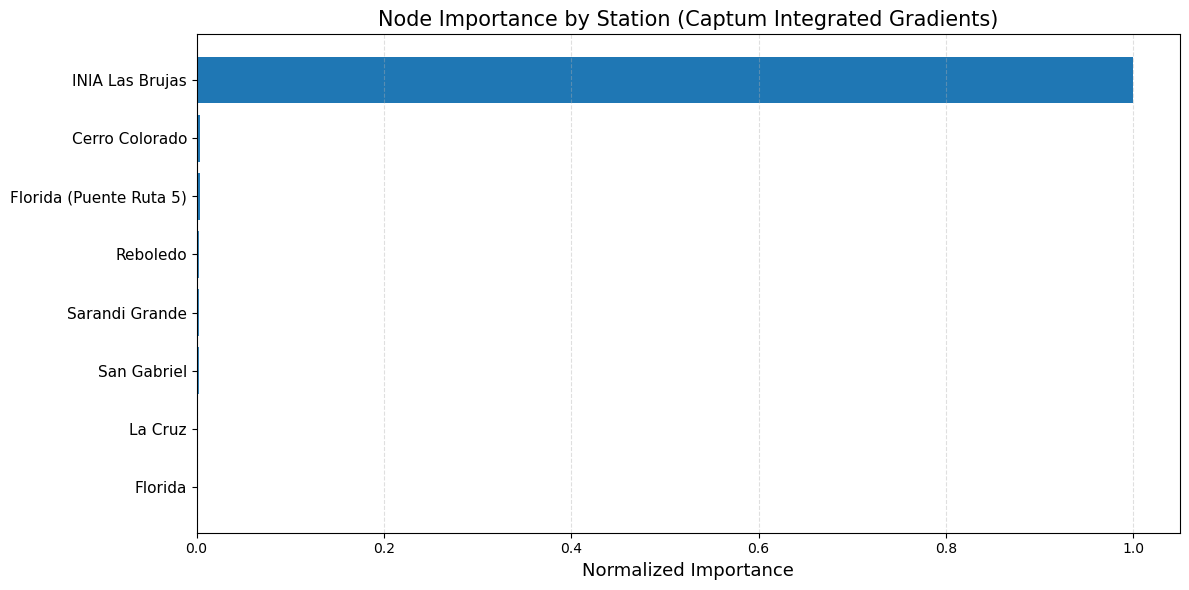

In [89]:
import matplotlib.pyplot as plt
import numpy as np

# Convert to numpy if needed
node_importance = np.array(node_importance)

# Sort nodes by importance
sorted_idx = np.argsort(node_importance)

sorted_importance = node_importance[sorted_idx]
sorted_stations = np.array(station_order)[sorted_idx]

# Plot
plt.figure(figsize=(12, 6))

bars = plt.barh(
    range(len(sorted_importance)),
    sorted_importance,
    alpha=0.9
)

# Highlight top 3 stations
top_k = 3
for i in range(1, top_k + 1):
    bars[-i].set_alpha(1.0)

plt.yticks(
    range(len(sorted_stations)),
    sorted_stations,
    fontsize=11
)

plt.xlabel(
    "Normalized Importance",
    fontsize=13
)

plt.title(
    "Node Importance by Station (Captum Integrated Gradients)",
    fontsize=15
)

plt.grid(
    axis="x",
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()
plt.show()

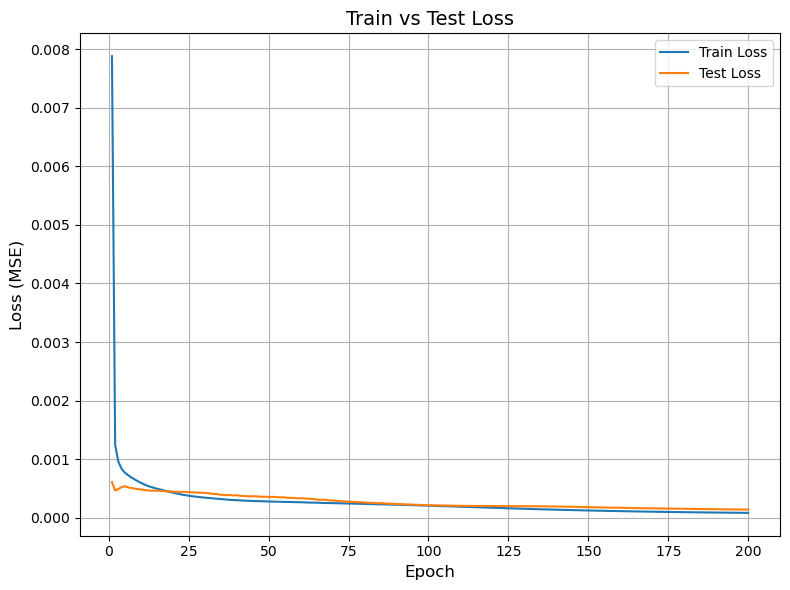

In [259]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8,6))

plt.plot(epochs, train_loss_list, label="Train Loss")
plt.plot(epochs, test_loss_list, label="Test Loss")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss (MSE)", fontsize=12)
plt.title("Train vs Test Loss", fontsize=14)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
plt.show()

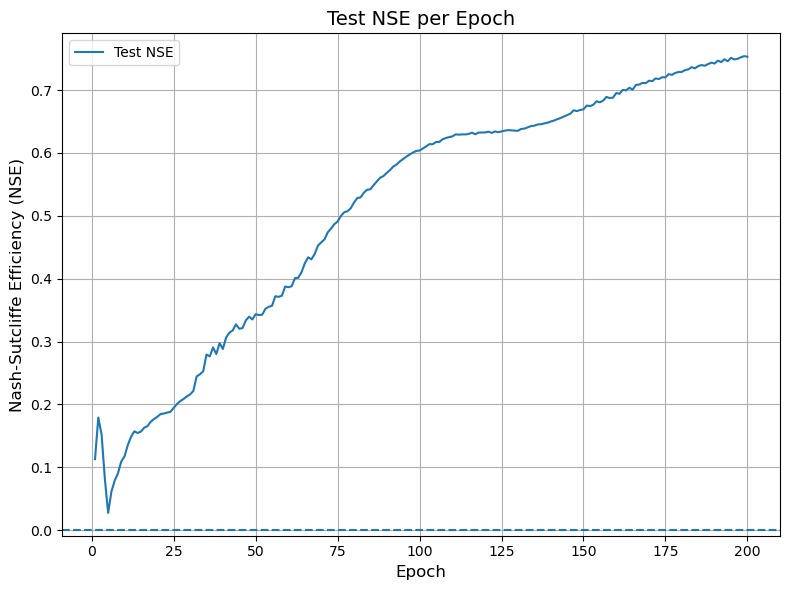

In [260]:
plt.figure(figsize=(8,6))

plt.plot(epochs, test_nse_list, label="Test NSE")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Nash-Sutcliffe Efficiency (NSE)", fontsize=12)
plt.title("Test NSE per Epoch", fontsize=14)

plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.axhline(0, linestyle="--")  # useful NSE reference

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
plt.show()

In [261]:
model.eval()

y_pred_train = []
y_pred_test = []

with torch.no_grad():

    for data in dataset_train:

        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
        else:
            out = model(data.x, data.edge_index)  # Perform a single forward pass.

        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_train.append(target_true_inv)

    for data in dataset_test:
        
        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
        else:
            out = model(data.x, data.edge_index)  # Perform a single forward pass.

        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_test.append(target_true_inv)

y_pred_train = np.array(y_pred_train)
y_pred_test = np.array(y_pred_test)

# Combine predictions
y_pred = np.concatenate([
    y_pred_train,
    y_pred_test
])

In [264]:
nse_metric(y_true_test, y_pred_test)

0.7531144716052115

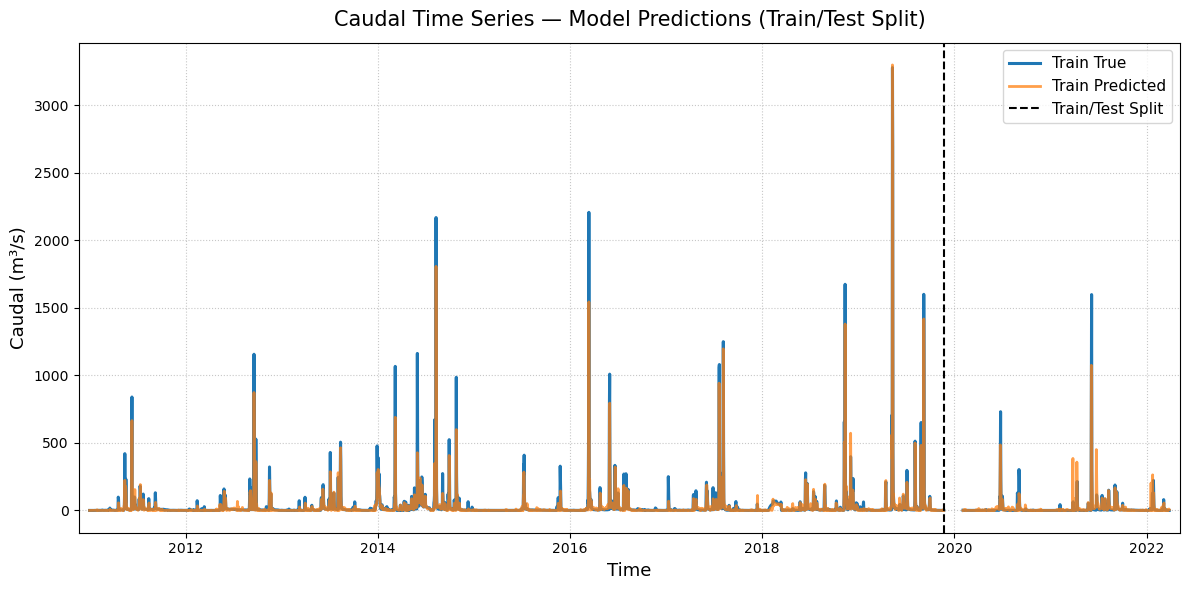

In [265]:
import numpy as np

# True values (NO SHUFFLE — keep temporal order)
y_true_all = df_data_all.loc[:, target_col].values

split_index = int(len(y_true_all) * train_ratio)

y_true_train = y_true_all[:split_index]
y_true_test = y_true_all[split_index:]

# Remove window offset (VERY IMPORTANT)
y_true_train = y_true_train[window_size:]
y_true_test = y_true_test[window_size:]

samples_train = y_true_train.size
samples_test = y_true_test.size

y_pred_train = y_pred[:samples_train].squeeze()
y_pred_test = y_pred[samples_train:].squeeze()

time = df_data_all.index

# --- Style settings
plt.figure(figsize=(12, 6))

# Colorblind-friendly colors
color_true = "#1f77b4"   # blue
color_pred = "#ff7f0e"   # orange

lw_true = 2.2
lw_pred = 2.0

# --- Training data (solid lines)

plt.plot(
    time[:samples_train],
    y_true_train,
    label="Train True",
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[:samples_train],
    y_pred_train,
    label="Train Predicted",
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75   # transparency helps overlap visibility
)

# --- Testing data (dashed lines)

plt.plot(
    time[-samples_test:],
    y_true_test,
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[-samples_test:],
    y_pred_test,
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75
)

# --- Divider line

plt.axvline(
    x=time[samples_train],
    linestyle="--",
    linewidth=1.5,
    color="black",
    label="Train/Test Split"
)

# --- Labels and formatting

plt.xlabel("Time", fontsize=13)
plt.ylabel("Caudal (m³/s)", fontsize=13)

plt.title(
    "Caudal Time Series — Model Predictions (Train/Test Split)",
    fontsize=15,
    pad=12
)

plt.legend(fontsize=11)

plt.grid(
    True,
    linestyle=":",
    linewidth=0.8,
    alpha=0.7
)

plt.margins(x=0.01)

plt.tight_layout()
plt.show()

## Graph Definition

### Test 2 v2: Edge features with self loop and stations distance (with weights)

In [90]:
target_station = "Florida (Puente Ruta 5)"
target_variable = "Caudal (Q) [m3/s]"

all_cols = list(df_data_all.columns)
all_stations = [
    re.search(r"\[(.*?)\]", e).group(1)
    for e in all_cols
]
station_order = list(dict.fromkeys(all_stations)) # Remove duplicates from list while preserving order of elements

stations_coords = pd.read_csv(data_folder+"other_data/SL_stations.csv")

stations_coords = stations_coords[stations_coords["station"].isin(station_order)] # Keep only stations inside Florida's basin
stations_coords = stations_coords.set_index('station') # Define new index

# --- (1) Se definen las distancias ---

coords_list = [
        (stations_coords.loc[s, 'longitud'],
        stations_coords.loc[s, 'latitud'])
    for s in station_order
]

target_station_coords = [stations_coords.loc[target_station, 'longitud'],
                            stations_coords.loc[target_station, 'latitud']]

In [91]:
# --- (2) Se define la conectividad del grafo ---

# Se incorpora un self loop
edge_index = torch.tensor([
    [0, 1, 2, 3, 4, 5, 6, 7],
    [0, 0, 0, 0, 0, 0, 0, 0]
], dtype=torch.long)
edge_index

tensor([[0, 1, 2, 3, 4, 5, 6, 7],
        [0, 0, 0, 0, 0, 0, 0, 0]])

In [92]:
# --- (3) Se calculan las distancias de los nodos ---

row, col = edge_index

coords = torch.tensor(coords_list, dtype=torch.float)

distances = torch.linalg.norm(
    coords[row] - coords[col],
    dim=1
)


# ---- Prevent extremely small distances ----

min_dist = distances.quantile(0.1)  # 10th percentile
distances = torch.clamp(distances, min=min_dist)

# ---- Gaussian weighting ----

sigma = distances.mean()

weights = torch.exp(
    - (distances ** 2) / (2 * sigma ** 2)
)

# Normalize to [0,1]
weights = (weights - weights.min()) / (
    weights.max() - weights.min()
)

dist_weight = weights.view(-1, 1)
dist_weight

tensor([[1.0000],
        [0.0880],
        [0.0000],
        [0.9996],
        [0.8825],
        [0.1538],
        [0.5850],
        [0.4630]])

In [93]:
from collections import defaultdict

def extract_station(col):
    return re.match(r"\[(.*?)\]", col).group(1)

station_columns = defaultdict(list)

for col in df_data_all.columns:
    st = extract_station(col)
    station_columns[st].append(col)

In [94]:
def extract_variable(col):
    return re.sub(r"\[.*?\]\s*", "", col)

variable_order = [c.split("] ", 1)[1] for c in df_data_all.columns]
variable_order = list(dict.fromkeys(variable_order))

In [95]:
from sklearn.model_selection import train_test_split

train_ratio = 0.8
test_ratio = 0.2

# First split: train vs (val + test)
df_train, df_test = train_test_split(
    df_data_all,
    train_size=train_ratio,
    shuffle=False
)

# Second split: val vs test
# dataset_val, dataset_test = train_test_split(
#     df_data_all,
#     train_size=val_ratio / (1 - train_ratio),
#     shuffle=False
# )
#print(f"N° val samples: {len(dataset_val.index)}")

print(f"N° train samples: {len(df_train.index)}")
print(f"N° test samples: {len(df_test.index)}")


N° train samples: 3284
N° test samples: 821


In [96]:
from sklearn.preprocessing import MinMaxScaler
import pandas as pd

scalerX = MinMaxScaler()
scalerY = MinMaxScaler()

target_col = f"[{target_station}] {target_variable}"


df_train_scaled = df_train.copy()

X_train = df_train_scaled.drop(columns=[target_col])
y_train = df_train_scaled[[target_col]] 

# Fit scalers
X_train_scaled = scalerX.fit_transform(X_train)
y_train_scaled = scalerY.fit_transform(y_train)

# Assign back
df_train_scaled[X_train.columns] = X_train_scaled
df_train_scaled[target_col] = y_train_scaled


df_test_scaled = df_test.copy()

X_test = df_test_scaled.drop(columns=[target_col])
y_test = df_test_scaled[[target_col]]

# Transform only
X_test_scaled = scalerX.transform(X_test)
y_test_scaled = scalerY.transform(y_test)

# Assign back
df_test_scaled[X_test.columns] = X_test_scaled
df_test_scaled[target_col] = y_test_scaled

In [97]:
import torch
import numpy as np

num_nodes = len(station_order)
num_features = len(variable_order)
num_time_train = len(df_train_scaled)
num_time_test = len(df_test_scaled)

X_all_train = torch.zeros(
    (num_nodes, num_time_train, num_features),
    dtype=torch.float32
)

X_all_test = torch.zeros(
    (num_nodes, num_time_test, num_features),
    dtype=torch.float32
)

for i, station in enumerate(station_order):

    for j, variable in enumerate(variable_order):

        col_name = f"[{station}] {variable}"

        if col_name in df_train_scaled.columns:

            X_all_train[i, :, j] = torch.tensor(
                df_train_scaled[col_name].values,
                dtype=torch.float32
            )

            X_all_test[i, :, j] = torch.tensor(
                df_test_scaled[col_name].values,
                dtype=torch.float32
            )

        else:
            # missing variable at station
            X_all_train[i, :, j] = 0.0
            X_all_test[i, :, j] = 0.0

In [98]:
import torch
from torch_geometric.data import Data

# Return list of windowed graph data
# In this case: 
# - input_window = "window"
# - output_window = 1

def build_windowed_graphs(
    x_all,                     # [num_nodes, T, num_features]
    edge_index,                # [2, num_edges]
    edge_weight=None,          # [num_nodes, num_features]
    window=12,
    target_feature_idx=0,      # feature to predict
    target_node_idx=None       # None → predict for all nodes
):

    num_nodes, T, num_features = x_all.shape

    data_list = []

    for t in range(T - window):

        # Input window
        x_window = x_all[:, t:t+window, :].clone()  # shape: [num_nodes, window, num_features]

        # Self loop --> Use target as input (don't make feature zeros!)
        #x_window[:, :, target_feature_idx] = 0

        # Target timestep
        y_full = x_all[:, t+window, target_feature_idx]  # shape: [num_nodes]
        
        # If: 
        #   target_node_idx = None --> Predict all variables
        #   target_node_idx = idx --> Predict 'idx' variable
        if target_node_idx is not None:
            y = y_full[target_node_idx]  # shape: scalar
        else:
            y = y_full  # shape: [num_nodes]

        data = Data(
            x=x_window,
            edge_index=edge_index,
            edge_weight=edge_weight,
            y=y
        )

        data_list.append(data)

    return data_list

In [99]:
target_feature_idx = variable_order.index(target_variable) # Variable --> Feature
target_node_idx = station_order.index(target_station) # Station --> Node

edge_weight = dist_weight/dist_weight.sum() # Distance normalization --> edge weights
window_size = 36

dataset_train = build_windowed_graphs(
    X_all_train,
    edge_index,
    edge_weight,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx
)

dataset_test = build_windowed_graphs(
    X_all_test,
    edge_index,
    edge_weight,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx
)

print(f"Length train: {len(dataset_train)}")
print(f"Graph train: {dataset_train[0]}")
print(f"Length test: {len(dataset_test)}")
print(f"Graph test: {dataset_test[0]}")

Length train: 3248
Graph train: Data(x=[8, 36, 10], edge_index=[2, 8], y=4.089299181941897e-05, edge_weight=[8, 1])
Length test: 785
Graph test: Data(x=[8, 36, 10], edge_index=[2, 8], y=0.0004632504715118557, edge_weight=[8, 1])


### GNN Model Definition

In [100]:
import torch
import torch.nn as nn
from torch_geometric.nn import GraphConv
from torch.nn import GRU

class BasicGNN(nn.Module):

    def __init__(self, num_features, gnn_hidden, rnn_hidden, out_channels):
        super().__init__()

        self.gnn_hidden = gnn_hidden
        self.num_features = num_features

        self.gconv1 = GraphConv(num_features, gnn_hidden)
        #self.gconv2 = GraphConv(gnn_hidden, gnn_hidden)

        self.rnn = nn.GRU(
            input_size=gnn_hidden,
            hidden_size=rnn_hidden,
            batch_first=True,
        )

        self.fc = nn.Linear(
            rnn_hidden,
            out_channels
        )

    def forward(self, x, edge_index, edge_weight=None):

        # x:
        # [num_nodes, time_window, features]
        N, T, F = x.shape

        gnn_outputs = []

        # Apply conv layer to each data point independently
        for t in range(T):

            x_t = x[:, t, :]  # [num_nodes, features]

            h_t = self.gconv1(
                x_t,
                edge_index=edge_index,
                edge_weight=edge_weight
            )  # [num_nodes, gnn_hidden]
            h_t = actF.relu(h_t)

            gnn_outputs.append(h_t)

        #print(f"Len out before: {len(gnn_outputs)}")
        #print(f"out before: {gnn_outputs[0].shape}")
        
        # Stack time: [num_nodes, time_window, gnn_hidden]
        h = torch.stack(gnn_outputs, dim=1)
        
        #print(f"h stack: {h.shape}")

        # RNN
        h, _ = self.rnn(h)

        # Take last timestep
        h_last = h[:, -1, :]

        # Prediction
        out = self.fc(h_last)

        #print(f"OUT {out.shape}")

        return out.squeeze()

In [101]:
from torch_geometric.loader import DataLoader
batch_dize = 64

train_loader = DataLoader(dataset_train, batch_size=batch_dize, shuffle=False)
test_loader = DataLoader(dataset_test, batch_size=batch_dize, shuffle=False)

In [102]:
from sklearn.metrics import r2_score as nse_metric

num_features = dataset_train[0]["x"].shape[2]

model = BasicGNN(
    num_features=num_features,
    gnn_hidden=16, 
    rnn_hidden=16,
    out_channels=1
)

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)
criterion = nn.MSELoss()

def train(model, criterion, optimizer, train_loader, use_weigths):
    model.train()
    total_train_loss = 0

    for data in train_loader:

        optimizer.zero_grad()  # Clear gradients.

        # print(f"X: {data.x.shape}")
        # print(f"edge_index: {data.edge_index.shape}")
        # print(f"edge_weight: {data.edge_weight.shape}")
        # print(f"y: {data.y.shape}")

        #print(data.edge_weight)

        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
        else:
            out = model(data.x, data.edge_index)  # Perform a single forward pass.

        # out: [num_nodes x batch_size, num_features] ---> We want 'Caudal' for Node 'Florida' (slice array by num_nodes)
        target_prediction = out[target_node_idx::num_nodes]

        # print(f"target shape out: {target_prediction.shape}")
        # print(f"target out: {target_prediction}")

        train_loss = criterion(target_prediction, data.y)  # Compute the loss solely based on the training nodes.

        train_loss.backward()  # Derive gradients.
        optimizer.step()  # Update parameters based on gradients.

        total_train_loss += train_loss.item()

    return total_train_loss / len(train_loader)

def test(model, criterion, test_loader, use_weigths):
    model.eval()

    total_loss = 0.0

    all_preds_inv = []
    all_targets_inv = []

    with torch.no_grad():
        for data in test_loader:

            if use_weigths:
                out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
            else:
                out = model(data.x, data.edge_index)  # Perform a single forward pass.

            #print(out.shape)
            #print(out)

            # out: [num_nodes x batch_size, num_features] ---> We want 'Caudal' for Node 'Florida' (slice array by num_nodes)
            target_prediction = out[target_node_idx::num_nodes]

            target_prediction_inv = scalerY.inverse_transform(target_prediction.reshape(-1, 1))
            target_true_inv = scalerY.inverse_transform(data.y.reshape(-1, 1))

            # Loss (e.g., MSELoss)
            loss = criterion(target_prediction, data.y)

            total_loss += loss.item()

            # Before appending inverse pred for NSE evaluation, make negative predictions zero
            target_prediction_inv[target_prediction_inv<0] = 0
            #print(f"Despues: {(target_prediction_inv<0).sum()}")

            all_preds_inv.append(torch.from_numpy(target_prediction_inv))
            all_targets_inv.append(torch.from_numpy(target_true_inv))

    all_preds_inv = torch.cat(all_preds_inv)

    all_targets_inv = torch.cat(all_targets_inv)

    nse = nse_metric(all_targets_inv, all_preds_inv)

    avg_loss = total_loss / len(test_loader)

    return avg_loss, nse

In [301]:
num_epochs = 200

train_loss_list = []
test_loss_list = []
test_nse_list = []

use_weigths = True

for epoch in range(num_epochs):
    loss = train(model, criterion, optimizer, train_loader, use_weigths)
    test_loss, test_nse = test(model, criterion, test_loader, use_weigths)

    train_loss_list.append(loss)
    test_loss_list.append(test_loss)
    test_nse_list.append(test_nse)

    print(
        f"Epoch [{1+epoch:03d}/{num_epochs}] | "
        f"Train Loss: {loss:.6f} | "
        f"Test Loss: {test_loss:.6f} | "
        f"Test NSE: {test_nse:.2f}"
    )

if use_weigths:
    torch.save(model, 'models/BasicGNN_Arq2_weigths.pth')
else:
    torch.save(model, 'models/BasicGNN_Arq2_noweigths.pth')

Epoch [001/200] | Train Loss: 0.001855 | Test Loss: 0.000816 | Test NSE: -0.46
Epoch [002/200] | Train Loss: 0.001614 | Test Loss: 0.000739 | Test NSE: -0.33
Epoch [003/200] | Train Loss: 0.001547 | Test Loss: 0.000672 | Test NSE: -0.21
Epoch [004/200] | Train Loss: 0.001477 | Test Loss: 0.000609 | Test NSE: -0.10
Epoch [005/200] | Train Loss: 0.001403 | Test Loss: 0.000551 | Test NSE: 0.00
Epoch [006/200] | Train Loss: 0.001323 | Test Loss: 0.000500 | Test NSE: 0.09
Epoch [007/200] | Train Loss: 0.001237 | Test Loss: 0.000459 | Test NSE: 0.17
Epoch [008/200] | Train Loss: 0.001140 | Test Loss: 0.000433 | Test NSE: 0.21
Epoch [009/200] | Train Loss: 0.001021 | Test Loss: 0.000440 | Test NSE: 0.20
Epoch [010/200] | Train Loss: 0.000939 | Test Loss: 0.000465 | Test NSE: 0.16
Epoch [011/200] | Train Loss: 0.000895 | Test Loss: 0.000451 | Test NSE: 0.18
Epoch [012/200] | Train Loss: 0.000858 | Test Loss: 0.000443 | Test NSE: 0.19
Epoch [013/200] | Train Loss: 0.000830 | Test Loss: 0.000436

In [104]:
import torch
import torch.serialization

torch.serialization.add_safe_globals([BasicGNN])

model = torch.load(
    "models/Arq2_weight/BasicGNN_Arq2_weigths.pth",
    map_location="cpu",
    weights_only=False
)


# Set evaluation mode
model.eval()

print("Model loaded successfully.")

Model loaded successfully.


In [105]:
from captum.attr import IntegratedGradients

model.eval()

data = dataset_test[0]

x = data.x.clone().requires_grad_(True)
edge_index = data.edge_index

target_node = target_node_idx


def model_forward(x):
    out = model(x, edge_index)

    # Make sure output is at least 1D
    if out.dim() == 2:
        out = out[target_node, 0]

    elif out.dim() == 1:
        out = out[target_node]

    elif out.dim() == 0:
        out = out

    # IMPORTANT: return as 1D tensor
    return out.unsqueeze(0)


ig = IntegratedGradients(model_forward)

baseline = torch.zeros_like(x)

attributions = ig.attribute(
    x,
    baselines=baseline
)

In [106]:
import numpy as np

attr = attributions.detach().cpu().numpy()

node_importance = np.sum(
    np.abs(attr),
    axis=(1, 2)
)

node_importance /= node_importance.max()

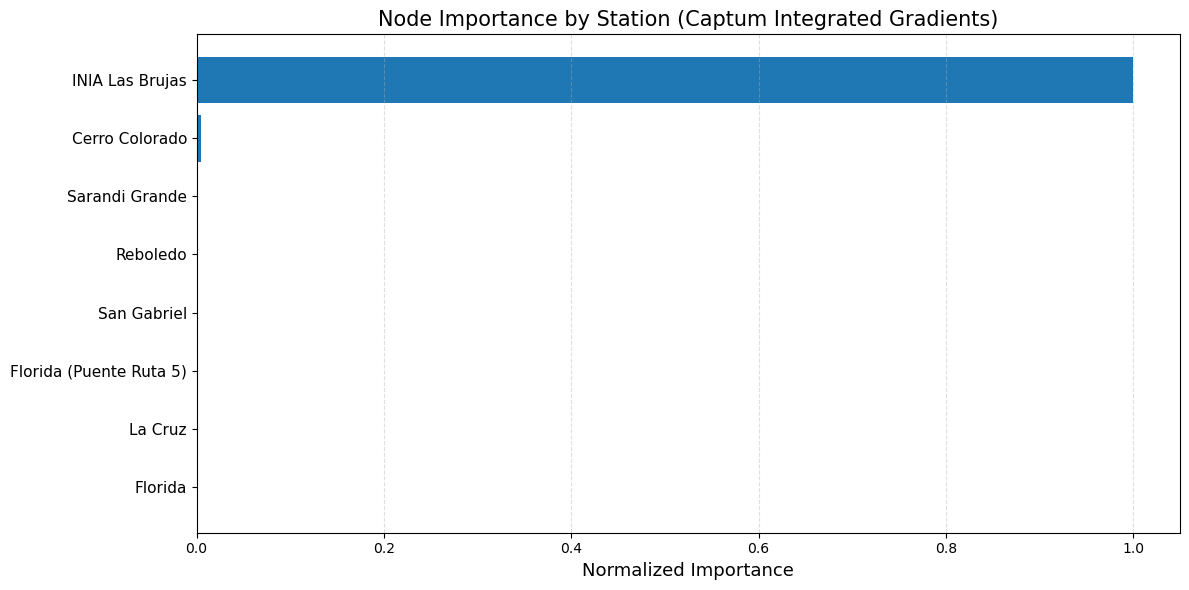

In [107]:
import matplotlib.pyplot as plt
import numpy as np

# Convert to numpy if needed
node_importance = np.array(node_importance)

# Sort nodes by importance
sorted_idx = np.argsort(node_importance)

sorted_importance = node_importance[sorted_idx]
sorted_stations = np.array(station_order)[sorted_idx]

# Plot
plt.figure(figsize=(12, 6))

bars = plt.barh(
    range(len(sorted_importance)),
    sorted_importance,
    alpha=0.9
)

# Highlight top 3 stations
top_k = 3
for i in range(1, top_k + 1):
    bars[-i].set_alpha(1.0)

plt.yticks(
    range(len(sorted_stations)),
    sorted_stations,
    fontsize=11
)

plt.xlabel(
    "Normalized Importance",
    fontsize=13
)

plt.title(
    "Node Importance by Station (Captum Integrated Gradients)",
    fontsize=15
)

plt.grid(
    axis="x",
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()
plt.show()

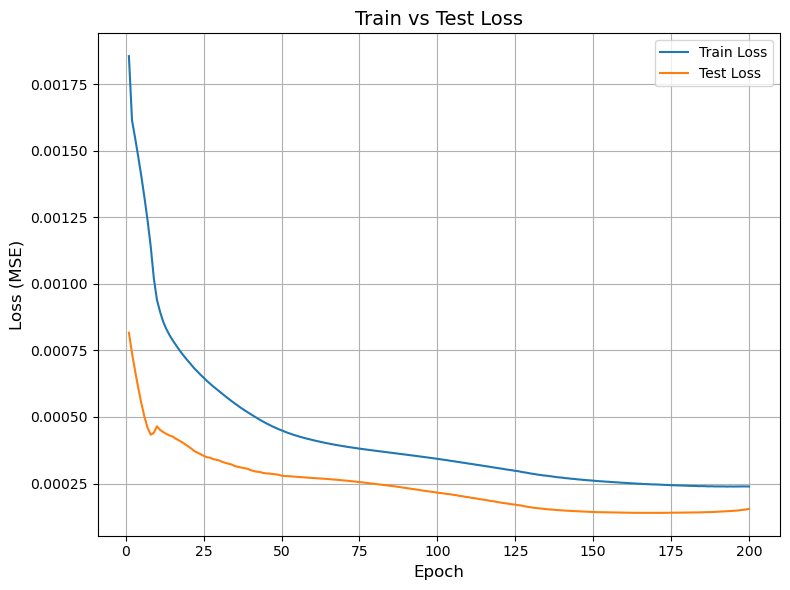

In [302]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8,6))

plt.plot(epochs, train_loss_list, label="Train Loss")
plt.plot(epochs, test_loss_list, label="Test Loss")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss (MSE)", fontsize=12)
plt.title("Train vs Test Loss", fontsize=14)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
plt.show()

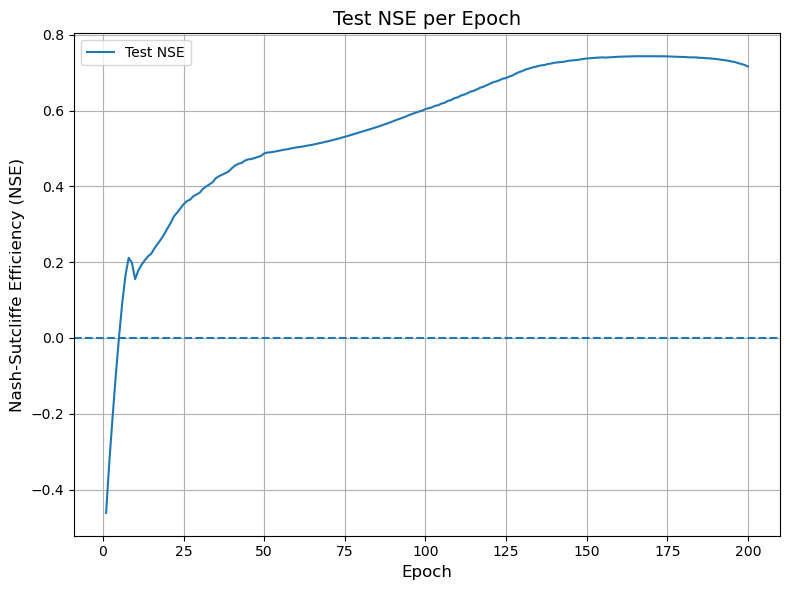

In [303]:
plt.figure(figsize=(8,6))

plt.plot(epochs, test_nse_list, label="Test NSE")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Nash-Sutcliffe Efficiency (NSE)", fontsize=12)
plt.title("Test NSE per Epoch", fontsize=14)

plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.axhline(0, linestyle="--")  # useful NSE reference

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
plt.show()

In [304]:
model.eval()

y_pred_train = []
y_pred_test = []

with torch.no_grad():

    for data in dataset_train:

        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
        else:
            out = model(data.x, data.edge_index)  # Perform a single forward pass.

        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_train.append(target_true_inv)

    for data in dataset_test:
        
        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
        else:
            out = model(data.x, data.edge_index)  # Perform a single forward pass.

        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_test.append(target_true_inv)

y_pred_train = np.array(y_pred_train)
y_pred_test = np.array(y_pred_test)

# Combine predictions
y_pred = np.concatenate([
    y_pred_train,
    y_pred_test
])

In [306]:
nse_metric(y_true_test, y_pred_test)

0.7160024095306304

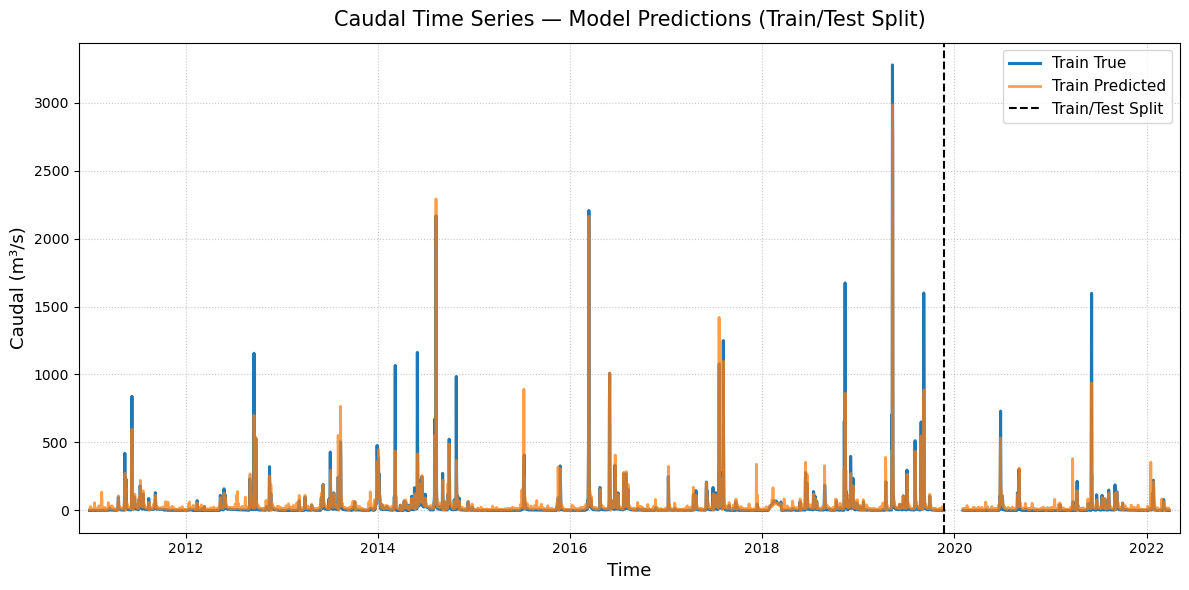

In [305]:
import numpy as np

# True values (NO SHUFFLE — keep temporal order)
y_true_all = df_data_all.loc[:, target_col].values

split_index = int(len(y_true_all) * train_ratio)

y_true_train = y_true_all[:split_index]
y_true_test = y_true_all[split_index:]

# Remove window offset (VERY IMPORTANT)
y_true_train = y_true_train[window_size:]
y_true_test = y_true_test[window_size:]

samples_train = y_true_train.size
samples_test = y_true_test.size

y_pred_train = y_pred[:samples_train].squeeze()
y_pred_test = y_pred[samples_train:].squeeze()

time = df_data_all.index

# --- Style settings
plt.figure(figsize=(12, 6))

# Colorblind-friendly colors
color_true = "#1f77b4"   # blue
color_pred = "#ff7f0e"   # orange

lw_true = 2.2
lw_pred = 2.0

# --- Training data (solid lines)

plt.plot(
    time[:samples_train],
    y_true_train,
    label="Train True",
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[:samples_train],
    y_pred_train,
    label="Train Predicted",
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75   # transparency helps overlap visibility
)

# --- Testing data (dashed lines)

plt.plot(
    time[-samples_test:],
    y_true_test,
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[-samples_test:],
    y_pred_test,
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75
)

# --- Divider line

plt.axvline(
    x=time[samples_train],
    linestyle="--",
    linewidth=1.5,
    color="black",
    label="Train/Test Split"
)

# --- Labels and formatting

plt.xlabel("Time", fontsize=13)
plt.ylabel("Caudal (m³/s)", fontsize=13)

plt.title(
    "Caudal Time Series — Model Predictions (Train/Test Split)",
    fontsize=15,
    pad=12
)

plt.legend(fontsize=11)

plt.grid(
    True,
    linestyle=":",
    linewidth=0.8,
    alpha=0.7
)

plt.margins(x=0.01)

plt.tight_layout()
plt.show()

## Graph Definition

### Test 3: Sugerencia Angela

<img src="notebook_imgs/grafo1.jpg" width="50%">

In [307]:
target_station = "Florida (Puente Ruta 5)"
target_variable = "Caudal (Q) [m3/s]"

all_cols = list(df_data_all.columns)
all_stations = [
    re.search(r"\[(.*?)\]", e).group(1)
    for e in all_cols
]
station_order = list(dict.fromkeys(all_stations)) # Remove duplicates from list while preserving order of elements

stations_coords = pd.read_csv(data_folder+"other_data/SL_stations.csv")

stations_coords = stations_coords[stations_coords["station"].isin(station_order)] # Keep only stations inside Florida's basin
stations_coords = stations_coords.set_index('station') # Define new index

# --- (1) Se definen las distancias ---

coords_list = [
        (stations_coords.loc[s, 'longitud'],
        stations_coords.loc[s, 'latitud'])
    for s in station_order
]

target_station_coords = [stations_coords.loc[target_station, 'longitud'],
                            stations_coords.loc[target_station, 'latitud']]

In [309]:
# --- (2) Se define la conectividad del grafo ---

# Se incorpora un self loop
edge_index = torch.tensor([
    [2, 3, 4, 5, 6, 7, 1, 1, 1, 1, 1, 1],
    [0, 0, 0, 0, 0, 0, 2, 3, 4, 5, 6, 7]
], dtype=torch.long)
edge_index

tensor([[2, 3, 4, 5, 6, 7, 1, 1, 1, 1, 1, 1],
        [0, 0, 0, 0, 0, 0, 2, 3, 4, 5, 6, 7]])

In [313]:
# --- (3) Se calculan las distancias de los nodos ---

row, col = edge_index

coords = torch.tensor(coords_list, dtype=torch.float)

distances = torch.linalg.norm(
    coords[row] - coords[col],
    dim=1
)


# ---- Prevent extremely small distances ----

min_dist = distances.quantile(0.1)  # 10th percentile
distances = torch.clamp(distances, min=min_dist)

# ---- Gaussian weighting ----

sigma = distances.mean()

weights = torch.exp(
    - (distances ** 2) / (2 * sigma ** 2)
)

# Normalize to [0,1]
weights = (weights - weights.min()) / (
    weights.max() - weights.min()
)

dist_weight = weights.view(-1, 1)
dist_weight

tensor([[0.4577],
        [1.0000],
        [1.0000],
        [0.6228],
        [0.8869],
        [0.8267],
        [0.0000],
        [0.5667],
        [0.3802],
        [0.1438],
        [0.3420],
        [0.1571]])

In [314]:
from collections import defaultdict

def extract_station(col):
    return re.match(r"\[(.*?)\]", col).group(1)

station_columns = defaultdict(list)

for col in df_data_all.columns:
    st = extract_station(col)
    station_columns[st].append(col)

In [315]:
def extract_variable(col):
    return re.sub(r"\[.*?\]\s*", "", col)

variable_order = [c.split("] ", 1)[1] for c in df_data_all.columns]
variable_order = list(dict.fromkeys(variable_order))

In [316]:
from sklearn.model_selection import train_test_split

train_ratio = 0.8
test_ratio = 0.2

# First split: train vs (val + test)
df_train, df_test = train_test_split(
    df_data_all,
    train_size=train_ratio,
    shuffle=False
)

# Second split: val vs test
# dataset_val, dataset_test = train_test_split(
#     df_data_all,
#     train_size=val_ratio / (1 - train_ratio),
#     shuffle=False
# )
#print(f"N° val samples: {len(dataset_val.index)}")

print(f"N° train samples: {len(df_train.index)}")
print(f"N° test samples: {len(df_test.index)}")


N° train samples: 3284
N° test samples: 821


In [317]:
from sklearn.preprocessing import MinMaxScaler
import pandas as pd

scalerX = MinMaxScaler()
scalerY = MinMaxScaler()

target_col = f"[{target_station}] {target_variable}"


df_train_scaled = df_train.copy()

X_train = df_train_scaled.drop(columns=[target_col])
y_train = df_train_scaled[[target_col]] 

# Fit scalers
X_train_scaled = scalerX.fit_transform(X_train)
y_train_scaled = scalerY.fit_transform(y_train)

# Assign back
df_train_scaled[X_train.columns] = X_train_scaled
df_train_scaled[target_col] = y_train_scaled


df_test_scaled = df_test.copy()

X_test = df_test_scaled.drop(columns=[target_col])
y_test = df_test_scaled[[target_col]]

# Transform only
X_test_scaled = scalerX.transform(X_test)
y_test_scaled = scalerY.transform(y_test)

# Assign back
df_test_scaled[X_test.columns] = X_test_scaled
df_test_scaled[target_col] = y_test_scaled

In [318]:
import torch
import numpy as np

num_nodes = len(station_order)
num_features = len(variable_order)
num_time_train = len(df_train_scaled)
num_time_test = len(df_test_scaled)

X_all_train = torch.zeros(
    (num_nodes, num_time_train, num_features),
    dtype=torch.float32
)

X_all_test = torch.zeros(
    (num_nodes, num_time_test, num_features),
    dtype=torch.float32
)

for i, station in enumerate(station_order):

    for j, variable in enumerate(variable_order):

        col_name = f"[{station}] {variable}"

        if col_name in df_train_scaled.columns:

            X_all_train[i, :, j] = torch.tensor(
                df_train_scaled[col_name].values,
                dtype=torch.float32
            )

            X_all_test[i, :, j] = torch.tensor(
                df_test_scaled[col_name].values,
                dtype=torch.float32
            )

        else:
            # missing variable at station
            X_all_train[i, :, j] = 0.0
            X_all_test[i, :, j] = 0.0

In [ ]:
import torch
from torch_geometric.data import Data

# Return list of windowed graph data
# In this case: 
# - input_window = "window"
# - output_window = 1

def build_windowed_graphs(
    x_all,                     # [num_nodes, T, num_features]
    edge_index,                # [2, num_edges]
    edge_weight=None,          # [num_nodes, num_features]
    window=12,
    target_feature_idx=0,      # feature to predict
    target_node_idx=None       # None → predict for all nodes
):

    num_nodes, T, num_features = x_all.shape

    data_list = []

    for t in range(T - window):

        # Input window
        x_window = x_all[:, t:t+window, :].clone()  # shape: [num_nodes, window, num_features]

        # Self loop --> Use target as input (don't make feature zeros!)
        x_window[:, :, target_feature_idx] = 0

        # Target timestep
        y_full = x_all[:, t+window, target_feature_idx]  # shape: [num_nodes]
        
        # If: 
        #   target_node_idx = None --> Predict all variables
        #   target_node_idx = idx --> Predict 'idx' variable
        if target_node_idx is not None:
            y = y_full[target_node_idx]  # shape: scalar
        else:
            y = y_full  # shape: [num_nodes]

        data = Data(
            x=x_window,
            edge_index=edge_index,
            edge_weight=edge_weight,
            y=y
        )

        data_list.append(data)

    return data_list

In [320]:
target_feature_idx = variable_order.index(target_variable) # Variable --> Feature
target_node_idx = station_order.index(target_station) # Station --> Node

edge_weight = dist_weight/dist_weight.sum() # Distance normalization --> edge weights
window_size = 36

dataset_train = build_windowed_graphs(
    X_all_train,
    edge_index,
    edge_weight,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx
)

dataset_test = build_windowed_graphs(
    X_all_test,
    edge_index,
    edge_weight,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx
)

print(f"Length train: {len(dataset_train)}")
print(f"Graph train: {dataset_train[0]}")
print(f"Length test: {len(dataset_test)}")
print(f"Graph test: {dataset_test[0]}")

Length train: 3248
Graph train: Data(x=[8, 36, 10], edge_index=[2, 12], y=4.089299181941897e-05, edge_weight=[12, 1])
Length test: 785
Graph test: Data(x=[8, 36, 10], edge_index=[2, 12], y=0.0004632504715118557, edge_weight=[12, 1])


### Modelo

In [321]:
import torch
import torch.nn as nn
from torch_geometric.nn import GraphConv
from torch.nn import GRU

class BasicGNN(nn.Module):

    def __init__(self, num_features, gnn_hidden, rnn_hidden, out_channels):
        super().__init__()

        self.gnn_hidden = gnn_hidden
        self.num_features = num_features

        self.gconv1 = GraphConv(num_features, gnn_hidden)
        #self.gconv2 = GraphConv(gnn_hidden, gnn_hidden)

        self.rnn = nn.GRU(
            input_size=gnn_hidden,
            hidden_size=rnn_hidden,
            batch_first=True,
        )

        self.fc = nn.Linear(
            rnn_hidden,
            out_channels
        )

    def forward(self, x, edge_index, edge_weight=None):

        # x:
        # [num_nodes, time_window, features]
        N, T, F = x.shape

        gnn_outputs = []

        # Apply conv layer to each data point independently
        for t in range(T):

            x_t = x[:, t, :]  # [num_nodes, features]

            h_t = self.gconv1(
                x_t,
                edge_index=edge_index,
                edge_weight=edge_weight
            )  # [num_nodes, gnn_hidden]
            h_t = actF.relu(h_t)

            gnn_outputs.append(h_t)

        #print(f"Len out before: {len(gnn_outputs)}")
        #print(f"out before: {gnn_outputs[0].shape}")
        
        # Stack time: [num_nodes, time_window, gnn_hidden]
        h = torch.stack(gnn_outputs, dim=1)
        
        #print(f"h stack: {h.shape}")

        # RNN
        h, _ = self.rnn(h)

        # Take last timestep
        h_last = h[:, -1, :]

        # Prediction
        out = self.fc(h_last)

        #print(f"OUT {out.shape}")

        return out.squeeze()

In [322]:
from torch_geometric.loader import DataLoader
batch_dize = 64

train_loader = DataLoader(dataset_train, batch_size=batch_dize, shuffle=False)
test_loader = DataLoader(dataset_test, batch_size=batch_dize, shuffle=False)

In [323]:
from sklearn.metrics import r2_score as nse_metric

num_features = dataset_train[0]["x"].shape[2]

model = BasicGNN(
    num_features=num_features,
    gnn_hidden=16, 
    rnn_hidden=16,
    out_channels=1
)

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)
criterion = nn.MSELoss()

def train(model, criterion, optimizer, train_loader, use_weigths):
    model.train()
    total_train_loss = 0

    for data in train_loader:

        optimizer.zero_grad()  # Clear gradients.

        # print(f"X: {data.x.shape}")
        # print(f"edge_index: {data.edge_index.shape}")
        # print(f"edge_weight: {data.edge_weight.shape}")
        # print(f"y: {data.y.shape}")

        #print(data.edge_weight)

        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
        else:
            out = model(data.x, data.edge_index)  # Perform a single forward pass.

        # out: [num_nodes x batch_size, num_features] ---> We want 'Caudal' for Node 'Florida' (slice array by num_nodes)
        target_prediction = out[target_node_idx::num_nodes]

        # print(f"target shape out: {target_prediction.shape}")
        # print(f"target out: {target_prediction}")

        train_loss = criterion(target_prediction, data.y)  # Compute the loss solely based on the training nodes.

        train_loss.backward()  # Derive gradients.
        optimizer.step()  # Update parameters based on gradients.

        total_train_loss += train_loss.item()

    return total_train_loss / len(train_loader)

def test(model, criterion, test_loader, use_weigths):
    model.eval()

    total_loss = 0.0

    all_preds_inv = []
    all_targets_inv = []

    with torch.no_grad():
        for data in test_loader:

            if use_weigths:
                out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
            else:
                out = model(data.x, data.edge_index)  # Perform a single forward pass.

            #print(out.shape)
            #print(out)

            # out: [num_nodes x batch_size, num_features] ---> We want 'Caudal' for Node 'Florida' (slice array by num_nodes)
            target_prediction = out[target_node_idx::num_nodes]

            target_prediction_inv = scalerY.inverse_transform(target_prediction.reshape(-1, 1))
            target_true_inv = scalerY.inverse_transform(data.y.reshape(-1, 1))

            # Loss (e.g., MSELoss)
            loss = criterion(target_prediction, data.y)

            total_loss += loss.item()

            # Before appending inverse pred for NSE evaluation, make negative predictions zero
            target_prediction_inv[target_prediction_inv<0] = 0
            #print(f"Despues: {(target_prediction_inv<0).sum()}")

            all_preds_inv.append(torch.from_numpy(target_prediction_inv))
            all_targets_inv.append(torch.from_numpy(target_true_inv))

    all_preds_inv = torch.cat(all_preds_inv)

    all_targets_inv = torch.cat(all_targets_inv)

    nse = nse_metric(all_targets_inv, all_preds_inv)

    avg_loss = total_loss / len(test_loader)

    return avg_loss, nse

In [324]:
num_epochs = 200

train_loss_list = []
test_loss_list = []
test_nse_list = []

use_weigths = False

for epoch in range(num_epochs):
    loss = train(model, criterion, optimizer, train_loader, use_weigths)
    test_loss, test_nse = test(model, criterion, test_loader, use_weigths)

    train_loss_list.append(loss)
    test_loss_list.append(test_loss)
    test_nse_list.append(test_nse)

    print(
        f"Epoch [{1+epoch:03d}/{num_epochs}] | "
        f"Train Loss: {loss:.6f} | "
        f"Test Loss: {test_loss:.6f} | "
        f"Test NSE: {test_nse:.2f}"
    )

if use_weigths:
    torch.save(model, 'models/BasicGNN_Arq2_weigths.pth')
else:
    torch.save(model, 'models/BasicGNN_Arq2_noweigths.pth')

Epoch [001/200] | Train Loss: 0.002436 | Test Loss: 0.000437 | Test NSE: 0.20
Epoch [002/200] | Train Loss: 0.000854 | Test Loss: 0.000509 | Test NSE: 0.07
Epoch [003/200] | Train Loss: 0.000803 | Test Loss: 0.000554 | Test NSE: -0.02
Epoch [004/200] | Train Loss: 0.000766 | Test Loss: 0.000574 | Test NSE: -0.06
Epoch [005/200] | Train Loss: 0.000727 | Test Loss: 0.000591 | Test NSE: -0.09
Epoch [006/200] | Train Loss: 0.000689 | Test Loss: 0.000604 | Test NSE: -0.11
Epoch [007/200] | Train Loss: 0.000655 | Test Loss: 0.000610 | Test NSE: -0.12
Epoch [008/200] | Train Loss: 0.000626 | Test Loss: 0.000616 | Test NSE: -0.13
Epoch [009/200] | Train Loss: 0.000602 | Test Loss: 0.000616 | Test NSE: -0.13
Epoch [010/200] | Train Loss: 0.000579 | Test Loss: 0.000616 | Test NSE: -0.13
Epoch [011/200] | Train Loss: 0.000558 | Test Loss: 0.000614 | Test NSE: -0.13
Epoch [012/200] | Train Loss: 0.000540 | Test Loss: 0.000612 | Test NSE: -0.13
Epoch [013/200] | Train Loss: 0.000523 | Test Loss: 0.

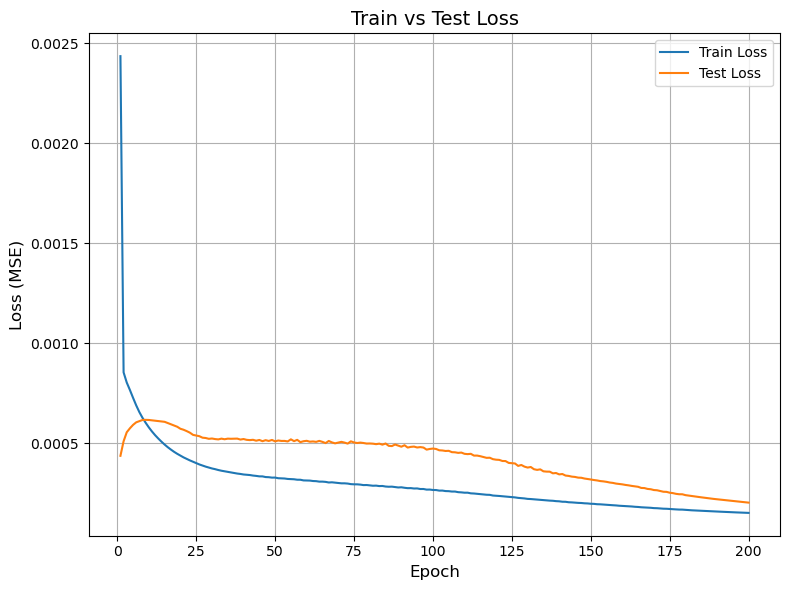

In [325]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8,6))

plt.plot(epochs, train_loss_list, label="Train Loss")
plt.plot(epochs, test_loss_list, label="Test Loss")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss (MSE)", fontsize=12)
plt.title("Train vs Test Loss", fontsize=14)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
plt.show()

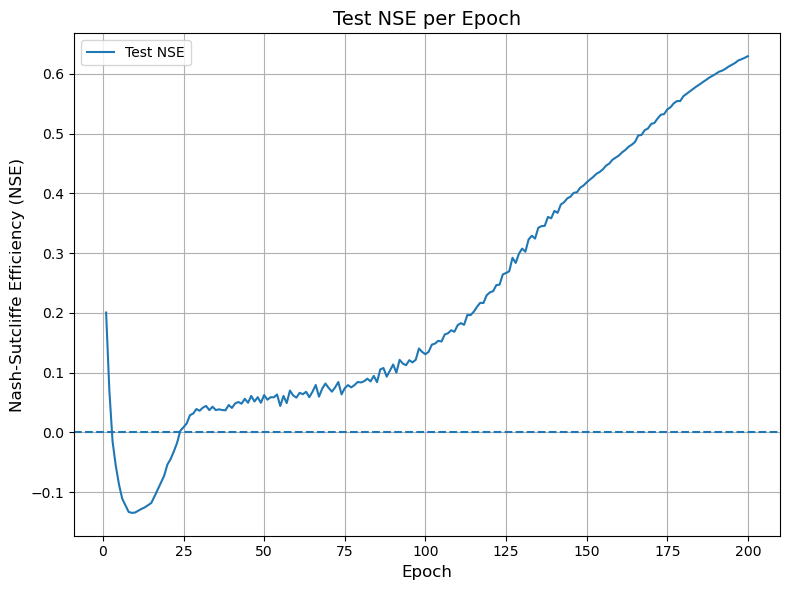

In [326]:
plt.figure(figsize=(8,6))

plt.plot(epochs, test_nse_list, label="Test NSE")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Nash-Sutcliffe Efficiency (NSE)", fontsize=12)
plt.title("Test NSE per Epoch", fontsize=14)

plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.axhline(0, linestyle="--")  # useful NSE reference

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
plt.show()

In [327]:
model.eval()

y_pred_train = []
y_pred_test = []

with torch.no_grad():

    for data in dataset_train:

        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
        else:
            out = model(data.x, data.edge_index)  # Perform a single forward pass.

        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_train.append(target_true_inv)

    for data in dataset_test:
        
        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
        else:
            out = model(data.x, data.edge_index)  # Perform a single forward pass.

        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_test.append(target_true_inv)

y_pred_train = np.array(y_pred_train)
y_pred_test = np.array(y_pred_test)

# Combine predictions
y_pred = np.concatenate([
    y_pred_train,
    y_pred_test
])

In [330]:
nse_metric(y_true_test, y_pred_test)

0.6297714507029252

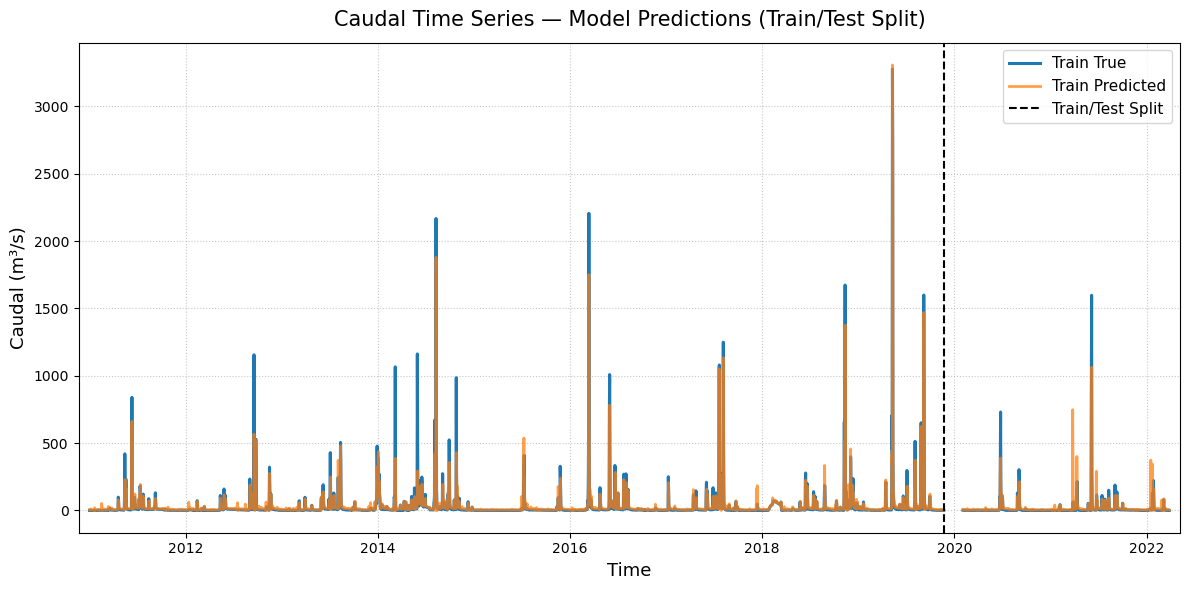

In [329]:
import numpy as np

# True values (NO SHUFFLE — keep temporal order)
y_true_all = df_data_all.loc[:, target_col].values

split_index = int(len(y_true_all) * train_ratio)

y_true_train = y_true_all[:split_index]
y_true_test = y_true_all[split_index:]

# Remove window offset (VERY IMPORTANT)
y_true_train = y_true_train[window_size:]
y_true_test = y_true_test[window_size:]

samples_train = y_true_train.size
samples_test = y_true_test.size

y_pred_train = y_pred[:samples_train].squeeze()
y_pred_test = y_pred[samples_train:].squeeze()

time = df_data_all.index

# --- Style settings
plt.figure(figsize=(12, 6))

# Colorblind-friendly colors
color_true = "#1f77b4"   # blue
color_pred = "#ff7f0e"   # orange

lw_true = 2.2
lw_pred = 2.0

# --- Training data (solid lines)

plt.plot(
    time[:samples_train],
    y_true_train,
    label="Train True",
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[:samples_train],
    y_pred_train,
    label="Train Predicted",
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75   # transparency helps overlap visibility
)

# --- Testing data (dashed lines)

plt.plot(
    time[-samples_test:],
    y_true_test,
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[-samples_test:],
    y_pred_test,
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75
)

# --- Divider line

plt.axvline(
    x=time[samples_train],
    linestyle="--",
    linewidth=1.5,
    color="black",
    label="Train/Test Split"
)

# --- Labels and formatting

plt.xlabel("Time", fontsize=13)
plt.ylabel("Caudal (m³/s)", fontsize=13)

plt.title(
    "Caudal Time Series — Model Predictions (Train/Test Split)",
    fontsize=15,
    pad=12
)

plt.legend(fontsize=11)

plt.grid(
    True,
    linestyle=":",
    linewidth=0.8,
    alpha=0.7
)

plt.margins(x=0.01)

plt.tight_layout()
plt.show()

## Graph

### Trial v3: With weights

In [331]:
target_station = "Florida (Puente Ruta 5)"
target_variable = "Caudal (Q) [m3/s]"

all_cols = list(df_data_all.columns)
all_stations = [
    re.search(r"\[(.*?)\]", e).group(1)
    for e in all_cols
]
station_order = list(dict.fromkeys(all_stations)) # Remove duplicates from list while preserving order of elements

stations_coords = pd.read_csv(data_folder+"other_data/SL_stations.csv")

stations_coords = stations_coords[stations_coords["station"].isin(station_order)] # Keep only stations inside Florida's basin
stations_coords = stations_coords.set_index('station') # Define new index

# --- (1) Se definen las distancias ---

coords_list = [
        (stations_coords.loc[s, 'longitud'],
        stations_coords.loc[s, 'latitud'])
    for s in station_order
]

target_station_coords = [stations_coords.loc[target_station, 'longitud'],
                            stations_coords.loc[target_station, 'latitud']]

In [332]:
# --- (2) Se define la conectividad del grafo ---

# Se incorpora un self loop
edge_index = torch.tensor([
    [2, 3, 4, 5, 6, 7, 1, 1, 1, 1, 1, 1],
    [0, 0, 0, 0, 0, 0, 2, 3, 4, 5, 6, 7]
], dtype=torch.long)
edge_index

tensor([[2, 3, 4, 5, 6, 7, 1, 1, 1, 1, 1, 1],
        [0, 0, 0, 0, 0, 0, 2, 3, 4, 5, 6, 7]])

In [333]:
# --- (3) Se calculan las distancias de los nodos ---

row, col = edge_index

coords = torch.tensor(coords_list, dtype=torch.float)

distances = torch.linalg.norm(
    coords[row] - coords[col],
    dim=1
)


# ---- Prevent extremely small distances ----

min_dist = distances.quantile(0.1)  # 10th percentile
distances = torch.clamp(distances, min=min_dist)

# ---- Gaussian weighting ----

sigma = distances.mean()

weights = torch.exp(
    - (distances ** 2) / (2 * sigma ** 2)
)

# Normalize to [0,1]
weights = (weights - weights.min()) / (
    weights.max() - weights.min()
)

dist_weight = weights.view(-1, 1)
dist_weight

tensor([[0.4577],
        [1.0000],
        [1.0000],
        [0.6228],
        [0.8869],
        [0.8267],
        [0.0000],
        [0.5667],
        [0.3802],
        [0.1438],
        [0.3420],
        [0.1571]])

In [334]:
from collections import defaultdict

def extract_station(col):
    return re.match(r"\[(.*?)\]", col).group(1)

station_columns = defaultdict(list)

for col in df_data_all.columns:
    st = extract_station(col)
    station_columns[st].append(col)

In [335]:
def extract_variable(col):
    return re.sub(r"\[.*?\]\s*", "", col)

variable_order = [c.split("] ", 1)[1] for c in df_data_all.columns]
variable_order = list(dict.fromkeys(variable_order))

In [336]:
from sklearn.model_selection import train_test_split

train_ratio = 0.8
test_ratio = 0.2

# First split: train vs (val + test)
df_train, df_test = train_test_split(
    df_data_all,
    train_size=train_ratio,
    shuffle=False
)

# Second split: val vs test
# dataset_val, dataset_test = train_test_split(
#     df_data_all,
#     train_size=val_ratio / (1 - train_ratio),
#     shuffle=False
# )
#print(f"N° val samples: {len(dataset_val.index)}")

print(f"N° train samples: {len(df_train.index)}")
print(f"N° test samples: {len(df_test.index)}")


N° train samples: 3284
N° test samples: 821


In [337]:
from sklearn.preprocessing import MinMaxScaler
import pandas as pd

scalerX = MinMaxScaler()
scalerY = MinMaxScaler()

target_col = f"[{target_station}] {target_variable}"


df_train_scaled = df_train.copy()

X_train = df_train_scaled.drop(columns=[target_col])
y_train = df_train_scaled[[target_col]] 

# Fit scalers
X_train_scaled = scalerX.fit_transform(X_train)
y_train_scaled = scalerY.fit_transform(y_train)

# Assign back
df_train_scaled[X_train.columns] = X_train_scaled
df_train_scaled[target_col] = y_train_scaled


df_test_scaled = df_test.copy()

X_test = df_test_scaled.drop(columns=[target_col])
y_test = df_test_scaled[[target_col]]

# Transform only
X_test_scaled = scalerX.transform(X_test)
y_test_scaled = scalerY.transform(y_test)

# Assign back
df_test_scaled[X_test.columns] = X_test_scaled
df_test_scaled[target_col] = y_test_scaled

In [338]:
import torch
import numpy as np

num_nodes = len(station_order)
num_features = len(variable_order)
num_time_train = len(df_train_scaled)
num_time_test = len(df_test_scaled)

X_all_train = torch.zeros(
    (num_nodes, num_time_train, num_features),
    dtype=torch.float32
)

X_all_test = torch.zeros(
    (num_nodes, num_time_test, num_features),
    dtype=torch.float32
)

for i, station in enumerate(station_order):

    for j, variable in enumerate(variable_order):

        col_name = f"[{station}] {variable}"

        if col_name in df_train_scaled.columns:

            X_all_train[i, :, j] = torch.tensor(
                df_train_scaled[col_name].values,
                dtype=torch.float32
            )

            X_all_test[i, :, j] = torch.tensor(
                df_test_scaled[col_name].values,
                dtype=torch.float32
            )

        else:
            # missing variable at station
            X_all_train[i, :, j] = 0.0
            X_all_test[i, :, j] = 0.0

In [339]:
import torch
from torch_geometric.data import Data

# Return list of windowed graph data
# In this case: 
# - input_window = "window"
# - output_window = 1

def build_windowed_graphs(
    x_all,                     # [num_nodes, T, num_features]
    edge_index,                # [2, num_edges]
    edge_weight=None,          # [num_nodes, num_features]
    window=12,
    target_feature_idx=0,      # feature to predict
    target_node_idx=None       # None → predict for all nodes
):

    num_nodes, T, num_features = x_all.shape

    data_list = []

    for t in range(T - window):

        # Input window
        x_window = x_all[:, t:t+window, :].clone()  # shape: [num_nodes, window, num_features]

        # Self loop --> Use target as input (don't make feature zeros!)
        x_window[:, :, target_feature_idx] = 0

        # Target timestep
        y_full = x_all[:, t+window, target_feature_idx]  # shape: [num_nodes]
        
        # If: 
        #   target_node_idx = None --> Predict all variables
        #   target_node_idx = idx --> Predict 'idx' variable
        if target_node_idx is not None:
            y = y_full[target_node_idx]  # shape: scalar
        else:
            y = y_full  # shape: [num_nodes]

        data = Data(
            x=x_window,
            edge_index=edge_index,
            edge_weight=edge_weight,
            y=y
        )

        data_list.append(data)

    return data_list

In [340]:
target_feature_idx = variable_order.index(target_variable) # Variable --> Feature
target_node_idx = station_order.index(target_station) # Station --> Node

edge_weight = dist_weight/dist_weight.sum() # Distance normalization --> edge weights
window_size = 36

dataset_train = build_windowed_graphs(
    X_all_train,
    edge_index,
    edge_weight,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx
)

dataset_test = build_windowed_graphs(
    X_all_test,
    edge_index,
    edge_weight,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx
)

print(f"Length train: {len(dataset_train)}")
print(f"Graph train: {dataset_train[0]}")
print(f"Length test: {len(dataset_test)}")
print(f"Graph test: {dataset_test[0]}")

Length train: 3248
Graph train: Data(x=[8, 36, 10], edge_index=[2, 12], y=4.089299181941897e-05, edge_weight=[12, 1])
Length test: 785
Graph test: Data(x=[8, 36, 10], edge_index=[2, 12], y=0.0004632504715118557, edge_weight=[12, 1])


### Model

In [341]:
import torch
import torch.nn as nn
from torch_geometric.nn import GraphConv
from torch.nn import GRU

class BasicGNN(nn.Module):

    def __init__(self, num_features, gnn_hidden, rnn_hidden, out_channels):
        super().__init__()

        self.gnn_hidden = gnn_hidden
        self.num_features = num_features

        self.gconv1 = GraphConv(num_features, gnn_hidden)
        #self.gconv2 = GraphConv(gnn_hidden, gnn_hidden)

        self.rnn = nn.GRU(
            input_size=gnn_hidden,
            hidden_size=rnn_hidden,
            batch_first=True,
        )

        self.fc = nn.Linear(
            rnn_hidden,
            out_channels
        )

    def forward(self, x, edge_index, edge_weight=None):

        # x:
        # [num_nodes, time_window, features]
        N, T, F = x.shape

        gnn_outputs = []

        # Apply conv layer to each data point independently
        for t in range(T):

            x_t = x[:, t, :]  # [num_nodes, features]

            h_t = self.gconv1(
                x_t,
                edge_index=edge_index,
                edge_weight=edge_weight
            )  # [num_nodes, gnn_hidden]
            h_t = actF.relu(h_t)

            gnn_outputs.append(h_t)

        #print(f"Len out before: {len(gnn_outputs)}")
        #print(f"out before: {gnn_outputs[0].shape}")
        
        # Stack time: [num_nodes, time_window, gnn_hidden]
        h = torch.stack(gnn_outputs, dim=1)
        
        #print(f"h stack: {h.shape}")

        # RNN
        h, _ = self.rnn(h)

        # Take last timestep
        h_last = h[:, -1, :]

        # Prediction
        out = self.fc(h_last)

        #print(f"OUT {out.shape}")

        return out.squeeze()

In [342]:
from torch_geometric.loader import DataLoader
batch_dize = 64

train_loader = DataLoader(dataset_train, batch_size=batch_dize, shuffle=False)
test_loader = DataLoader(dataset_test, batch_size=batch_dize, shuffle=False)

In [343]:
from sklearn.metrics import r2_score as nse_metric

num_features = dataset_train[0]["x"].shape[2]

model = BasicGNN(
    num_features=num_features,
    gnn_hidden=16, 
    rnn_hidden=16,
    out_channels=1
)

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)
criterion = nn.MSELoss()

def train(model, criterion, optimizer, train_loader, use_weigths):
    model.train()
    total_train_loss = 0

    for data in train_loader:

        optimizer.zero_grad()  # Clear gradients.

        # print(f"X: {data.x.shape}")
        # print(f"edge_index: {data.edge_index.shape}")
        # print(f"edge_weight: {data.edge_weight.shape}")
        # print(f"y: {data.y.shape}")

        #print(data.edge_weight)

        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
        else:
            out = model(data.x, data.edge_index)  # Perform a single forward pass.

        # out: [num_nodes x batch_size, num_features] ---> We want 'Caudal' for Node 'Florida' (slice array by num_nodes)
        target_prediction = out[target_node_idx::num_nodes]

        # print(f"target shape out: {target_prediction.shape}")
        # print(f"target out: {target_prediction}")

        train_loss = criterion(target_prediction, data.y)  # Compute the loss solely based on the training nodes.

        train_loss.backward()  # Derive gradients.
        optimizer.step()  # Update parameters based on gradients.

        total_train_loss += train_loss.item()

    return total_train_loss / len(train_loader)

def test(model, criterion, test_loader, use_weigths):
    model.eval()

    total_loss = 0.0

    all_preds_inv = []
    all_targets_inv = []

    with torch.no_grad():
        for data in test_loader:

            if use_weigths:
                out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
            else:
                out = model(data.x, data.edge_index)  # Perform a single forward pass.

            #print(out.shape)
            #print(out)

            # out: [num_nodes x batch_size, num_features] ---> We want 'Caudal' for Node 'Florida' (slice array by num_nodes)
            target_prediction = out[target_node_idx::num_nodes]

            target_prediction_inv = scalerY.inverse_transform(target_prediction.reshape(-1, 1))
            target_true_inv = scalerY.inverse_transform(data.y.reshape(-1, 1))

            # Loss (e.g., MSELoss)
            loss = criterion(target_prediction, data.y)

            total_loss += loss.item()

            # Before appending inverse pred for NSE evaluation, make negative predictions zero
            target_prediction_inv[target_prediction_inv<0] = 0
            #print(f"Despues: {(target_prediction_inv<0).sum()}")

            all_preds_inv.append(torch.from_numpy(target_prediction_inv))
            all_targets_inv.append(torch.from_numpy(target_true_inv))

    all_preds_inv = torch.cat(all_preds_inv)

    all_targets_inv = torch.cat(all_targets_inv)

    nse = nse_metric(all_targets_inv, all_preds_inv)

    avg_loss = total_loss / len(test_loader)

    return avg_loss, nse

In [344]:
num_epochs = 200

train_loss_list = []
test_loss_list = []
test_nse_list = []

use_weigths = True

for epoch in range(num_epochs):
    loss = train(model, criterion, optimizer, train_loader, use_weigths)
    test_loss, test_nse = test(model, criterion, test_loader, use_weigths)

    train_loss_list.append(loss)
    test_loss_list.append(test_loss)
    test_nse_list.append(test_nse)

    print(
        f"Epoch [{1+epoch:03d}/{num_epochs}] | "
        f"Train Loss: {loss:.6f} | "
        f"Test Loss: {test_loss:.6f} | "
        f"Test NSE: {test_nse:.2f}"
    )

if use_weigths:
    torch.save(model, 'models/BasicGNN_Arq2_weigths.pth')
else:
    torch.save(model, 'models/BasicGNN_Arq2_noweigths.pth')

Epoch [001/200] | Train Loss: 0.116977 | Test Loss: 0.010952 | Test NSE: -0.03
Epoch [002/200] | Train Loss: 0.002793 | Test Loss: 0.000520 | Test NSE: 0.05
Epoch [003/200] | Train Loss: 0.001523 | Test Loss: 0.000541 | Test NSE: 0.01
Epoch [004/200] | Train Loss: 0.001498 | Test Loss: 0.000531 | Test NSE: 0.03
Epoch [005/200] | Train Loss: 0.001470 | Test Loss: 0.000523 | Test NSE: 0.05
Epoch [006/200] | Train Loss: 0.001442 | Test Loss: 0.000514 | Test NSE: 0.06
Epoch [007/200] | Train Loss: 0.001413 | Test Loss: 0.000506 | Test NSE: 0.08
Epoch [008/200] | Train Loss: 0.001384 | Test Loss: 0.000497 | Test NSE: 0.09
Epoch [009/200] | Train Loss: 0.001355 | Test Loss: 0.000490 | Test NSE: 0.11
Epoch [010/200] | Train Loss: 0.001325 | Test Loss: 0.000482 | Test NSE: 0.12
Epoch [011/200] | Train Loss: 0.001294 | Test Loss: 0.000476 | Test NSE: 0.13
Epoch [012/200] | Train Loss: 0.001263 | Test Loss: 0.000471 | Test NSE: 0.14
Epoch [013/200] | Train Loss: 0.001231 | Test Loss: 0.000466 | 

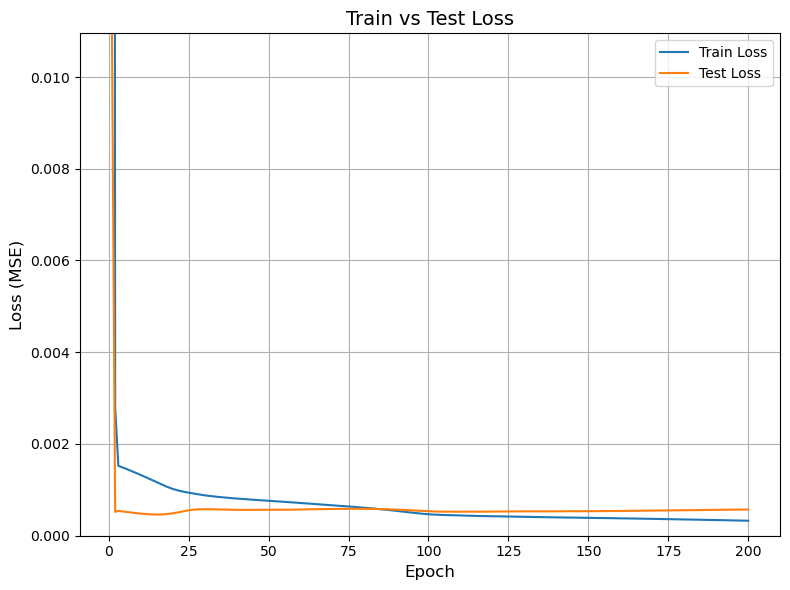

In [346]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8,6))

plt.plot(epochs, train_loss_list, label="Train Loss")
plt.plot(epochs, test_loss_list, label="Test Loss")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss (MSE)", fontsize=12)
plt.title("Train vs Test Loss", fontsize=14)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.ylim((0,max(test_loss_list)))

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
plt.show()

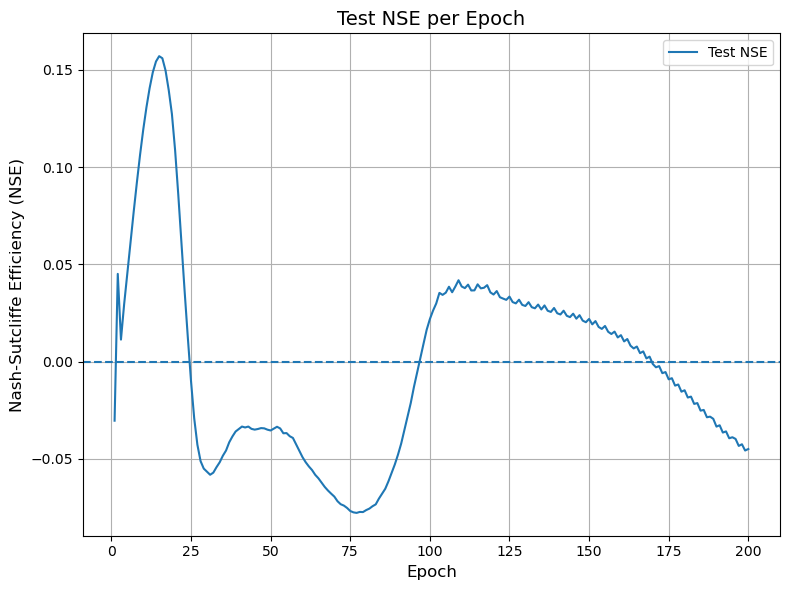

In [347]:
plt.figure(figsize=(8,6))

plt.plot(epochs, test_nse_list, label="Test NSE")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Nash-Sutcliffe Efficiency (NSE)", fontsize=12)
plt.title("Test NSE per Epoch", fontsize=14)

plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.axhline(0, linestyle="--")  # useful NSE reference

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
plt.show()

In [348]:
model.eval()

y_pred_train = []
y_pred_test = []

with torch.no_grad():

    for data in dataset_train:

        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
        else:
            out = model(data.x, data.edge_index)  # Perform a single forward pass.

        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_train.append(target_true_inv)

    for data in dataset_test:
        
        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
        else:
            out = model(data.x, data.edge_index)  # Perform a single forward pass.

        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_test.append(target_true_inv)

y_pred_train = np.array(y_pred_train)
y_pred_test = np.array(y_pred_test)

# Combine predictions
y_pred = np.concatenate([
    y_pred_train,
    y_pred_test
])

In [350]:
nse_metric(y_true_test, y_pred_test)

-0.04489923391218076

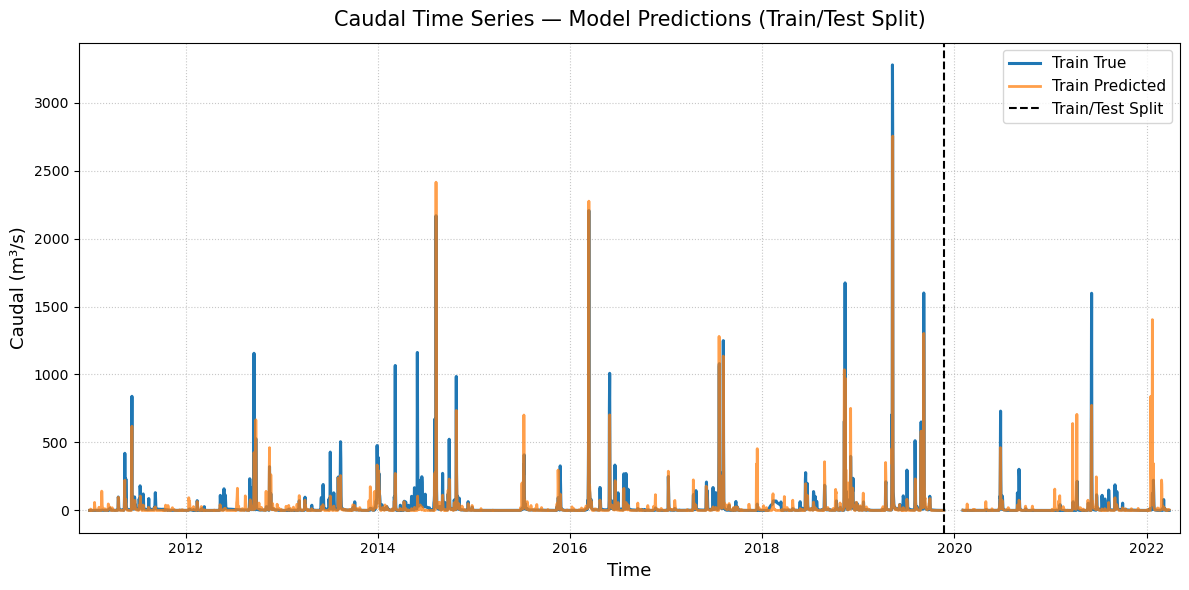

In [349]:
import numpy as np

# True values (NO SHUFFLE — keep temporal order)
y_true_all = df_data_all.loc[:, target_col].values

split_index = int(len(y_true_all) * train_ratio)

y_true_train = y_true_all[:split_index]
y_true_test = y_true_all[split_index:]

# Remove window offset (VERY IMPORTANT)
y_true_train = y_true_train[window_size:]
y_true_test = y_true_test[window_size:]

samples_train = y_true_train.size
samples_test = y_true_test.size

y_pred_train = y_pred[:samples_train].squeeze()
y_pred_test = y_pred[samples_train:].squeeze()

time = df_data_all.index

# --- Style settings
plt.figure(figsize=(12, 6))

# Colorblind-friendly colors
color_true = "#1f77b4"   # blue
color_pred = "#ff7f0e"   # orange

lw_true = 2.2
lw_pred = 2.0

# --- Training data (solid lines)

plt.plot(
    time[:samples_train],
    y_true_train,
    label="Train True",
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[:samples_train],
    y_pred_train,
    label="Train Predicted",
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75   # transparency helps overlap visibility
)

# --- Testing data (dashed lines)

plt.plot(
    time[-samples_test:],
    y_true_test,
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[-samples_test:],
    y_pred_test,
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75
)

# --- Divider line

plt.axvline(
    x=time[samples_train],
    linestyle="--",
    linewidth=1.5,
    color="black",
    label="Train/Test Split"
)

# --- Labels and formatting

plt.xlabel("Time", fontsize=13)
plt.ylabel("Caudal (m³/s)", fontsize=13)

plt.title(
    "Caudal Time Series — Model Predictions (Train/Test Split)",
    fontsize=15,
    pad=12
)

plt.legend(fontsize=11)

plt.grid(
    True,
    linestyle=":",
    linewidth=0.8,
    alpha=0.7
)

plt.margins(x=0.01)

plt.tight_layout()
plt.show()

## Grafo

### Trial 4: Metodo Angela y Self Loop

In [365]:
target_station = "Florida (Puente Ruta 5)"
target_variable = "Caudal (Q) [m3/s]"

all_cols = list(df_data_all.columns)
all_stations = [
    re.search(r"\[(.*?)\]", e).group(1)
    for e in all_cols
]
station_order = list(dict.fromkeys(all_stations)) # Remove duplicates from list while preserving order of elements

stations_coords = pd.read_csv(data_folder+"other_data/SL_stations.csv")

stations_coords = stations_coords[stations_coords["station"].isin(station_order)] # Keep only stations inside Florida's basin
stations_coords = stations_coords.set_index('station') # Define new index

# --- (1) Se definen las distancias ---

coords_list = [
        (stations_coords.loc[s, 'longitud'],
        stations_coords.loc[s, 'latitud'])
    for s in station_order
]

target_station_coords = [stations_coords.loc[target_station, 'longitud'],
                            stations_coords.loc[target_station, 'latitud']]

In [366]:
# --- (2) Se define la conectividad del grafo ---

# Se incorpora un self loop
edge_index = torch.tensor([
    [0, 2, 3, 4, 5, 6, 7, 1, 1, 1, 1, 1, 1],
    [0, 0, 0, 0, 0, 0, 0, 2, 3, 4, 5, 6, 7]
], dtype=torch.long)
edge_index

tensor([[0, 2, 3, 4, 5, 6, 7, 1, 1, 1, 1, 1, 1],
        [0, 0, 0, 0, 0, 0, 0, 2, 3, 4, 5, 6, 7]])

In [367]:
# --- (3) Se calculan las distancias de los nodos ---

row, col = edge_index

coords = torch.tensor(coords_list, dtype=torch.float)

distances = torch.linalg.norm(
    coords[row] - coords[col],
    dim=1
)


# ---- Prevent extremely small distances ----

min_dist = distances.quantile(0.1)  # 10th percentile
distances = torch.clamp(distances, min=min_dist)

# ---- Gaussian weighting ----

sigma = distances.mean()

weights = torch.exp(
    - (distances ** 2) / (2 * sigma ** 2)
)

# Normalize to [0,1]
weights = (weights - weights.min()) / (
    weights.max() - weights.min()
)

dist_weight = weights.view(-1, 1)
dist_weight

tensor([[1.0000],
        [0.3984],
        [1.0000],
        [0.9584],
        [0.5591],
        [0.8290],
        [0.7662],
        [0.0000],
        [0.5037],
        [0.3256],
        [0.1158],
        [0.2904],
        [0.1271]])

In [368]:
from collections import defaultdict

def extract_station(col):
    return re.match(r"\[(.*?)\]", col).group(1)

station_columns = defaultdict(list)

for col in df_data_all.columns:
    st = extract_station(col)
    station_columns[st].append(col)

In [369]:
def extract_variable(col):
    return re.sub(r"\[.*?\]\s*", "", col)

variable_order = [c.split("] ", 1)[1] for c in df_data_all.columns]
variable_order = list(dict.fromkeys(variable_order))

In [370]:
from sklearn.model_selection import train_test_split

train_ratio = 0.8
test_ratio = 0.2

# First split: train vs (val + test)
df_train, df_test = train_test_split(
    df_data_all,
    train_size=train_ratio,
    shuffle=False
)

# Second split: val vs test
# dataset_val, dataset_test = train_test_split(
#     df_data_all,
#     train_size=val_ratio / (1 - train_ratio),
#     shuffle=False
# )
#print(f"N° val samples: {len(dataset_val.index)}")

print(f"N° train samples: {len(df_train.index)}")
print(f"N° test samples: {len(df_test.index)}")


N° train samples: 3284
N° test samples: 821


In [371]:
from sklearn.preprocessing import MinMaxScaler
import pandas as pd

scalerX = MinMaxScaler()
scalerY = MinMaxScaler()

target_col = f"[{target_station}] {target_variable}"


df_train_scaled = df_train.copy()

X_train = df_train_scaled.drop(columns=[target_col])
y_train = df_train_scaled[[target_col]] 

# Fit scalers
X_train_scaled = scalerX.fit_transform(X_train)
y_train_scaled = scalerY.fit_transform(y_train)

# Assign back
df_train_scaled[X_train.columns] = X_train_scaled
df_train_scaled[target_col] = y_train_scaled


df_test_scaled = df_test.copy()

X_test = df_test_scaled.drop(columns=[target_col])
y_test = df_test_scaled[[target_col]]

# Transform only
X_test_scaled = scalerX.transform(X_test)
y_test_scaled = scalerY.transform(y_test)

# Assign back
df_test_scaled[X_test.columns] = X_test_scaled
df_test_scaled[target_col] = y_test_scaled

In [374]:
import torch
import numpy as np

num_nodes = len(station_order)
num_features = len(variable_order)
num_time_train = len(df_train_scaled)
num_time_test = len(df_test_scaled)

X_all_train = torch.zeros(
    (num_nodes, num_time_train, num_features),
    dtype=torch.float32
)

X_all_test = torch.zeros(
    (num_nodes, num_time_test, num_features),
    dtype=torch.float32
)

for i, station in enumerate(station_order):

    for j, variable in enumerate(variable_order):

        col_name = f"[{station}] {variable}"

        if col_name in df_train_scaled.columns:

            X_all_train[i, :, j] = torch.tensor(
                df_train_scaled[col_name].values,
                dtype=torch.float32
            )

            X_all_test[i, :, j] = torch.tensor(
                df_test_scaled[col_name].values,
                dtype=torch.float32
            )

        else:
            # missing variable at station
            X_all_train[i, :, j] = 0.0
            X_all_test[i, :, j] = 0.0

In [375]:
import torch
from torch_geometric.data import Data

# Return list of windowed graph data
# In this case: 
# - input_window = "window"
# - output_window = 1

def build_windowed_graphs(
    x_all,                     # [num_nodes, T, num_features]
    edge_index,                # [2, num_edges]
    edge_weight=None,          # [num_nodes, num_features]
    window=12,
    target_feature_idx=0,      # feature to predict
    target_node_idx=None       # None → predict for all nodes
):

    num_nodes, T, num_features = x_all.shape

    data_list = []

    for t in range(T - window):

        # Input window
        x_window = x_all[:, t:t+window, :].clone()  # shape: [num_nodes, window, num_features]

        # Self loop --> Use target as input (don't make feature zeros!)
        #x_window[:, :, target_feature_idx] = 0

        # Target timestep
        y_full = x_all[:, t+window, target_feature_idx]  # shape: [num_nodes]
        
        # If: 
        #   target_node_idx = None --> Predict all variables
        #   target_node_idx = idx --> Predict 'idx' variable
        if target_node_idx is not None:
            y = y_full[target_node_idx]  # shape: scalar
        else:
            y = y_full  # shape: [num_nodes]

        data = Data(
            x=x_window,
            edge_index=edge_index,
            edge_weight=edge_weight,
            y=y
        )

        data_list.append(data)

    return data_list

In [376]:
target_feature_idx = variable_order.index(target_variable) # Variable --> Feature
target_node_idx = station_order.index(target_station) # Station --> Node

edge_weight = dist_weight/dist_weight.sum() # Distance normalization --> edge weights
window_size = 36

dataset_train = build_windowed_graphs(
    X_all_train,
    edge_index,
    edge_weight,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx
)

dataset_test = build_windowed_graphs(
    X_all_test,
    edge_index,
    edge_weight,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx
)

print(f"Length train: {len(dataset_train)}")
print(f"Graph train: {dataset_train[0]}")
print(f"Length test: {len(dataset_test)}")
print(f"Graph test: {dataset_test[0]}")

Length train: 3248
Graph train: Data(x=[8, 36, 10], edge_index=[2, 13], y=4.089299181941897e-05, edge_weight=[13, 1])
Length test: 785
Graph test: Data(x=[8, 36, 10], edge_index=[2, 13], y=0.0004632504715118557, edge_weight=[13, 1])


### Model

In [377]:
import torch
import torch.nn as nn
from torch_geometric.nn import GraphConv
from torch.nn import GRU

class BasicGNN(nn.Module):

    def __init__(self, num_features, gnn_hidden, rnn_hidden, out_channels):
        super().__init__()

        self.gnn_hidden = gnn_hidden
        self.num_features = num_features

        self.gconv1 = GraphConv(num_features, gnn_hidden)
        #self.gconv2 = GraphConv(gnn_hidden, gnn_hidden)

        self.rnn = nn.GRU(
            input_size=gnn_hidden,
            hidden_size=rnn_hidden,
            batch_first=True,
        )

        self.fc = nn.Linear(
            rnn_hidden,
            out_channels
        )

    def forward(self, x, edge_index, edge_weight=None):

        # x:
        # [num_nodes, time_window, features]
        N, T, F = x.shape

        gnn_outputs = []

        # Apply conv layer to each data point independently
        for t in range(T):

            x_t = x[:, t, :]  # [num_nodes, features]

            h_t = self.gconv1(
                x_t,
                edge_index=edge_index,
                edge_weight=edge_weight
            )  # [num_nodes, gnn_hidden]
            h_t = actF.relu(h_t)

            gnn_outputs.append(h_t)

        #print(f"Len out before: {len(gnn_outputs)}")
        #print(f"out before: {gnn_outputs[0].shape}")
        
        # Stack time: [num_nodes, time_window, gnn_hidden]
        h = torch.stack(gnn_outputs, dim=1)
        
        #print(f"h stack: {h.shape}")

        # RNN
        h, _ = self.rnn(h)

        # Take last timestep
        h_last = h[:, -1, :]

        # Prediction
        out = self.fc(h_last)

        #print(f"OUT {out.shape}")

        return out.squeeze()

In [378]:
from torch_geometric.loader import DataLoader
batch_dize = 64

train_loader = DataLoader(dataset_train, batch_size=batch_dize, shuffle=False)
test_loader = DataLoader(dataset_test, batch_size=batch_dize, shuffle=False)

In [379]:
from sklearn.metrics import r2_score as nse_metric

num_features = dataset_train[0]["x"].shape[2]

model = BasicGNN(
    num_features=num_features,
    gnn_hidden=16, 
    rnn_hidden=16,
    out_channels=1
)

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)
criterion = nn.MSELoss()

def train(model, criterion, optimizer, train_loader, use_weigths):
    model.train()
    total_train_loss = 0

    for data in train_loader:

        optimizer.zero_grad()  # Clear gradients.

        # print(f"X: {data.x.shape}")
        # print(f"edge_index: {data.edge_index.shape}")
        # print(f"edge_weight: {data.edge_weight.shape}")
        # print(f"y: {data.y.shape}")

        #print(data.edge_weight)

        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
        else:
            out = model(data.x, data.edge_index)  # Perform a single forward pass.

        # out: [num_nodes x batch_size, num_features] ---> We want 'Caudal' for Node 'Florida' (slice array by num_nodes)
        target_prediction = out[target_node_idx::num_nodes]

        # print(f"target shape out: {target_prediction.shape}")
        # print(f"target out: {target_prediction}")

        train_loss = criterion(target_prediction, data.y)  # Compute the loss solely based on the training nodes.

        train_loss.backward()  # Derive gradients.
        optimizer.step()  # Update parameters based on gradients.

        total_train_loss += train_loss.item()

    return total_train_loss / len(train_loader)

def test(model, criterion, test_loader, use_weigths):
    model.eval()

    total_loss = 0.0

    all_preds_inv = []
    all_targets_inv = []

    with torch.no_grad():
        for data in test_loader:

            if use_weigths:
                out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
            else:
                out = model(data.x, data.edge_index)  # Perform a single forward pass.

            #print(out.shape)
            #print(out)

            # out: [num_nodes x batch_size, num_features] ---> We want 'Caudal' for Node 'Florida' (slice array by num_nodes)
            target_prediction = out[target_node_idx::num_nodes]

            target_prediction_inv = scalerY.inverse_transform(target_prediction.reshape(-1, 1))
            target_true_inv = scalerY.inverse_transform(data.y.reshape(-1, 1))

            # Loss (e.g., MSELoss)
            loss = criterion(target_prediction, data.y)

            total_loss += loss.item()

            # Before appending inverse pred for NSE evaluation, make negative predictions zero
            target_prediction_inv[target_prediction_inv<0] = 0
            #print(f"Despues: {(target_prediction_inv<0).sum()}")

            all_preds_inv.append(torch.from_numpy(target_prediction_inv))
            all_targets_inv.append(torch.from_numpy(target_true_inv))

    all_preds_inv = torch.cat(all_preds_inv)

    all_targets_inv = torch.cat(all_targets_inv)

    nse = nse_metric(all_targets_inv, all_preds_inv)

    avg_loss = total_loss / len(test_loader)

    return avg_loss, nse

In [380]:
num_epochs = 200

train_loss_list = []
test_loss_list = []
test_nse_list = []

use_weigths = False

for epoch in range(num_epochs):
    loss = train(model, criterion, optimizer, train_loader, use_weigths)
    test_loss, test_nse = test(model, criterion, test_loader, use_weigths)

    train_loss_list.append(loss)
    test_loss_list.append(test_loss)
    test_nse_list.append(test_nse)

    print(
        f"Epoch [{1+epoch:03d}/{num_epochs}] | "
        f"Train Loss: {loss:.6f} | "
        f"Test Loss: {test_loss:.6f} | "
        f"Test NSE: {test_nse:.2f}"
    )

if use_weigths:
    torch.save(model, 'models/BasicGNN_Arq4_weigths.pth')
else:
    torch.save(model, 'models/BasicGNN_Arq4_noweigths.pth')

Epoch [001/200] | Train Loss: 0.002927 | Test Loss: 0.000702 | Test NSE: -0.27
Epoch [002/200] | Train Loss: 0.001479 | Test Loss: 0.000593 | Test NSE: -0.07
Epoch [003/200] | Train Loss: 0.001016 | Test Loss: 0.000516 | Test NSE: 0.07
Epoch [004/200] | Train Loss: 0.000765 | Test Loss: 0.000512 | Test NSE: 0.06
Epoch [005/200] | Train Loss: 0.000696 | Test Loss: 0.000515 | Test NSE: 0.05
Epoch [006/200] | Train Loss: 0.000665 | Test Loss: 0.000508 | Test NSE: 0.07
Epoch [007/200] | Train Loss: 0.000638 | Test Loss: 0.000503 | Test NSE: 0.07
Epoch [008/200] | Train Loss: 0.000615 | Test Loss: 0.000502 | Test NSE: 0.07
Epoch [009/200] | Train Loss: 0.000596 | Test Loss: 0.000504 | Test NSE: 0.07
Epoch [010/200] | Train Loss: 0.000581 | Test Loss: 0.000510 | Test NSE: 0.06
Epoch [011/200] | Train Loss: 0.000567 | Test Loss: 0.000517 | Test NSE: 0.05
Epoch [012/200] | Train Loss: 0.000555 | Test Loss: 0.000525 | Test NSE: 0.03
Epoch [013/200] | Train Loss: 0.000544 | Test Loss: 0.000534 |

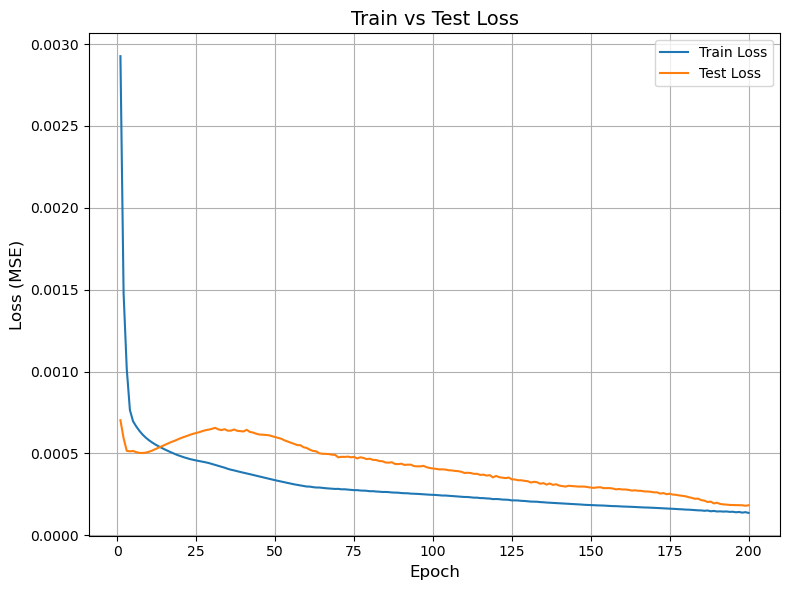

In [382]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8,6))

plt.plot(epochs, train_loss_list, label="Train Loss")
plt.plot(epochs, test_loss_list, label="Test Loss")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss (MSE)", fontsize=12)
plt.title("Train vs Test Loss", fontsize=14)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
#plt.ylim((0,max(test_loss_list)))

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
plt.show()

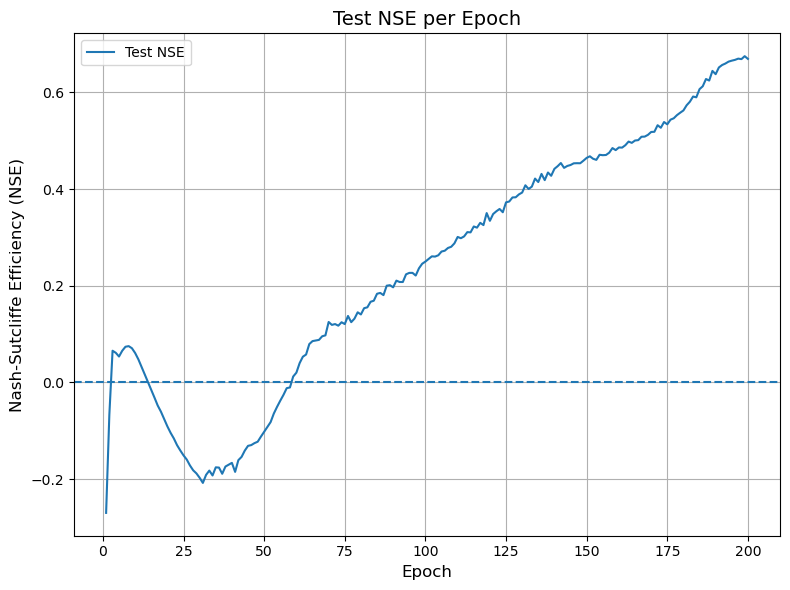

In [383]:
plt.figure(figsize=(8,6))

plt.plot(epochs, test_nse_list, label="Test NSE")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Nash-Sutcliffe Efficiency (NSE)", fontsize=12)
plt.title("Test NSE per Epoch", fontsize=14)

plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.axhline(0, linestyle="--")  # useful NSE reference

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
plt.show()

In [384]:
model.eval()

y_pred_train = []
y_pred_test = []

with torch.no_grad():

    for data in dataset_train:

        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
        else:
            out = model(data.x, data.edge_index)  # Perform a single forward pass.

        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_train.append(target_true_inv)

    for data in dataset_test:
        
        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
        else:
            out = model(data.x, data.edge_index)  # Perform a single forward pass.

        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_test.append(target_true_inv)

y_pred_train = np.array(y_pred_train)
y_pred_test = np.array(y_pred_test)

# Combine predictions
y_pred = np.concatenate([
    y_pred_train,
    y_pred_test
])

In [386]:
nse_metric(y_true_test, y_pred_test)

0.6692459353340776

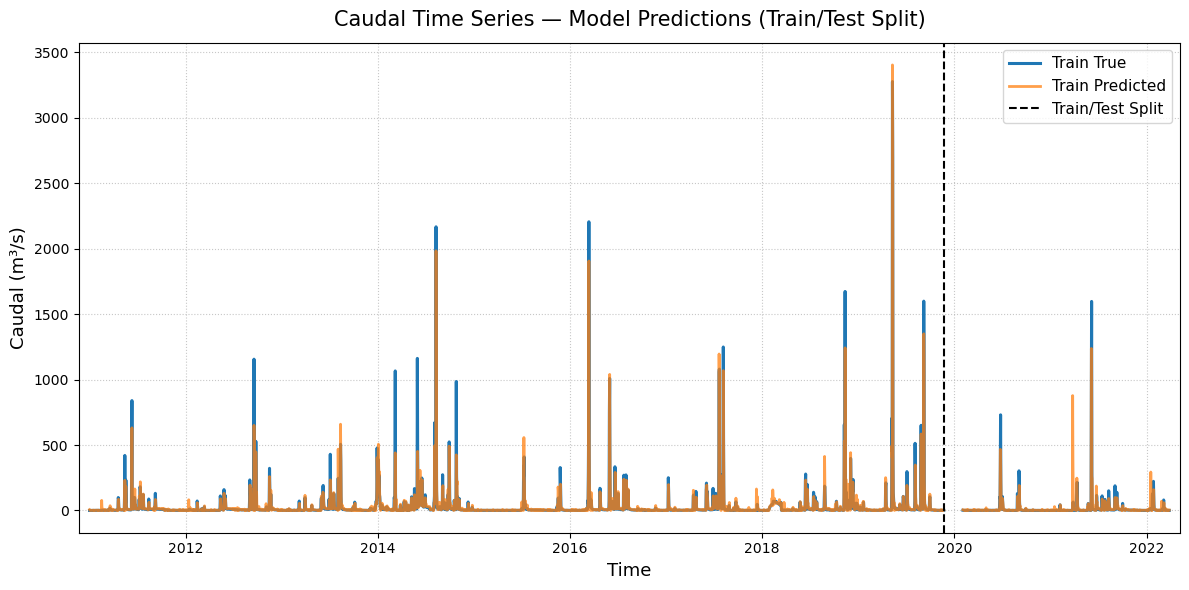

In [385]:
import numpy as np

# True values (NO SHUFFLE — keep temporal order)
y_true_all = df_data_all.loc[:, target_col].values

split_index = int(len(y_true_all) * train_ratio)

y_true_train = y_true_all[:split_index]
y_true_test = y_true_all[split_index:]

# Remove window offset (VERY IMPORTANT)
y_true_train = y_true_train[window_size:]
y_true_test = y_true_test[window_size:]

samples_train = y_true_train.size
samples_test = y_true_test.size

y_pred_train = y_pred[:samples_train].squeeze()
y_pred_test = y_pred[samples_train:].squeeze()

time = df_data_all.index

# --- Style settings
plt.figure(figsize=(12, 6))

# Colorblind-friendly colors
color_true = "#1f77b4"   # blue
color_pred = "#ff7f0e"   # orange

lw_true = 2.2
lw_pred = 2.0

# --- Training data (solid lines)

plt.plot(
    time[:samples_train],
    y_true_train,
    label="Train True",
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[:samples_train],
    y_pred_train,
    label="Train Predicted",
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75   # transparency helps overlap visibility
)

# --- Testing data (dashed lines)

plt.plot(
    time[-samples_test:],
    y_true_test,
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[-samples_test:],
    y_pred_test,
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75
)

# --- Divider line

plt.axvline(
    x=time[samples_train],
    linestyle="--",
    linewidth=1.5,
    color="black",
    label="Train/Test Split"
)

# --- Labels and formatting

plt.xlabel("Time", fontsize=13)
plt.ylabel("Caudal (m³/s)", fontsize=13)

plt.title(
    "Caudal Time Series — Model Predictions (Train/Test Split)",
    fontsize=15,
    pad=12
)

plt.legend(fontsize=11)

plt.grid(
    True,
    linestyle=":",
    linewidth=0.8,
    alpha=0.7
)

plt.margins(x=0.01)

plt.tight_layout()
plt.show()

## Graph

### Trail 4 v2: Angela, Self Loops y Weights

In [387]:
target_station = "Florida (Puente Ruta 5)"
target_variable = "Caudal (Q) [m3/s]"

all_cols = list(df_data_all.columns)
all_stations = [
    re.search(r"\[(.*?)\]", e).group(1)
    for e in all_cols
]
station_order = list(dict.fromkeys(all_stations)) # Remove duplicates from list while preserving order of elements

stations_coords = pd.read_csv(data_folder+"other_data/SL_stations.csv")

stations_coords = stations_coords[stations_coords["station"].isin(station_order)] # Keep only stations inside Florida's basin
stations_coords = stations_coords.set_index('station') # Define new index

# --- (1) Se definen las distancias ---

coords_list = [
        (stations_coords.loc[s, 'longitud'],
        stations_coords.loc[s, 'latitud'])
    for s in station_order
]

target_station_coords = [stations_coords.loc[target_station, 'longitud'],
                            stations_coords.loc[target_station, 'latitud']]

In [388]:
# --- (2) Se define la conectividad del grafo ---

# Se incorpora un self loop
edge_index = torch.tensor([
    [0, 2, 3, 4, 5, 6, 7, 1, 1, 1, 1, 1, 1],
    [0, 0, 0, 0, 0, 0, 0, 2, 3, 4, 5, 6, 7]
], dtype=torch.long)
edge_index

tensor([[0, 2, 3, 4, 5, 6, 7, 1, 1, 1, 1, 1, 1],
        [0, 0, 0, 0, 0, 0, 0, 2, 3, 4, 5, 6, 7]])

In [389]:
# --- (3) Se calculan las distancias de los nodos ---

row, col = edge_index

coords = torch.tensor(coords_list, dtype=torch.float)

distances = torch.linalg.norm(
    coords[row] - coords[col],
    dim=1
)


# ---- Prevent extremely small distances ----

min_dist = distances.quantile(0.1)  # 10th percentile
distances = torch.clamp(distances, min=min_dist)

# ---- Gaussian weighting ----

sigma = distances.mean()

weights = torch.exp(
    - (distances ** 2) / (2 * sigma ** 2)
)

# Normalize to [0,1]
weights = (weights - weights.min()) / (
    weights.max() - weights.min()
)

dist_weight = weights.view(-1, 1)
dist_weight

tensor([[1.0000],
        [0.3984],
        [1.0000],
        [0.9584],
        [0.5591],
        [0.8290],
        [0.7662],
        [0.0000],
        [0.5037],
        [0.3256],
        [0.1158],
        [0.2904],
        [0.1271]])

In [390]:
from collections import defaultdict

def extract_station(col):
    return re.match(r"\[(.*?)\]", col).group(1)

station_columns = defaultdict(list)

for col in df_data_all.columns:
    st = extract_station(col)
    station_columns[st].append(col)

In [391]:
def extract_variable(col):
    return re.sub(r"\[.*?\]\s*", "", col)

variable_order = [c.split("] ", 1)[1] for c in df_data_all.columns]
variable_order = list(dict.fromkeys(variable_order))

In [392]:
from sklearn.model_selection import train_test_split

train_ratio = 0.8
test_ratio = 0.2

# First split: train vs (val + test)
df_train, df_test = train_test_split(
    df_data_all,
    train_size=train_ratio,
    shuffle=False
)

# Second split: val vs test
# dataset_val, dataset_test = train_test_split(
#     df_data_all,
#     train_size=val_ratio / (1 - train_ratio),
#     shuffle=False
# )
#print(f"N° val samples: {len(dataset_val.index)}")

print(f"N° train samples: {len(df_train.index)}")
print(f"N° test samples: {len(df_test.index)}")


N° train samples: 3284
N° test samples: 821


In [393]:
from sklearn.preprocessing import MinMaxScaler
import pandas as pd

scalerX = MinMaxScaler()
scalerY = MinMaxScaler()

target_col = f"[{target_station}] {target_variable}"


df_train_scaled = df_train.copy()

X_train = df_train_scaled.drop(columns=[target_col])
y_train = df_train_scaled[[target_col]] 

# Fit scalers
X_train_scaled = scalerX.fit_transform(X_train)
y_train_scaled = scalerY.fit_transform(y_train)

# Assign back
df_train_scaled[X_train.columns] = X_train_scaled
df_train_scaled[target_col] = y_train_scaled


df_test_scaled = df_test.copy()

X_test = df_test_scaled.drop(columns=[target_col])
y_test = df_test_scaled[[target_col]]

# Transform only
X_test_scaled = scalerX.transform(X_test)
y_test_scaled = scalerY.transform(y_test)

# Assign back
df_test_scaled[X_test.columns] = X_test_scaled
df_test_scaled[target_col] = y_test_scaled

In [394]:
import torch
import numpy as np

num_nodes = len(station_order)
num_features = len(variable_order)
num_time_train = len(df_train_scaled)
num_time_test = len(df_test_scaled)

X_all_train = torch.zeros(
    (num_nodes, num_time_train, num_features),
    dtype=torch.float32
)

X_all_test = torch.zeros(
    (num_nodes, num_time_test, num_features),
    dtype=torch.float32
)

for i, station in enumerate(station_order):

    for j, variable in enumerate(variable_order):

        col_name = f"[{station}] {variable}"

        if col_name in df_train_scaled.columns:

            X_all_train[i, :, j] = torch.tensor(
                df_train_scaled[col_name].values,
                dtype=torch.float32
            )

            X_all_test[i, :, j] = torch.tensor(
                df_test_scaled[col_name].values,
                dtype=torch.float32
            )

        else:
            # missing variable at station
            X_all_train[i, :, j] = 0.0
            X_all_test[i, :, j] = 0.0

In [395]:
import torch
from torch_geometric.data import Data

# Return list of windowed graph data
# In this case: 
# - input_window = "window"
# - output_window = 1

def build_windowed_graphs(
    x_all,                     # [num_nodes, T, num_features]
    edge_index,                # [2, num_edges]
    edge_weight=None,          # [num_nodes, num_features]
    window=12,
    target_feature_idx=0,      # feature to predict
    target_node_idx=None       # None → predict for all nodes
):

    num_nodes, T, num_features = x_all.shape

    data_list = []

    for t in range(T - window):

        # Input window
        x_window = x_all[:, t:t+window, :].clone()  # shape: [num_nodes, window, num_features]

        # Self loop --> Use target as input (don't make feature zeros!)
        #x_window[:, :, target_feature_idx] = 0

        # Target timestep
        y_full = x_all[:, t+window, target_feature_idx]  # shape: [num_nodes]
        
        # If: 
        #   target_node_idx = None --> Predict all variables
        #   target_node_idx = idx --> Predict 'idx' variable
        if target_node_idx is not None:
            y = y_full[target_node_idx]  # shape: scalar
        else:
            y = y_full  # shape: [num_nodes]

        data = Data(
            x=x_window,
            edge_index=edge_index,
            edge_weight=edge_weight,
            y=y
        )

        data_list.append(data)

    return data_list

In [396]:
target_feature_idx = variable_order.index(target_variable) # Variable --> Feature
target_node_idx = station_order.index(target_station) # Station --> Node

edge_weight = dist_weight/dist_weight.sum() # Distance normalization --> edge weights
window_size = 36

dataset_train = build_windowed_graphs(
    X_all_train,
    edge_index,
    edge_weight,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx
)

dataset_test = build_windowed_graphs(
    X_all_test,
    edge_index,
    edge_weight,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx
)

print(f"Length train: {len(dataset_train)}")
print(f"Graph train: {dataset_train[0]}")
print(f"Length test: {len(dataset_test)}")
print(f"Graph test: {dataset_test[0]}")

Length train: 3248
Graph train: Data(x=[8, 36, 10], edge_index=[2, 13], y=4.089299181941897e-05, edge_weight=[13, 1])
Length test: 785
Graph test: Data(x=[8, 36, 10], edge_index=[2, 13], y=0.0004632504715118557, edge_weight=[13, 1])


### Model

In [398]:
import torch
import torch.nn as nn
from torch_geometric.nn import GraphConv
from torch.nn import GRU

class BasicGNN(nn.Module):

    def __init__(self, num_features, gnn_hidden, rnn_hidden, out_channels):
        super().__init__()

        self.gnn_hidden = gnn_hidden
        self.num_features = num_features

        self.gconv1 = GraphConv(num_features, gnn_hidden)
        #self.gconv2 = GraphConv(gnn_hidden, gnn_hidden)

        self.rnn = nn.GRU(
            input_size=gnn_hidden,
            hidden_size=rnn_hidden,
            batch_first=True,
        )

        self.fc = nn.Linear(
            rnn_hidden,
            out_channels
        )

    def forward(self, x, edge_index, edge_weight=None):

        # x:
        # [num_nodes, time_window, features]
        N, T, F = x.shape

        gnn_outputs = []

        # Apply conv layer to each data point independently
        for t in range(T):

            x_t = x[:, t, :]  # [num_nodes, features]

            h_t = self.gconv1(
                x_t,
                edge_index=edge_index,
                edge_weight=edge_weight
            )  # [num_nodes, gnn_hidden]
            h_t = actF.relu(h_t)

            gnn_outputs.append(h_t)

        #print(f"Len out before: {len(gnn_outputs)}")
        #print(f"out before: {gnn_outputs[0].shape}")
        
        # Stack time: [num_nodes, time_window, gnn_hidden]
        h = torch.stack(gnn_outputs, dim=1)
        
        #print(f"h stack: {h.shape}")

        # RNN
        h, _ = self.rnn(h)

        # Take last timestep
        h_last = h[:, -1, :]

        # Prediction
        out = self.fc(h_last)

        #print(f"OUT {out.shape}")

        return out.squeeze()

In [399]:
from torch_geometric.loader import DataLoader
batch_dize = 64

train_loader = DataLoader(dataset_train, batch_size=batch_dize, shuffle=False)
test_loader = DataLoader(dataset_test, batch_size=batch_dize, shuffle=False)

In [400]:
from sklearn.metrics import r2_score as nse_metric

num_features = dataset_train[0]["x"].shape[2]

model = BasicGNN(
    num_features=num_features,
    gnn_hidden=16, 
    rnn_hidden=16,
    out_channels=1
)

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)
criterion = nn.MSELoss()

def train(model, criterion, optimizer, train_loader, use_weigths):
    model.train()
    total_train_loss = 0

    for data in train_loader:

        optimizer.zero_grad()  # Clear gradients.

        # print(f"X: {data.x.shape}")
        # print(f"edge_index: {data.edge_index.shape}")
        # print(f"edge_weight: {data.edge_weight.shape}")
        # print(f"y: {data.y.shape}")

        #print(data.edge_weight)

        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
        else:
            out = model(data.x, data.edge_index)  # Perform a single forward pass.

        # out: [num_nodes x batch_size, num_features] ---> We want 'Caudal' for Node 'Florida' (slice array by num_nodes)
        target_prediction = out[target_node_idx::num_nodes]

        # print(f"target shape out: {target_prediction.shape}")
        # print(f"target out: {target_prediction}")

        train_loss = criterion(target_prediction, data.y)  # Compute the loss solely based on the training nodes.

        train_loss.backward()  # Derive gradients.
        optimizer.step()  # Update parameters based on gradients.

        total_train_loss += train_loss.item()

    return total_train_loss / len(train_loader)

def test(model, criterion, test_loader, use_weigths):
    model.eval()

    total_loss = 0.0

    all_preds_inv = []
    all_targets_inv = []

    with torch.no_grad():
        for data in test_loader:

            if use_weigths:
                out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
            else:
                out = model(data.x, data.edge_index)  # Perform a single forward pass.

            #print(out.shape)
            #print(out)

            # out: [num_nodes x batch_size, num_features] ---> We want 'Caudal' for Node 'Florida' (slice array by num_nodes)
            target_prediction = out[target_node_idx::num_nodes]

            target_prediction_inv = scalerY.inverse_transform(target_prediction.reshape(-1, 1))
            target_true_inv = scalerY.inverse_transform(data.y.reshape(-1, 1))

            # Loss (e.g., MSELoss)
            loss = criterion(target_prediction, data.y)

            total_loss += loss.item()

            # Before appending inverse pred for NSE evaluation, make negative predictions zero
            target_prediction_inv[target_prediction_inv<0] = 0
            #print(f"Despues: {(target_prediction_inv<0).sum()}")

            all_preds_inv.append(torch.from_numpy(target_prediction_inv))
            all_targets_inv.append(torch.from_numpy(target_true_inv))

    all_preds_inv = torch.cat(all_preds_inv)

    all_targets_inv = torch.cat(all_targets_inv)

    nse = nse_metric(all_targets_inv, all_preds_inv)

    avg_loss = total_loss / len(test_loader)

    return avg_loss, nse

In [401]:
num_epochs = 200

train_loss_list = []
test_loss_list = []
test_nse_list = []

use_weigths = True

for epoch in range(num_epochs):
    loss = train(model, criterion, optimizer, train_loader, use_weigths)
    test_loss, test_nse = test(model, criterion, test_loader, use_weigths)

    train_loss_list.append(loss)
    test_loss_list.append(test_loss)
    test_nse_list.append(test_nse)

    print(
        f"Epoch [{1+epoch:03d}/{num_epochs}] | "
        f"Train Loss: {loss:.6f} | "
        f"Test Loss: {test_loss:.6f} | "
        f"Test NSE: {test_nse:.2f}"
    )

if use_weigths:
    torch.save(model, 'models/BasicGNN_Arq4_weigths.pth')
else:
    torch.save(model, 'models/BasicGNN_Arq4_noweigths.pth')

Epoch [001/200] | Train Loss: 0.004992 | Test Loss: 0.000824 | Test NSE: -0.48
Epoch [002/200] | Train Loss: 0.001672 | Test Loss: 0.000597 | Test NSE: -0.09
Epoch [003/200] | Train Loss: 0.001608 | Test Loss: 0.000593 | Test NSE: -0.08
Epoch [004/200] | Train Loss: 0.001576 | Test Loss: 0.000592 | Test NSE: -0.08
Epoch [005/200] | Train Loss: 0.001542 | Test Loss: 0.000594 | Test NSE: -0.08
Epoch [006/200] | Train Loss: 0.001502 | Test Loss: 0.000595 | Test NSE: -0.08
Epoch [007/200] | Train Loss: 0.001452 | Test Loss: 0.000592 | Test NSE: -0.07
Epoch [008/200] | Train Loss: 0.001383 | Test Loss: 0.000580 | Test NSE: -0.05
Epoch [009/200] | Train Loss: 0.001291 | Test Loss: 0.000546 | Test NSE: 0.01
Epoch [010/200] | Train Loss: 0.001181 | Test Loss: 0.000485 | Test NSE: 0.12
Epoch [011/200] | Train Loss: 0.001061 | Test Loss: 0.000415 | Test NSE: 0.25
Epoch [012/200] | Train Loss: 0.000953 | Test Loss: 0.000368 | Test NSE: 0.33
Epoch [013/200] | Train Loss: 0.000873 | Test Loss: 0.00

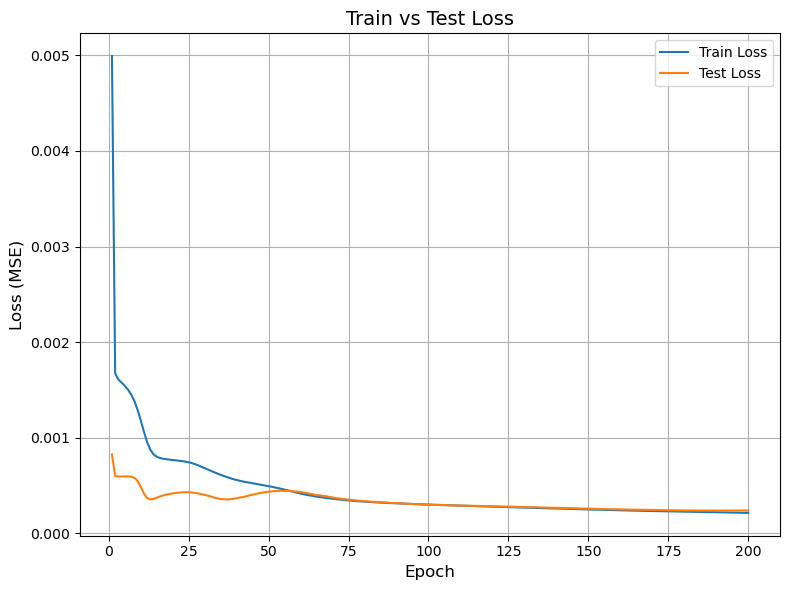

In [402]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8,6))

plt.plot(epochs, train_loss_list, label="Train Loss")
plt.plot(epochs, test_loss_list, label="Test Loss")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss (MSE)", fontsize=12)
plt.title("Train vs Test Loss", fontsize=14)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
#plt.ylim((0,max(test_loss_list)))

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
plt.show()

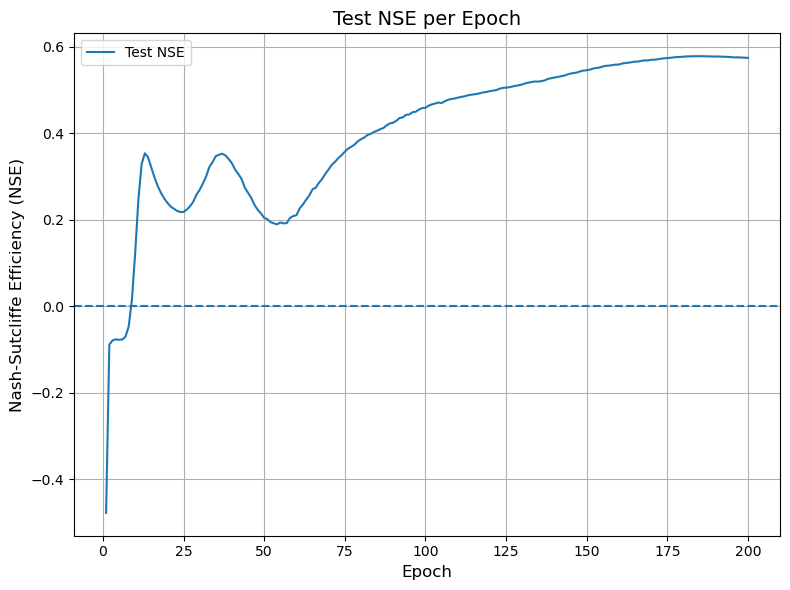

In [403]:
plt.figure(figsize=(8,6))

plt.plot(epochs, test_nse_list, label="Test NSE")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Nash-Sutcliffe Efficiency (NSE)", fontsize=12)
plt.title("Test NSE per Epoch", fontsize=14)

plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.axhline(0, linestyle="--")  # useful NSE reference

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
plt.show()

In [404]:
model.eval()

y_pred_train = []
y_pred_test = []

with torch.no_grad():

    for data in dataset_train:

        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
        else:
            out = model(data.x, data.edge_index)  # Perform a single forward pass.

        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_train.append(target_true_inv)

    for data in dataset_test:
        
        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
        else:
            out = model(data.x, data.edge_index)  # Perform a single forward pass.

        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_test.append(target_true_inv)

y_pred_train = np.array(y_pred_train)
y_pred_test = np.array(y_pred_test)

# Combine predictions
y_pred = np.concatenate([
    y_pred_train,
    y_pred_test
])

In [407]:
nse_metric(y_true_test, y_pred_test)

0.5737745949158279

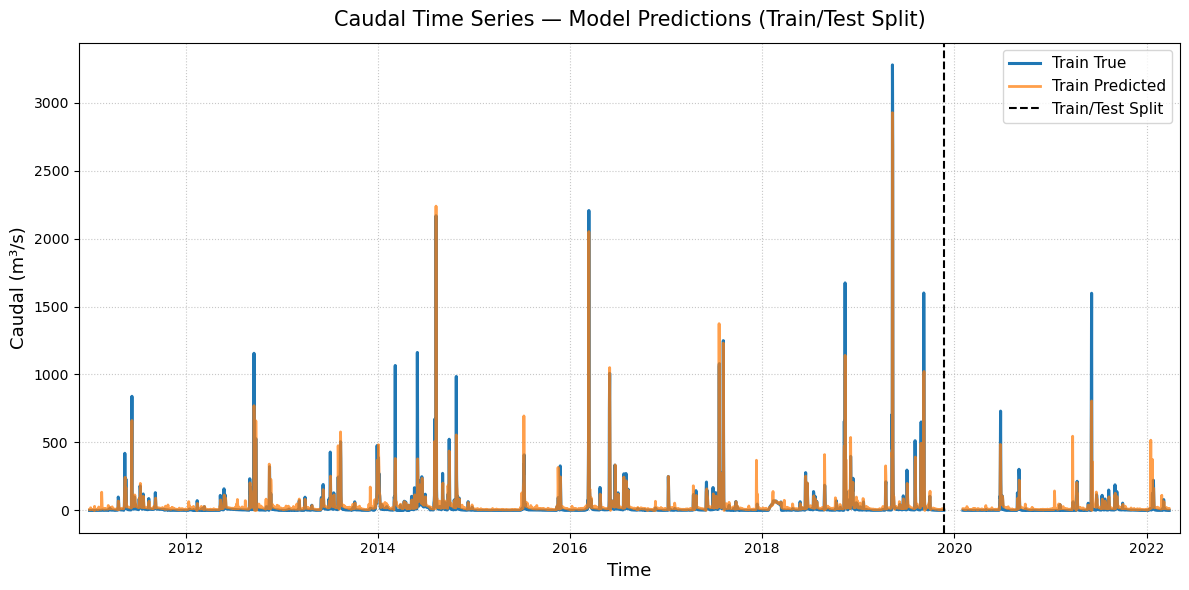

In [406]:
import numpy as np

# True values (NO SHUFFLE — keep temporal order)
y_true_all = df_data_all.loc[:, target_col].values

split_index = int(len(y_true_all) * train_ratio)

y_true_train = y_true_all[:split_index]
y_true_test = y_true_all[split_index:]

# Remove window offset (VERY IMPORTANT)
y_true_train = y_true_train[window_size:]
y_true_test = y_true_test[window_size:]

samples_train = y_true_train.size
samples_test = y_true_test.size

y_pred_train = y_pred[:samples_train].squeeze()
y_pred_test = y_pred[samples_train:].squeeze()

time = df_data_all.index

# --- Style settings
plt.figure(figsize=(12, 6))

# Colorblind-friendly colors
color_true = "#1f77b4"   # blue
color_pred = "#ff7f0e"   # orange

lw_true = 2.2
lw_pred = 2.0

# --- Training data (solid lines)

plt.plot(
    time[:samples_train],
    y_true_train,
    label="Train True",
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[:samples_train],
    y_pred_train,
    label="Train Predicted",
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75   # transparency helps overlap visibility
)

# --- Testing data (dashed lines)

plt.plot(
    time[-samples_test:],
    y_true_test,
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[-samples_test:],
    y_pred_test,
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75
)

# --- Divider line

plt.axvline(
    x=time[samples_train],
    linestyle="--",
    linewidth=1.5,
    color="black",
    label="Train/Test Split"
)

# --- Labels and formatting

plt.xlabel("Time", fontsize=13)
plt.ylabel("Caudal (m³/s)", fontsize=13)

plt.title(
    "Caudal Time Series — Model Predictions (Train/Test Split)",
    fontsize=15,
    pad=12
)

plt.legend(fontsize=11)

plt.grid(
    True,
    linestyle=":",
    linewidth=0.8,
    alpha=0.7
)

plt.margins(x=0.01)

plt.tight_layout()
plt.show()